### imports

In [1]:
import os
import re  
import math
import pickle
import zipfile
from collections import defaultdict

import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from matplotlib import cm
from matplotlib.colors import Normalize
from mpl_toolkits.mplot3d import Axes3D  

import h5py
from scipy import signal
from scipy.stats import (zscore, ks_2samp, linregress, pearsonr)
from scipy.signal import (convolve, windows, resample)
from scipy.ndimage import gaussian_filter1d

from sklearn.preprocessing import (PolynomialFeatures, StandardScaler)
from sklearn.model_selection import (train_test_split, cross_val_score, KFold)


from scipy.signal import convolve, windows
from scipy.sparse import csr_matrix
from sklearn.model_selection import train_test_split
from pyglmnet import GLM


import os
import pickle
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import KFold, GridSearchCV
from sklearn.linear_model import PoissonRegressor
from scipy.ndimage import gaussian_filter1d
from sklearn.pipeline import make_pipeline

In [ ]:
from functions_experimental_data_Bräckleinexp.GLM_analysis_spikes_pred import *
from functions_experimental_data_Bräckleinexp.GLM_analysis_force_pred import *
from functions_experimental_data_Bräckleinexp.create_rasters import *
from functions_experimental_data_Bräckleinexp.force_trajectories import *
from functions_experimental_data_Bräckleinexp.count_peaks_smoothnes import *
from functions_experimental_data_Bräckleinexp.firing_rates import *



## Load all sessions

In [23]:
session_files1 = {
    "Day01": [
        'E3_MB01_Day01High_1.pkl', 'E3_MB01_Day01High_11.pkl', 'E3_MB01_Day01High_14.pkl',
        'E3_MB01_Day01High_17.pkl', 'E3_MB01_Day01High_21.pkl', 'E3_MB01_Day01High_24.pkl',
        'E3_MB01_Day01High_27.pkl', 'E3_MB01_Day01High_30.pkl', 'E3_MB01_Day01High_6.pkl',
        'E3_MB01_Day01High_9.pkl'
    ],
    "Day03": [
        'E3_MB01_Day03High_11.pkl', 'E3_MB01_Day03High_14.pkl', 'E3_MB01_Day03High_18.pkl',
        'E3_MB01_Day03High_21.pkl', 'E3_MB01_Day03High_23.pkl', 'E3_MB01_Day03High_26.pkl',
        'E3_MB01_Day03High_29.pkl', 'E3_MB01_Day03High_3.pkl', 'E3_MB01_Day03High_4.pkl',
        'E3_MB01_Day03High_9.pkl'
    ],
    "Day04": [
        'E3_MB01_Day04High_1.pkl', 'E3_MB01_Day04High_10.pkl', 'E3_MB01_Day04High_13.pkl',
        'E3_MB01_Day04High_17.pkl', 'E3_MB01_Day04High_20.pkl', 'E3_MB01_Day04High_23.pkl',
        'E3_MB01_Day04High_25.pkl', 'E3_MB01_Day04High_29.pkl', 'E3_MB01_Day04High_30.pkl',
        'E3_MB01_Day04High_6.pkl', 'E3_MB01_Day04High_9.pkl'
    ],
    "Day05": [
        'E3_MB01_Day05High_1.pkl', 'E3_MB01_Day05High_10.pkl', 'E3_MB01_Day05High_13.pkl',
        'E3_MB01_Day05High_18.pkl', 'E3_MB01_Day05High_21.pkl', 'E3_MB01_Day05High_23.pkl',
        'E3_MB01_Day05High_26.pkl', 'E3_MB01_Day05High_28.pkl', 'E3_MB01_Day05High_5.pkl',
        'E3_MB01_Day05High_9.pkl'
    ],
    "Day06": [
        'E3_MB01_Day06High_10.pkl', 'E3_MB01_Day06High_14.pkl', 'E3_MB01_Day06High_18.pkl',
        'E3_MB01_Day06High_21.pkl', 'E3_MB01_Day06High_22.pkl', 'E3_MB01_Day06High_26.pkl',
        'E3_MB01_Day06High_3.pkl', 'E3_MB01_Day06High_30.pkl', 'E3_MB01_Day06High_5.pkl',
        'E3_MB01_Day06High_9.pkl'
    ],
    "Day07": [
        'E3_MB01_Day07High_1.pkl', 'E3_MB01_Day07High_10.pkl', 'E3_MB01_Day07High_14.pkl',
        'E3_MB01_Day07High_18.pkl', 'E3_MB01_Day07High_19.pkl', 'E3_MB01_Day07High_23.pkl',
        'E3_MB01_Day07High_26.pkl', 'E3_MB01_Day07High_28.pkl', 'E3_MB01_Day07High_5.pkl',
        'E3_MB01_Day07High_9.pkl'
        
    ],
    
    "Day08": ['E3_MB01_Day08High_12.pkl', 'E3_MB01_Day08High_13.pkl', 'E3_MB01_Day08High_17.pkl',
              'E3_MB01_Day08High_21.pkl', 'E3_MB01_Day08High_23.pkl', 'E3_MB01_Day08High_25.pkl',
              'E3_MB01_Day08High_3.pkl', 'E3_MB01_Day08High_30.pkl', 'E3_MB01_Day08High_7.pkl'],
    "Day09": ['E3_MB01_Day09High_1.pkl', 'E3_MB01_Day09High_13.pkl', 'E3_MB01_Day09High_15.pkl',
              'E3_MB01_Day09High_18.pkl', 'E3_MB01_Day09High_23.pkl', 'E3_MB01_Day09High_26.pkl',
              'E3_MB01_Day09High_27.pkl', 'E3_MB01_Day09High_4.pkl', 'E3_MB01_Day09High_8.pkl',
              'E3_MB01_Day09High_9.pkl'],
    "Day10": ['E3_MB01_Day10High_1.pkl', 'E3_MB01_Day10High_10.pkl', 'E3_MB01_Day10High_15.pkl',
              'E3_MB01_Day10High_18.pkl', 'E3_MB01_Day10High_19.pkl', 'E3_MB01_Day10High_22.pkl',
              'E3_MB01_Day10High_25.pkl', 'E3_MB01_Day10High_30.pkl', 'E3_MB01_Day10High_5.pkl',
              'E3_MB01_Day10High_7.pkl'],
    "Day11": ['E3_MB01_Day11High_12.pkl', 'E3_MB01_Day11High_15.pkl', 'E3_MB01_Day11High_18.pkl',
              'E3_MB01_Day11High_20.pkl', 'E3_MB01_Day11High_24.pkl', 'E3_MB01_Day11High_25.pkl',
              'E3_MB01_Day11High_28.pkl', 'E3_MB01_Day11High_3.pkl', 'E3_MB01_Day11High_4.pkl',
              'E3_MB01_Day11High_8.pkl'],
    "Day12": ['E3_MB01_Day12High_12.pkl', 'E3_MB01_Day12High_15.pkl', 'E3_MB01_Day12High_17.pkl',
              'E3_MB01_Day12High_2.pkl', 'E3_MB01_Day12High_20.pkl', 'E3_MB01_Day12High_24.pkl',
              'E3_MB01_Day12High_25.pkl', 'E3_MB01_Day12High_28.pkl', 'E3_MB01_Day12High_4.pkl',
              'E3_MB01_Day12High_7.pkl'],
    "Day13": ['E3_MB01_Day13High_1.pkl', 'E3_MB01_Day13High_12.pkl', 'E3_MB01_Day13High_14.pkl',
              'E3_MB01_Day13High_16.pkl', 'E3_MB01_Day13High_19.pkl', 'E3_MB01_Day13High_23.pkl',
              'E3_MB01_Day13High_25.pkl', 'E3_MB01_Day13High_30.pkl', 'E3_MB01_Day13High_5.pkl',
              'E3_MB01_Day13High_9.pkl'],
    "Day14": ['E3_MB01_Day14High_12.pkl', 'E3_MB01_Day14High_15.pkl', 'E3_MB01_Day14High_18.pkl',
              'E3_MB01_Day14High_19.pkl', 'E3_MB01_Day14High_22.pkl', 'E3_MB01_Day14High_26.pkl',
              'E3_MB01_Day14High_28.pkl', 'E3_MB01_Day14High_3.pkl', 'E3_MB01_Day14High_5.pkl',
              'E3_MB01_Day14High_8.pkl']

}



#######################





session_files3 = {
    "Day01": ['E3_MB03_Day01High_12.pkl', 'E3_MB03_Day01High_14.pkl', 'E3_MB03_Day01High_16.pkl',
              'E3_MB03_Day01High_19.pkl', 'E3_MB03_Day01High_23.pkl', 'E3_MB03_Day01High_27.pkl',
              'E3_MB03_Day01High_29.pkl', 'E3_MB03_Day01High_3.pkl', 'E3_MB03_Day01High_4.pkl',
              'E3_MB03_Day01High_8.pkl'],
    "Day02": ['E3_MB03_Day02High_12.pkl', 'E3_MB03_Day02High_15.pkl', 'E3_MB03_Day02High_17.pkl',
              'E3_MB03_Day02High_19.pkl', 'E3_MB03_Day02High_2.pkl', 'E3_MB03_Day02High_24.pkl',
              'E3_MB03_Day02High_26.pkl', 'E3_MB03_Day02High_29.pkl', 'E3_MB03_Day02High_6.pkl',
              'E3_MB03_Day02High_8.pkl'],
    "Day03": ['E3_MB03_Day03High_10.pkl', 'E3_MB03_Day03High_15.pkl', 'E3_MB03_Day03High_17.pkl',
              'E3_MB03_Day03High_2.pkl', 'E3_MB03_Day03High_21.pkl', 'E3_MB03_Day03High_23.pkl',
              'E3_MB03_Day03High_26.pkl', 'E3_MB03_Day03High_29.pkl', 'E3_MB03_Day03High_5.pkl',
              'E3_MB03_Day03High_9.pkl'],
    "Day04": ['E3_MB03_Day04High_1.pkl', 'E3_MB03_Day04High_11.pkl', 'E3_MB03_Day04High_15.pkl',
              'E3_MB03_Day04High_16.pkl', 'E3_MB03_Day04High_20.pkl', 'E3_MB03_Day04High_23.pkl',
              'E3_MB03_Day04High_26.pkl', 'E3_MB03_Day04High_28.pkl', 'E3_MB03_Day04High_4.pkl',
              'E3_MB03_Day04High_9.pkl'],
    "Day05": ['E3_MB03_Day05High_12.pkl', 'E3_MB03_Day05High_15.pkl', 'E3_MB03_Day05High_17.pkl',
              'E3_MB03_Day05High_20.pkl', 'E3_MB03_Day05High_22.pkl', 'E3_MB03_Day05High_26.pkl',
              'E3_MB03_Day05High_29.pkl', 'E3_MB03_Day05High_3.pkl', 'E3_MB03_Day05High_4.pkl',
              'E3_MB03_Day05High_7.pkl'],
    "Day07": ['E3_MB03_Day07High_11.pkl', 'E3_MB03_Day07High_13.pkl', 'E3_MB03_Day07High_18.pkl',
              'E3_MB03_Day07High_19.pkl', 'E3_MB03_Day07High_22.pkl', 'E3_MB03_Day07High_27.pkl',
              'E3_MB03_Day07High_29.pkl', 'E3_MB03_Day07High_3.pkl', 'E3_MB03_Day07High_7.pkl'],
    "Day10": ['E3_MB03_Day10High_12.pkl', 'E3_MB03_Day10High_13.pkl', 'E3_MB03_Day10High_17.pkl',
              'E3_MB03_Day10High_21.pkl', 'E3_MB03_Day10High_22.pkl', 'E3_MB03_Day10High_25.pkl',
              'E3_MB03_Day10High_3.pkl', 'E3_MB03_Day10High_30.pkl', 'E3_MB03_Day10High_5.pkl',
              'E3_MB03_Day10High_8.pkl'],
    "Day11": ['E3_MB03_Day11High_10.pkl', 'E3_MB03_Day11High_14.pkl', 'E3_MB03_Day11High_18.pkl',
              'E3_MB03_Day11High_20.pkl', 'E3_MB03_Day11High_23.pkl', 'E3_MB03_Day11High_26.pkl',
              'E3_MB03_Day11High_3.pkl', 'E3_MB03_Day11High_30.pkl', 'E3_MB03_Day11High_6.pkl',
              'E3_MB03_Day11High_9.pkl'],
    "Day12": ['E3_MB03_Day12High_12.pkl', 'E3_MB03_Day12High_13.pkl', 'E3_MB03_Day12High_17.pkl',
              'E3_MB03_Day12High_21.pkl', 'E3_MB03_Day12High_22.pkl', 'E3_MB03_Day12High_25.pkl',
              'E3_MB03_Day12High_29.pkl', 'E3_MB03_Day12High_3.pkl', 'E3_MB03_Day12High_5.pkl',
              'E3_MB03_Day12High_8.pkl'],
    "Day13": ['E3_MB03_Day13High_12.pkl', 'E3_MB03_Day13High_13.pkl', 'E3_MB03_Day13High_18.pkl',
              'E3_MB03_Day13High_19.pkl', 'E3_MB03_Day13High_2.pkl', 'E3_MB03_Day13High_24.pkl',
              'E3_MB03_Day13High_27.pkl', 'E3_MB03_Day13High_29.pkl', 'E3_MB03_Day13High_5.pkl',
              'E3_MB03_Day13High_7.pkl'],
    "Day14": ['E3_MB03_Day14High_12.pkl', 'E3_MB03_Day14High_13.pkl', 'E3_MB03_Day14High_16.pkl',
              'E3_MB03_Day14High_21.pkl', 'E3_MB03_Day14High_24.pkl', 'E3_MB03_Day14High_26.pkl',
              'E3_MB03_Day14High_29.pkl', 'E3_MB03_Day14High_3.pkl', 'E3_MB03_Day14High_4.pkl',
              'E3_MB03_Day14High_8.pkl']
}


#######################



session_files2 = {
    "Day02": [
        'E3_MB02_Day02High_10.pkl', 'E3_MB02_Day02High_14.pkl', 'E3_MB02_Day02High_18.pkl',
        'E3_MB02_Day02High_2.pkl', 'E3_MB02_Day02High_20.pkl', 'E3_MB02_Day02High_24.pkl',
        'E3_MB02_Day02High_27.pkl', 'E3_MB02_Day02High_29.pkl', 'E3_MB02_Day02High_6.pkl',
        'E3_MB02_Day02High_9.pkl'
    ],
    "Day03": [
        'E3_MB02_Day03High_11.pkl', 'E3_MB02_Day03High_13.pkl', 'E3_MB02_Day03High_18.pkl',
        'E3_MB02_Day03High_21.pkl', 'E3_MB02_Day03High_24.pkl', 'E3_MB02_Day03High_26.pkl',
        'E3_MB02_Day03High_29.pkl', 'E3_MB02_Day03High_3.pkl', 'E3_MB02_Day03High_5.pkl',
        'E3_MB02_Day03High_7.pkl'
    ],
    "Day04": [
        'E3_MB02_Day04High_11.pkl', 'E3_MB02_Day04High_14.pkl', 'E3_MB02_Day04High_16.pkl',
        'E3_MB02_Day04High_2.pkl', 'E3_MB02_Day04High_21.pkl', 'E3_MB02_Day04High_22.pkl',
        'E3_MB02_Day04High_27.pkl', 'E3_MB02_Day04High_30.pkl', 'E3_MB02_Day04High_5.pkl',
        'E3_MB02_Day04High_7.pkl'
    ],
    "Day07": [
        'E3_MB02_Day07High_1.pkl', 'E3_MB02_Day07High_12.pkl', 'E3_MB02_Day07High_13.pkl',
        'E3_MB02_Day07High_16.pkl', 'E3_MB02_Day07High_19.pkl', 'E3_MB02_Day07High_24.pkl',
        'E3_MB02_Day07High_27.pkl', 'E3_MB02_Day07High_30.pkl', 'E3_MB02_Day07High_4.pkl',
        'E3_MB02_Day07High_9.pkl'
    ],
    "Day13": [
        'E3_MB02_Day13High_1.pkl', 'E3_MB02_Day13High_11.pkl', 'E3_MB02_Day13High_13.pkl',
        'E3_MB02_Day13High_18.pkl', 'E3_MB02_Day13High_20.pkl', 'E3_MB02_Day13High_23.pkl',
        'E3_MB02_Day13High_26.pkl', 'E3_MB02_Day13High_28.pkl', 'E3_MB02_Day13High_4.pkl',
        'E3_MB02_Day13High_8.pkl'
    ]
}



#######################




session_files4 = {
    "Day01": ['E3_MB04_Day01High_16.pkl', 'E3_MB04_Day01High_19.pkl', 'E3_MB04_Day01High_2.pkl',
              'E3_MB04_Day01High_24.pkl', 'E3_MB04_Day01High_26.pkl', 'E3_MB04_Day01High_30.pkl',
              'E3_MB04_Day01High_6.pkl', 'E3_MB04_Day01High_8.pkl'],
    "Day03": ['E3_MB04_Day03High_10.pkl', 'E3_MB04_Day03High_14.pkl', 'E3_MB04_Day03High_17.pkl',
              'E3_MB04_Day03High_19.pkl', 'E3_MB04_Day03High_22.pkl', 'E3_MB04_Day03High_27.pkl',
              'E3_MB04_Day03High_28.pkl', 'E3_MB04_Day03High_3.pkl', 'E3_MB04_Day03High_5.pkl',
              'E3_MB04_Day03High_8.pkl'],
    "Day07": ['E3_MB04_Day07High_15.pkl', 'E3_MB04_Day07High_29.pkl', 'E3_MB04_Day07High_6.pkl',
              'E3_MB04_Day07High_8.pkl'],
    "Day08": ['E3_MB04_Day08High_11.pkl', 'E3_MB04_Day08High_13.pkl', 'E3_MB04_Day08High_18.pkl',
              'E3_MB04_Day08High_19.pkl', 'E3_MB04_Day08High_2.pkl', 'E3_MB04_Day08High_22.pkl',
              'E3_MB04_Day08High_27.pkl', 'E3_MB04_Day08High_28.pkl', 'E3_MB04_Day08High_6.pkl',
              'E3_MB04_Day08High_9.pkl'],
    "Day09": ['E3_MB04_Day09High_1.pkl', 'E3_MB04_Day09High_19.pkl', 'E3_MB04_Day09High_24.pkl',
              'E3_MB04_Day09High_27.pkl', 'E3_MB04_Day09High_30.pkl', 'E3_MB04_Day09High_6.pkl'],
    "Day10": ['E3_MB04_Day10High_11.pkl', 'E3_MB04_Day10High_15.pkl', 'E3_MB04_Day10High_17.pkl',
              'E3_MB04_Day10High_2.pkl', 'E3_MB04_Day10High_21.pkl', 'E3_MB04_Day10High_22.pkl',
              'E3_MB04_Day10High_26.pkl', 'E3_MB04_Day10High_28.pkl', 'E3_MB04_Day10High_4.pkl',
              'E3_MB04_Day10High_9.pkl'],
    "Day11": ['E3_MB04_Day11High_10.pkl', 'E3_MB04_Day11High_14.pkl', 'E3_MB04_Day11High_16.pkl',
              'E3_MB04_Day11High_2.pkl', 'E3_MB04_Day11High_21.pkl', 'E3_MB04_Day11High_23.pkl',
              'E3_MB04_Day11High_27.pkl', 'E3_MB04_Day11High_28.pkl', 'E3_MB04_Day11High_4.pkl',
              'E3_MB04_Day11High_9.pkl'],
    
    "Day12": ['E3_MB04_Day12High_2.pkl', 'E3_MB04_Day12High_5.pkl', 'E3_MB04_Day12High_9.pkl',
              'E3_MB04_Day12High_12.pkl', 'E3_MB04_Day12High_14.pkl', 'E3_MB04_Day12High_18.pkl',
              'E3_MB04_Day12High_19.pkl', 'E3_MB04_Day12High_23.pkl', 'E3_MB04_Day12High_26.pkl',
              'E3_MB04_Day12High_29.pkl'],
        
    "Day13": ['E3_MB04_Day13High_3.pkl', 'E3_MB04_Day13High_4.pkl', 'E3_MB04_Day13High_8.pkl',
              'E3_MB04_Day13High_12.pkl', 'E3_MB04_Day13High_14.pkl', 'E3_MB04_Day13High_18.pkl',
              'E3_MB04_Day13High_19.pkl', 'E3_MB04_Day13High_24.pkl', 'E3_MB04_Day13High_27.pkl',
              'E3_MB04_Day13High_30.pkl'],
            
    "Day14": ['E3_MB04_Day14High_3.pkl', 'E3_MB04_Day14High_4.pkl', 'E3_MB04_Day14High_8.pkl',
              'E3_MB04_Day14High_11.pkl', 'E3_MB04_Day14High_13.pkl', 'E3_MB04_Day14High_18.pkl',
              'E3_MB04_Day14High_21.pkl', 'E3_MB04_Day14High_25.pkl', 'E3_MB04_Day14High_28.pkl']
}



#######################



session_files7 = {
    "Day01": [
        'E3_MB07_Day01High_10.pkl', 'E3_MB07_Day01High_13.pkl', 'E3_MB07_Day01High_17.pkl',
        'E3_MB07_Day01High_2.pkl', 'E3_MB07_Day01High_21.pkl', 'E3_MB07_Day01High_24.pkl',
        'E3_MB07_Day01High_26.pkl', 'E3_MB07_Day01High_28.pkl', 'E3_MB07_Day01High_5.pkl',
        'E3_MB07_Day01High_9.pkl'
    ],
    "Day02": [
        'E3_MB07_Day02High_10.pkl', 'E3_MB07_Day02High_15.pkl', 'E3_MB07_Day02High_17.pkl',
        'E3_MB07_Day02High_19.pkl', 'E3_MB07_Day02High_23.pkl', 'E3_MB07_Day02High_27.pkl',
        'E3_MB07_Day02High_3.pkl', 'E3_MB07_Day02High_30.pkl', 'E3_MB07_Day02High_5.pkl',
        'E3_MB07_Day02High_9.pkl'
    ],
    "Day03": [
        'E3_MB07_Day03High_1.pkl', 'E3_MB07_Day03High_10.pkl', 'E3_MB07_Day03High_15.pkl',
        'E3_MB07_Day03High_18.pkl', 'E3_MB07_Day03High_19.pkl', 'E3_MB07_Day03High_22.pkl',
        'E3_MB07_Day03High_25.pkl', 'E3_MB07_Day03High_30.pkl', 'E3_MB07_Day03High_5.pkl',
        'E3_MB07_Day03High_7.pkl'
    ],
    "Day04": [
        'E3_MB07_Day04High_11.pkl', 'E3_MB07_Day04High_15.pkl', 'E3_MB07_Day04High_18.pkl',
        'E3_MB07_Day04High_21.pkl', 'E3_MB07_Day04High_23.pkl', 'E3_MB07_Day04High_27.pkl',
        'E3_MB07_Day04High_28.pkl', 'E3_MB07_Day04High_3.pkl', 'E3_MB07_Day04High_6.pkl',
        'E3_MB07_Day04High_7.pkl'
    ],
    "Day05": [
        'E3_MB07_Day05High_12.pkl', 'E3_MB07_Day05High_15.pkl', 'E3_MB07_Day05High_16.pkl',
        'E3_MB07_Day05High_19.pkl', 'E3_MB07_Day05High_24.pkl', 'E3_MB07_Day05High_26.pkl',
        'E3_MB07_Day05High_3.pkl', 'E3_MB07_Day05High_30.pkl', 'E3_MB07_Day05High_5.pkl',
        'E3_MB07_Day05High_7.pkl'
    ],
    "Day06": [
        'E3_MB07_Day06High_10.pkl', 'E3_MB07_Day06High_15.pkl', 'E3_MB07_Day06High_16.pkl',
        'E3_MB07_Day06High_19.pkl', 'E3_MB07_Day06High_24.pkl', 'E3_MB07_Day06High_25.pkl',
        'E3_MB07_Day06High_29.pkl', 'E3_MB07_Day06High_3.pkl', 'E3_MB07_Day06High_6.pkl',
        'E3_MB07_Day06High_8.pkl'
    ],
    "Day07": [
        'E3_MB07_Day07High_1.pkl', 'E3_MB07_Day07High_10.pkl', 'E3_MB07_Day07High_13.pkl',
        'E3_MB07_Day07High_18.pkl', 'E3_MB07_Day07High_20.pkl', 'E3_MB07_Day07High_24.pkl',
        'E3_MB07_Day07High_26.pkl', 'E3_MB07_Day07High_29.pkl', 'E3_MB07_Day07High_6.pkl',
        'E3_MB07_Day07High_9.pkl'
    ],
    "Day08": [
        'E3_MB07_Day08High_12.pkl', 'E3_MB07_Day08High_13.pkl', 'E3_MB07_Day08High_17.pkl',
        'E3_MB07_Day08High_2.pkl', 'E3_MB07_Day08High_20.pkl', 'E3_MB07_Day08High_24.pkl',
        'E3_MB07_Day08High_26.pkl', 'E3_MB07_Day08High_28.pkl', 'E3_MB07_Day08High_4.pkl',
        'E3_MB07_Day08High_9.pkl'
    ],
    "Day09": [
        'E3_MB07_Day09High_10.pkl', 'E3_MB07_Day09High_12.pkl', 'E3_MB07_Day09High_13.pkl',
        'E3_MB07_Day09High_14.pkl', 'E3_MB07_Day09High_18.pkl', 'E3_MB07_Day09High_19.pkl',
        'E3_MB07_Day09High_2.pkl', 'E3_MB07_Day09High_21.pkl', 'E3_MB07_Day09High_22.pkl',
        'E3_MB07_Day09High_23.pkl', 'E3_MB07_Day09High_25.pkl', 'E3_MB07_Day09High_28.pkl',
        'E3_MB07_Day09High_3.pkl', 'E3_MB07_Day09High_30.pkl', 'E3_MB07_Day09High_4.pkl',
        'E3_MB07_Day09High_6.pkl', 'E3_MB07_Day09High_9.pkl'
    ],
    "Day10": [
        'E3_MB07_Day10High_10.pkl', 'E3_MB07_Day10High_13.pkl', 'E3_MB07_Day10High_16.pkl',
        'E3_MB07_Day10High_2.pkl', 'E3_MB07_Day10High_21.pkl', 'E3_MB07_Day10High_22.pkl',
        'E3_MB07_Day10High_26.pkl', 'E3_MB07_Day10High_29.pkl', 'E3_MB07_Day10High_4.pkl',
        'E3_MB07_Day10High_9.pkl'
    ]
}


#######################



session_files6 = {
    "Day01": [
        'E3_MB06_Day01High_10.pkl', 'E3_MB06_Day01High_13.pkl', 'E3_MB06_Day01High_16.pkl',
        'E3_MB06_Day01High_2.pkl', 'E3_MB06_Day01High_21.pkl', 'E3_MB06_Day01High_22.pkl',
        'E3_MB06_Day01High_27.pkl', 'E3_MB06_Day01High_28.pkl', 'E3_MB06_Day01High_6.pkl',
        'E3_MB06_Day01High_7.pkl'
    ],
    "Day03": [
        'E3_MB06_Day03High_1.pkl', 'E3_MB06_Day03High_10.pkl', 'E3_MB06_Day03High_14.pkl',
        'E3_MB06_Day03High_17.pkl', 'E3_MB06_Day03High_21.pkl', 'E3_MB06_Day03High_22.pkl',
        'E3_MB06_Day03High_27.pkl', 'E3_MB06_Day03High_29.pkl', 'E3_MB06_Day03High_6.pkl',
        'E3_MB06_Day03High_8.pkl'
    ],
    "Day04": [
        'E3_MB06_Day04High_10.pkl', 'E3_MB06_Day04High_14.pkl', 'E3_MB06_Day04High_17.pkl',
        'E3_MB06_Day04High_21.pkl', 'E3_MB06_Day04High_24.pkl', 'E3_MB06_Day04High_26.pkl',
        'E3_MB06_Day04High_3.pkl', 'E3_MB06_Day04High_30.pkl', 'E3_MB06_Day04High_5.pkl',
        'E3_MB06_Day04High_9.pkl'
    ],
    "Day05": [
        'E3_MB06_Day05High_1.pkl', 'E3_MB06_Day05High_12.pkl', 'E3_MB06_Day05High_13.pkl',
        'E3_MB06_Day05High_18.pkl', 'E3_MB06_Day05High_20.pkl', 'E3_MB06_Day05High_24.pkl',
        'E3_MB06_Day05High_27.pkl', 'E3_MB06_Day05High_29.pkl', 'E3_MB06_Day05High_5.pkl',
        'E3_MB06_Day05High_8.pkl'
    ],
    "Day06": [
        'E3_MB06_Day06High_1.pkl', 'E3_MB06_Day06High_12.pkl', 'E3_MB06_Day06High_14.pkl',
        'E3_MB06_Day06High_18.pkl', 'E3_MB06_Day06High_20.pkl', 'E3_MB06_Day06High_23.pkl',
        'E3_MB06_Day06High_27.pkl', 'E3_MB06_Day06High_29.pkl', 'E3_MB06_Day06High_4.pkl',
        'E3_MB06_Day06High_9.pkl'
    ],
    "Day07": [
        'E3_MB06_Day07High_1.pkl', 'E3_MB06_Day07High_10.pkl', 'E3_MB06_Day07High_15.pkl',
        'E3_MB06_Day07High_16.pkl', 'E3_MB06_Day07High_21.pkl', 'E3_MB06_Day07High_22.pkl',
        'E3_MB06_Day07High_26.pkl', 'E3_MB06_Day07High_28.pkl', 'E3_MB06_Day07High_6.pkl',
        'E3_MB06_Day07High_9.pkl'
    ],
    "Day08": [
        'E3_MB06_Day08High_12.pkl', 'E3_MB06_Day08High_14.pkl', 'E3_MB06_Day08High_18.pkl',
        'E3_MB06_Day08High_19.pkl', 'E3_MB06_Day08High_2.pkl', 'E3_MB06_Day08High_23.pkl',
        'E3_MB06_Day08High_26.pkl', 'E3_MB06_Day08High_29.pkl', 'E3_MB06_Day08High_4.pkl',
        'E3_MB06_Day08High_8.pkl'
    ],
    "Day09": [
        'E3_MB06_Day09High_1.pkl', 'E3_MB06_Day09High_11.pkl', 'E3_MB06_Day09High_14.pkl',
        'E3_MB06_Day09High_16.pkl', 'E3_MB06_Day09High_20.pkl', 'E3_MB06_Day09High_22.pkl',
        'E3_MB06_Day09High_27.pkl', 'E3_MB06_Day09High_30.pkl', 'E3_MB06_Day09High_6.pkl',
        'E3_MB06_Day09High_8.pkl'
    ],
    "Day10": [
        'E3_MB06_Day10High_10.pkl', 'E3_MB06_Day10High_14.pkl', 'E3_MB06_Day10High_17.pkl',
        'E3_MB06_Day10High_19.pkl', 'E3_MB06_Day10High_23.pkl', 'E3_MB06_Day10High_26.pkl',
        'E3_MB06_Day10High_29.pkl', 'E3_MB06_Day10High_3.pkl', 'E3_MB06_Day10High_6.pkl',
        'E3_MB06_Day10High_9.pkl'
    ],
    "Day11": [
        'E3_MB06_Day11High_11.pkl', 'E3_MB06_Day11High_15.pkl', 'E3_MB06_Day11High_16.pkl',
        'E3_MB06_Day11High_19.pkl', 'E3_MB06_Day11High_23.pkl', 'E3_MB06_Day11High_27.pkl',
        'E3_MB06_Day11High_29.pkl', 'E3_MB06_Day11High_3.pkl', 'E3_MB06_Day11High_6.pkl',
        'E3_MB06_Day11High_9.pkl'
    ],
    "Day12": [
        'E3_MB06_Day12High_10.pkl', 'E3_MB06_Day12High_14.pkl', 'E3_MB06_Day12High_16.pkl',
        'E3_MB06_Day12High_21.pkl', 'E3_MB06_Day12High_24.pkl', 'E3_MB06_Day12High_25.pkl',
        'E3_MB06_Day12High_3.pkl', 'E3_MB06_Day12High_30.pkl', 'E3_MB06_Day12High_5.pkl',
        'E3_MB06_Day12High_9.pkl'
    ],
    "Day13": [
        'E3_MB06_Day13High_12.pkl', 'E3_MB06_Day13High_13.pkl', 'E3_MB06_Day13High_17.pkl',
        'E3_MB06_Day13High_20.pkl', 'E3_MB06_Day13High_23.pkl', 'E3_MB06_Day13High_25.pkl',
        'E3_MB06_Day13High_3.pkl', 'E3_MB06_Day13High_30.pkl', 'E3_MB06_Day13High_6.pkl',
        'E3_MB06_Day13High_8.pkl'
    ],
    "Day14": [
        'E3_MB06_Day14High_11.pkl', 'E3_MB06_Day14High_15.pkl', 'E3_MB06_Day14High_16.pkl',
        'E3_MB06_Day14High_2.pkl', 'E3_MB06_Day14High_20.pkl', 'E3_MB06_Day14High_23.pkl',
        'E3_MB06_Day14High_26.pkl', 'E3_MB06_Day14High_28.pkl', 'E3_MB06_Day14High_6.pkl',
        'E3_MB06_Day14High_9.pkl'
    ]
}


## Scale experimental forces to use them as inputs to the model 

Global maximum force (before scaling): 0.0772
Scaling factor to apply: 5.1787
Saved scaled force for 2 to /Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Data_final/Scaled_force/S2/avg_force_Day_2_scaled04.npy
Saved scaled force for 3 to /Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Data_final/Scaled_force/S2/avg_force_Day_3_scaled04.npy
Saved scaled force for 4 to /Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Data_final/Scaled_force/S2/avg_force_Day_4_scaled04.npy
Saved scaled force for 7 to /Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Data_final/Scaled_force/S2/avg_force_Day_7_scaled04.npy
Saved scaled force for 13 to /Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Data_final/Scaled_force/S2/avg_force_Day_13_scaled04.npy


/var/folders/xt/z8_l6n9d1wv6vpcb5vdsp1dr0000gq/T/ipykernel_1111/3132148797.py:97: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  cmap = cm.get_cmap("tab10")


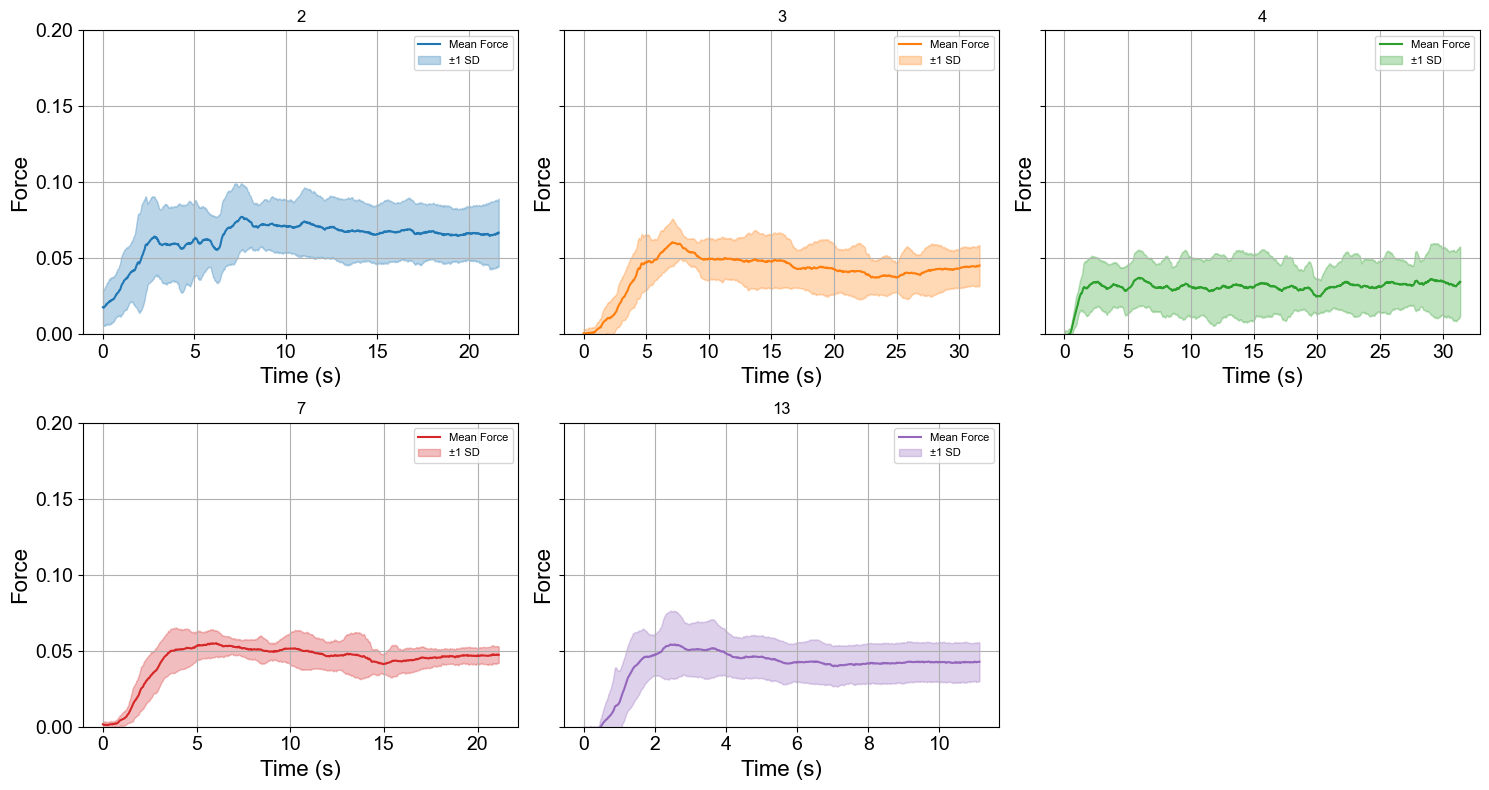

In [71]:
compute_and_save_avg_force(
    directory_path="/Users/nmt121/Desktop/DATA/S2",
    save_dir="/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Data_final/Scaled_force/S2/",
    file_prefix="avg_force_Day",
    target_max=0.4
)


In [110]:
# import matplotlib.pyplot as plt
# import matplotlib.cm as cm

# # Define the days you want to plot
# days_to_plot = ["Day01", "Day14"]

# # Create figure with 2 vertical subplots
# fig, axes = plt.subplots(2, 1, figsize=(10, 8), sharex=False)

# cmap = cm.get_cmap("tab10")

# for i, day in enumerate(days_to_plot):
#     if day in average_force_by_day:
#         mean = average_force_by_day[day]['mean']
#         std = average_force_by_day[day]['std']
#         t = time_by_day[day]
#         color = cmap(i % 10)

#         ax = axes[i]
#         ax.plot(t, mean, color=color, label='Mean Force')
#         ax.fill_between(t, mean - std, mean + std, color=color, alpha=0.3, label='±1 SD')
#         ax.set_title(f"{day}", fontsize=14)
#         ax.set_xlabel("Time (s)")
#         ax.set_ylabel("Force")
#         ax.grid(False)
#         ax.set_ylim([0,0.2])
#         # ax.legend(fontsize=10)

#         # Remove top and right spines
#         ax.spines['top'].set_visible(False)
#         ax.spines['right'].set_visible(False)
#     else:
#         print(f"{day} not found in data.")

# plt.tight_layout()

# # Save the figure
# fig_path = "/Users/nmt121/Desktop/force_profiles_Day01_Day14.pdf"
# fig.savefig(fig_path, dpi=300)
# print(f"Figure saved: {fig_path}")

# plt.show()

# "/Users/nmt121/Desktop/day14.pdf"

[15.19688238 15.10551426 14.97622524 15.35450851 15.38381115 14.87290427
 14.97106841 15.26203569 15.26591884 14.92121148 15.18066494 14.9802635
 15.07056793 14.90761794 14.93908588 14.44358351 14.64730632 14.8395752
 14.31714742 15.00420118 14.54676335 14.49319122 14.47003497 15.54259501
 14.5016201  14.79312271 14.22805323 15.59781631 14.88979297 14.75725816
 14.15566716 14.22943846 14.11856591 15.70712258 14.81603424 15.2321776
 13.66274051 13.77668296 13.85010275 14.04759567 14.56095712 15.30543343
 15.56973123 13.59064963 13.88616365 12.71513555 15.06954595 13.39121145
 15.10653887 13.50641555 15.19253911 15.12859304 14.09753066 15.21577017
 14.9188505  15.57608844 14.22830373 12.30686108 15.13649333 14.1429947
 11.12033574 11.42728264 10.14099003 11.41869812 15.47603843 11.57694534
 16.62636034 10.13861146 15.89391944 10.13684744 14.26287224 10.91060233
 11.92776905 13.37081212 13.79111761 12.207344   10.14074657  9.92745988
 12.80078024 10.82870063 10.69997106 14.52311975 10.123

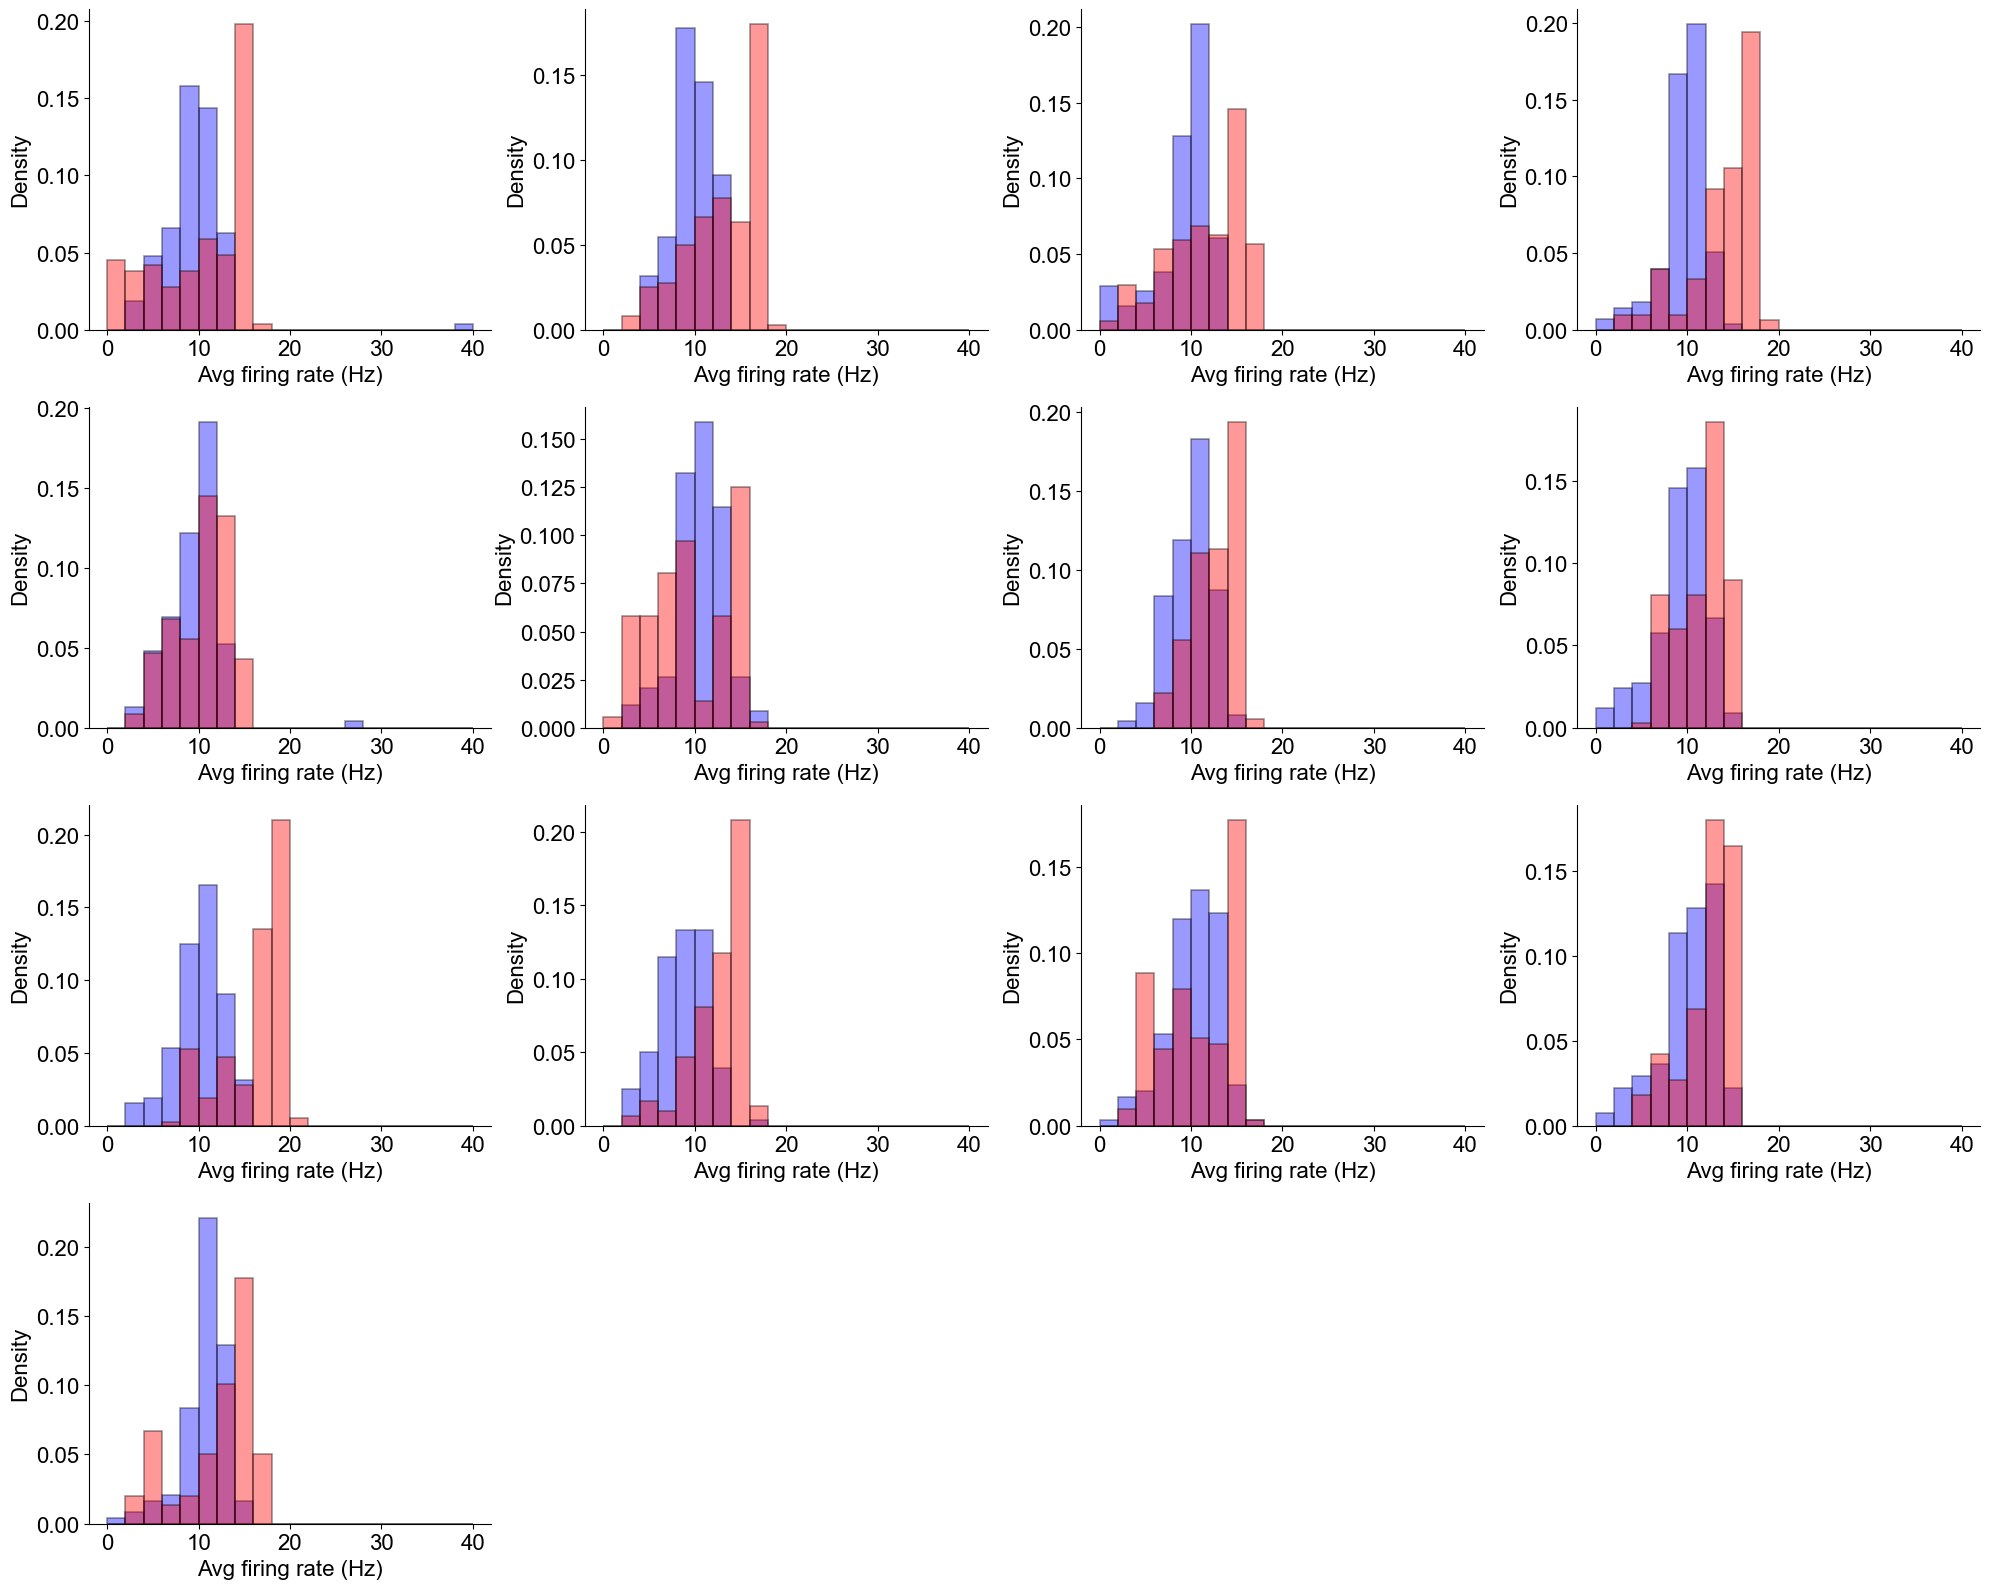

In [77]:
import os
import re
import pickle
import h5py
import numpy as np
import matplotlib.pyplot as plt



def extract_day(filename):
    match = re.search(r"(Day\d{2})", filename)
    return int(match.group(1)[3:]) if match else None

def extract_trial(filename):
    match = re.search(r'_(\d+)[^0-9]', filename)
    return int(match.group(1)) if match else 0

def compute_avg_firing_rate(spike_times, sampling_rate):
    if len(spike_times) < 2:
        return None
    ISIs = np.diff(spike_times) / sampling_rate
    return 1 / np.mean(ISIs)

def load_simulated_rates(jld2_file_paths):
    sim_rates_by_day = {}
    for path in jld2_file_paths:
        day_match = re.search(r'force(\d+)_firing_rates\.jld2', path)
        if not day_match:
            continue
        day = int(day_match.group(1))

        with h5py.File(path, 'r') as f:
            if 'avg_rates_per_neuron' in f:
                rates = f['avg_rates_per_neuron'][:]
                sim_rates_by_day[day] = rates
                print(sim_rates_by_day[day])
            else:
                print(f"'avg_rates_per_neuron' not found in {path}")
    return sim_rates_by_day

def compute_firing_rate_histograms_with_sim(folder_path, Fsamp, jld2_file_paths):
    sim_data = load_simulated_rates(jld2_file_paths)
    pkl_files = sorted(
        [f for f in os.listdir(folder_path) if f.endswith('.pkl')],
        key=lambda x: (extract_day(x), extract_trial(x))
    )
    day_files = {}
    for file in pkl_files:
        day = extract_day(file)
        if day is not None:
            day_files.setdefault(day, []).append(file)

    n_days = len(day_files)
    n_cols = 4
    n_rows = int(np.ceil(n_days / n_cols))
    fig, axes = plt.subplots(n_rows, n_cols, figsize=(5 * n_cols, 4 * n_rows))
    axes = axes.flatten()

    for i, (day, files) in enumerate(sorted(day_files.items())):
        all_firing_rates = []
        for file in files:
            with open(os.path.join(folder_path, file), 'rb') as f:
                data = pickle.load(f)
            MU_array = np.array(data['MU'])

            for neuron_idx in range(MU_array.shape[0]):
                spike_times = np.where(MU_array[neuron_idx] == 1)[0]
                fr = compute_avg_firing_rate(spike_times, Fsamp)
                if fr is not None and fr <= 80:
                    all_firing_rates.append(fr)

        ax = axes[i]
        bin_edges = np.linspace(0, 40, 21)

        ax.hist(all_firing_rates, bins=bin_edges, color='blue', alpha=0.4,
                label='Experimental', density=True, edgecolor='black', linewidth=1.2)

        if day in sim_data:
            ax.hist(sim_data[day], bins=bin_edges, color='red', alpha=0.4,
                    label='Simulated', density=True, edgecolor='black', linewidth=1.2)

        # ax.set_title(f'Day {day}: {len(all_firing_rates)} neurons')  # Title removed
        ax.set_xlabel('Avg firing rate (Hz)', fontsize=16)
        ax.set_ylabel('Density', fontsize=16)

        # Remove legend
        # ax.legend()

        # Remove top and right spines
        ax.spines['right'].set_visible(False)
        ax.spines['top'].set_visible(False)

        # Make ticks bigger
        ax.tick_params(axis='both', which='major', labelsize=16)

    for j in range(i + 1, len(axes)):
        fig.delaxes(axes[j])

    plt.tight_layout()
    return fig



folder_path = "/Users/nmt121/Desktop/DATA/S1"
Fsamp = 2048

jld2_file_paths = [
    
    '/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Data_final/firings/S1/force1_firing_rates.jld2',
    '/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Data_final/firings/S1/force3_firing_rates.jld2',
    '/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Data_final/firings/S1/force4_firing_rates.jld2',
    '/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Data_final/firings/S1/force5_firing_rates.jld2',
    '/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Data_final/firings/S1/force6_firing_rates.jld2',
    '/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Data_final/firings/S1/force7_firing_rates.jld2',
    '/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Data_final/firings/S1/force8_firing_rates.jld2',
    '/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Data_final/firings/S1/force9_firing_rates.jld2',
    '/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Data_final/firings/S1/force10_firing_rates.jld2',
    '/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Data_final/firings/S1/force11_firing_rates.jld2',
    '/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Data_final/firings/S1/force12_firing_rates.jld2',
    '/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Data_final/firings/S1/force13_firing_rates.jld2',
    '/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Data_final/firings/S1/force14_firing_rates.jld2',
    
    
    
    # '/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Data_final/firings/S2/force2_firing_rates.jld2',
    # '/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Data_final/firings/S2/force3_firing_rates.jld2',
    # '/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Data_final/firings/S2/force4_firing_rates.jld2',
    # '/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Data_final/firings/S2/force7_firing_rates.jld2',
    # '/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Data_final/firings/S2/force13_firing_rates.jld2',
    
    
    # '/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Data_final/firings/S3/force1_firing_rates.jld2',
    # '/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Data_final/firings/S3/force2_firing_rates.jld2',
    # '/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Data_final/firings/S3/force3_firing_rates.jld2',
    # '/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Data_final/firings/S3/force4_firing_rates.jld2',
    # '/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Data_final/firings/S3/force5_firing_rates.jld2',
    # '/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Data_final/firings/S3/force7_firing_rates.jld2',
    # '/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Data_final/firings/S3/force10_firing_rates.jld2',
    # '/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Data_final/firings/S3/force11_firing_rates.jld2',
    # '/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Data_final/firings/S3/force12_firing_rates.jld2',
    # '/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Data_final/firings/S3/force13_firing_rates.jld2',
    # '/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Data_final/firings/S3/force14_firing_rates.jld2',
    
    
    # '/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Data_final/firings/force1_firing_rates4.jld2',
    # '/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Data_final/firings/force3_firing_rates4.jld2',
    # '/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Data_final/firings/force7_firing_rates4.jld2',
    # '/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Data_final/firings/force8_firing_rates4.jld2',
    # '/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Data_final/firings/force9_firing_rates4.jld2',
    # '/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Data_final/firings/force10_firing_rates4.jld2',
    # '/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Data_final/firings/force11_firing_rates4.jld2',
    # '/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Data_final/firings/force12_firing_rates4.jld2',
    # '/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Data_final/firings/force13_firing_rates4.jld2',
    # '/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Data_final/firings/force14_firing_rates4.jld2',
    
    
    # '/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Data_final/firings/force1_firing_rates6.jld2',
    # '/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Data_final/firings/force3_firing_rates6.jld2',
    # '/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Data_final/firings/force4_firing_rates6.jld2',
    # '/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Data_final/firings/force5_firing_rates6.jld2',
    # '/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Data_final/firings/force8_firing_rates6.jld2',
    # '/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Data_final/firings/force9_firing_rates6.jld2',
    # '/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Data_final/firings/force10_firing_rates6.jld2',
    # '/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Data_final/firings/force11_firing_rates6.jld2',
    # '/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Data_final/firings/force12_firing_rates6.jld2',
    # '/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Data_final/firings/force13_firing_rates6.jld2', 
    # '/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Data_final/firings/force14_firing_rates6.jld2',
    
    # '/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Data_final/firings/force1_firing_rates7.jld2',
    # '/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Data_final/firings/force2_firing_rates7.jld2',
    # '/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Data_final/firings/force3_firing_rates7.jld2',
    # '/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Data_final/firings/force4_firing_rates7.jld2',
    # '/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Data_final/firings/force5_firing_rates7.jld2',
    # '/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Data_final/firings/force6_firing_rates7.jld2',
    # '/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Data_final/firings/force7_firing_rates7.jld2',
    # '/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Data_final/firings/force8_firing_rates7.jld2',
    # '/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Data_final/firings/force9_firing_rates7.jld2',
    # '/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Data_final/firings/force10_firing_rates7.jld2',




]

fig = compute_firing_rate_histograms_with_sim(folder_path, Fsamp, jld2_file_paths)
plt.savefig('/Users/nmt121/Desktop/Figures/FRdistributions_S1.pdf', dpi=300, bbox_inches='tight')
plt.show()



## GLM analysis

### PREDICTION ONLY WITH SPIKES

In [104]:
# === Input parameters ===
folder_path = '/Users/nmt121/Desktop/DATA/S2/'
bin_size_ms = 200 
session_files = session_files2

#regularization 
alpha_grid = {'poissonregressor__alpha': [0.1, 1, 10, 100, 1000]}  
session_results = {}

#init cross val
outer_kf = KFold(n_splits=10, shuffle=True, random_state=42)

for session, pkl_files in session_files.items(): #Go through each session (day)
    
    session_pR2 = []
    
    # Load and concatenate trials data for the session
    trial_data_list = []
    for file in pkl_files:
        glm_data, data,mnpair = load_and_preprocess(file,folder_path, bin_size_ms,2048) 
        trial_data_list.append(glm_data.T)  # transpose to (neurons, time_bins)
        
        
    # Concatenate all trials horizontally: shape (neurons, total_time_bins)
    concatenated_data = np.hstack(trial_data_list)
    num_neurons = concatenated_data.shape[0]


    for target_idx in range(num_neurons): #predict each motoneuron of the pool
        # if target_idx == mnpair[1] : #or target_idx == mnpair[1]:
            # Prepare GLM data from concatenated data (time_bins x neurons)
            X, Y = create_glm_data(concatenated_data.T, target_idx)
            if X is None or Y is None or np.sum(Y) < 20:
                continue

            # === hyperparameter tuning ===
            pipeline = make_pipeline(StandardScaler(), PoissonRegressor(max_iter=1000))
            inner_kf = KFold(n_splits=3, shuffle=True, random_state=42)
            poisson_cv = GridSearchCV(pipeline, alpha_grid, cv=inner_kf, scoring='neg_mean_poisson_deviance')
            poisson_cv.fit(X, Y)
            best_alpha = poisson_cv.best_params_['poissonregressor__alpha']

            # === OUTER CV: evaluate final model ===
            fold_pR2s = []
            for train_idx, test_idx in outer_kf.split(X):
                X_train, X_test = X[train_idx], X[test_idx]
                Y_train, Y_test = Y[train_idx], Y[test_idx]

                if np.sum(Y_test) < 5:
                    continue

                model = PoissonRegressor(alpha=best_alpha, max_iter=1000)
                model.fit(X_train, Y_train)

                pR2 = compute_pR2(model, X_test, Y_test)
                fold_pR2s.append(pR2)

            if len(fold_pR2s) > 0:
                mean_pR2 = np.nanmean(fold_pR2s)
                session_pR2.append(mean_pR2)

    if len(session_pR2) > 0:
            session_results[session] = session_pR2

# plt.figure(figsize=(8, 5))
# plt.rcParams.update({'font.family': 'Arial'})

# session_means = []
# session_stds = []
# session_labels = []

# for idx, (session, pR2_values) in enumerate(session_results.items()):
#     mean_pR2 = np.nanmean(pR2_values)
#     std_pR2 = np.nanstd(pR2_values)
    
#     session_means.append(mean_pR2)
#     session_stds.append(std_pR2)
#     session_labels.append(session)

#     # Scatter plot neurons' mean pR2 values
#     x_positions = np.full(len(pR2_values), idx)
#     plt.scatter(x_positions, pR2_values, alpha=0.5)


# # Gaussian smoothing of session means
# x_values = np.arange(len(session_means))
# smoothed_means = gaussian_filter1d(session_means, sigma=1)
# plt.plot(x_values, smoothed_means, linestyle='-', color='black', linewidth=2, alpha=0.8)

# plt.xticks(range(len(session_labels)), session_labels)
# plt.xlabel("Session (Day)", fontname="Arial")
# plt.ylabel("Decoding Accuracy (pR²)", fontname="Arial")
# plt.ylim([-1, 1.1])
# plt.grid(True)
# plt.show()


(9, 44288)

=== Max firing rates for session Day02 ===
Neuron 0: 16.20 Hz
Neuron 1: 31.18 Hz
Neuron 2: 17.33 Hz
Neuron 3: 30.05 Hz
Neuron 4: 22.05 Hz
Neuron 5: 13.24 Hz
Neuron 6: 15.21 Hz
Neuron 7: 23.66 Hz
Neuron 8: 35.99 Hz
(11, 66048)

=== Max firing rates for session Day03 ===
Neuron 0: 15.78 Hz
Neuron 1: 16.92 Hz
Neuron 2: 15.69 Hz
Neuron 3: 13.62 Hz
Neuron 4: 14.66 Hz
Neuron 5: 12.16 Hz
Neuron 6: 13.72 Hz
Neuron 7: 6.68 Hz
Neuron 8: 18.90 Hz
Neuron 9: 17.34 Hz
Neuron 10: 14.06 Hz
(11, 64256)

=== Max firing rates for session Day04 ===
Neuron 0: 12.90 Hz
Neuron 1: 6.68 Hz
Neuron 2: 13.66 Hz
Neuron 3: 13.07 Hz
Neuron 4: 0.00 Hz
Neuron 5: 6.68 Hz
Neuron 6: 12.94 Hz
Neuron 7: 13.59 Hz
Neuron 8: 10.24 Hz
Neuron 10: 13.86 Hz
(11, 28416)

=== Max firing rates for session Day07 ===
Neuron 0: 14.31 Hz
Neuron 1: 15.92 Hz
Neuron 2: 7.59 Hz
Neuron 4: 13.28 Hz
Neuron 6: 6.68 Hz
Neuron 7: 12.43 Hz
Neuron 9: 17.77 Hz
Neuron 10: 21.17 Hz
(9, 43520)

=== Max firing rates for session Day13 ===
Neu

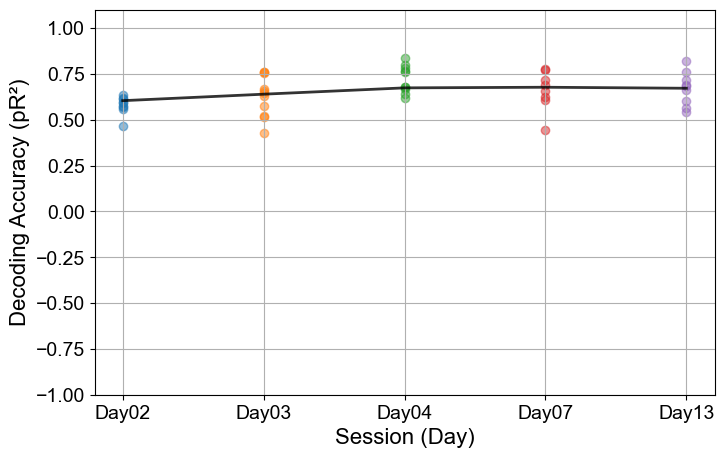

In [105]:


def compute_firing_rates(spike_array, fs, window_duration=0.3):
    window_samples = int(round(window_duration * fs))  # Convert duration to samples
    hanning_window = windows.hann(window_samples)  # Create Hanning window
    hanning_window /= np.sum(hanning_window)  # Normalize window
    
    smoothed_firing_rates = np.zeros_like(spike_array, dtype=float)
    
    for i in range(spike_array.shape[0]):  
        smoothed_firing_rates[i, :] = convolve(spike_array[i, :], hanning_window, mode='same') * fs  
    
    return smoothed_firing_rates
# === Cross-validation setup ===
outer_kf = KFold(n_splits=10, shuffle=True, random_state=42)

for session, pkl_files in session_files.items():
    
    session_pR2 = []
    max_frs_this_session = []

    trial_data_list = []
    spike_data_list = []

    for file in pkl_files:
        glm_data, data, mnpair = load_and_preprocess(file, folder_path, bin_size_ms, fsamp)
        trial_data_list.append(glm_data.T)  # (neurons, time_bins)

        data_MU = np.array(data['MU'].tolist())  # (neurons, samples)
        spike_data_list.append(data_MU)

    concatenated_data = np.hstack(trial_data_list)  # (neurons, total_time_bins)
    concatenated_spikes = np.hstack(spike_data_list)  # (neurons, total_samples)
    smoothed_frs = compute_firing_rates(data_MU, fsamp, window_duration=0.3)
    print(smoothed_frs.shape)
# smoothed_firing_rates[neuron_idx, :]


    num_neurons = concatenated_data.shape[0]

    for target_idx in range(num_neurons):

        X, Y = create_glm_data(concatenated_data.T, target_idx)
        if X is None or Y is None or np.sum(Y) < 20:
            continue

        # === True max FR based on spike trace ===
        max_fr = np.max(smoothed_frs[target_idx, :])
        max_frs_this_session.append((target_idx, max_fr))

        # === Hyperparameter tuning ===
        pipeline = make_pipeline(StandardScaler(), PoissonRegressor(max_iter=1000))
        inner_kf = KFold(n_splits=3, shuffle=True, random_state=42)
        poisson_cv = GridSearchCV(pipeline, alpha_grid, cv=inner_kf, scoring='neg_mean_poisson_deviance')
        poisson_cv.fit(X, Y)
        best_alpha = poisson_cv.best_params_['poissonregressor__alpha']

        # === Outer CV ===
        fold_pR2s = []
        for train_idx, test_idx in outer_kf.split(X):
            X_train, X_test = X[train_idx], X[test_idx]
            Y_train, Y_test = Y[train_idx], Y[test_idx]

            if np.sum(Y_test) < 5:
                continue

            model = PoissonRegressor(alpha=best_alpha, max_iter=1000)
            model.fit(X_train, Y_train)

            pR2 = compute_pR2(model, X_test, Y_test)
            fold_pR2s.append(pR2)

        if len(fold_pR2s) > 0:
            mean_pR2 = np.nanmean(fold_pR2s)
            session_pR2.append(mean_pR2)

    if len(session_pR2) > 0:
        session_results[session] = session_pR2

    if len(max_frs_this_session) > 0:
        session_max_firing_rates[session] = max_frs_this_session
        print(f"\n=== Max firing rates for session {session} ===")
        for idx, fr in max_frs_this_session:
            print(f"Neuron {idx}: {fr:.2f} Hz")

# === PLOT RESULTS ===
plt.figure(figsize=(8, 5))
plt.rcParams.update({'font.family': 'Arial'})

session_means = []
session_stds = []
session_labels = []

for idx, (session, pR2_values) in enumerate(session_results.items()):
    mean_pR2 = np.nanmean(pR2_values)
    std_pR2 = np.nanstd(pR2_values)
    
    session_means.append(mean_pR2)
    session_stds.append(std_pR2)
    session_labels.append(session)

    x_positions = np.full(len(pR2_values), idx)
    plt.scatter(x_positions, pR2_values, alpha=0.5)

# Gaussian smoothing
x_values = np.arange(len(session_means))
smoothed_means = gaussian_filter1d(session_means, sigma=1)
plt.plot(x_values, smoothed_means, linestyle='-', color='black', linewidth=2, alpha=0.8)

plt.xticks(range(len(session_labels)), session_labels)
plt.xlabel("Session (Day)", fontname="Arial")
plt.ylabel("Decoding Accuracy (pR²)", fontname="Arial")
plt.ylim([-1, 1.1])
plt.grid(True)
plt.show()



/var/folders/xt/z8_l6n9d1wv6vpcb5vdsp1dr0000gq/T/ipykernel_1111/1323491199.py:21: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(x=all_labels, y=all_pR2s, inner='box', linewidth=1.2, palette=colors, cut=0)
/var/folders/xt/z8_l6n9d1wv6vpcb5vdsp1dr0000gq/T/ipykernel_1111/1323491199.py:40: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  plt.gca().set_xticklabels(desired_x_labels, fontsize=18)


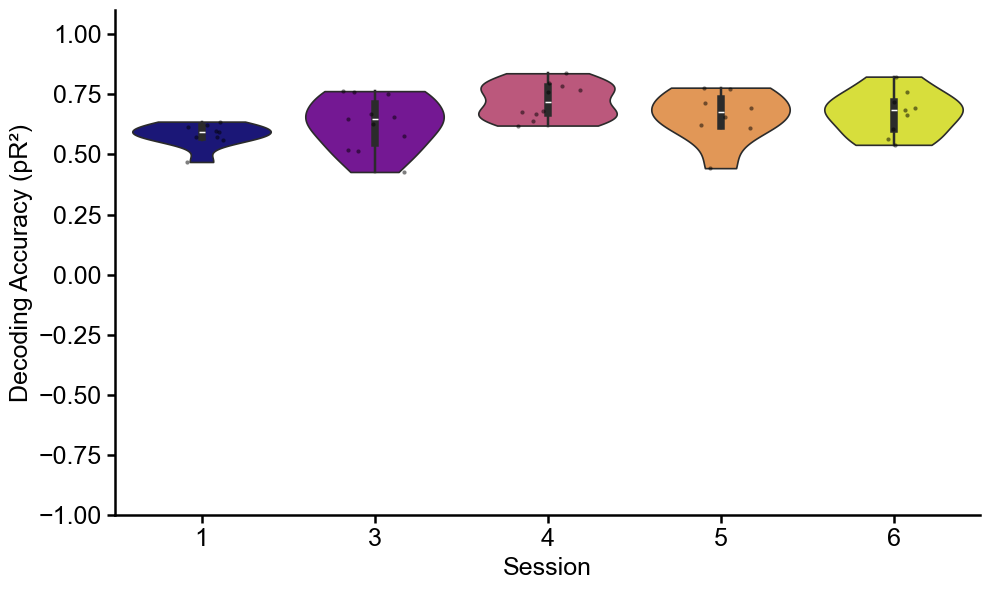

In [106]:
plt.figure(figsize=(10, 6))
plt.rcParams.update({'font.family': 'Arial'})

# Prepare data for seaborn
all_pR2s = []
all_labels = []

for session, pR2_values in session_results.items():
    all_pR2s.extend(pR2_values)
    all_labels.extend([session] * len(pR2_values))

# Number of unique sessions
unique_sessions = sorted(session_results.keys(), key=lambda x: desired_x_labels.index(int(x)) if str(x).isdigit() else int(x)) if all(isinstance(x, str) and x.isdigit() for x in session_results.keys()) else list(session_results.keys())
N = len(unique_sessions)

# Create plasma colour map
cmap = plt.get_cmap('plasma')
colors = [cmap(i / (N - 1)) for i in range(N)]

# Create violin plot with plasma gradient
sns.violinplot(x=all_labels, y=all_pR2s, inner='box', linewidth=1.2, palette=colors, cut=0)

# Overlay individual data points
sns.stripplot(x=all_labels, y=all_pR2s, color='k', size=3, jitter=0.2, alpha=0.5)

# Thicker spines
ax = plt.gca()
for spine in ax.spines.values():
    spine.set_linewidth(1.8)

# Thicker ticks and font
plt.tick_params(width=1.8, length=6, labelsize=18)

# X and Y labels
plt.xlabel("Session", fontsize=18, fontname="Arial")
plt.ylabel("Decoding Accuracy (pR²)", fontsize=18, fontname="Arial")

# Custom X-axis labels
desired_x_labels = [1, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14,15]
plt.gca().set_xticklabels(desired_x_labels, fontsize=18)

# Y limits and layout
plt.ylim([-1, 1.1])
sns.despine(top=True, right=True)

plt.tight_layout()

# Save
plt.savefig('/Users/nmt121/Desktop/GLM_Experim_spikes_S2.pdf', dpi=300, bbox_inches='tight')
plt.show()


## with simulated data (only spikes)

Processing session: DR_subject2_force2
Processing session: DR_subject2_force3
Processing session: DR_subject2_force4
Processing session: DR_subject2_force7
Processing session: DR_subject2_force13


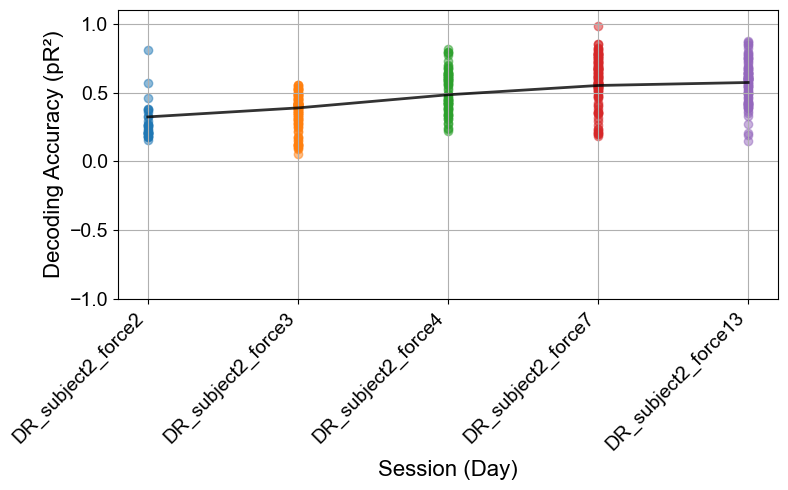

In [107]:
# === Input parameters ===
from functions_experimental_data_Bräckleinexp.GLM_analysis_spikes_pred import *

folder_path = "/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Data_final/Spikes/Simulations_with_force_as_input/DR_S2/"

bin_size_ms = 200
fsamp = 20000  # 20 kHz
bin_size_samples = int(bin_size_ms * fsamp / 1000)

# List of your session files (one "day" = one "force" file)
session_files = [
    # 'DR_subject1_force1.jld2',
    # 'DR_subject1_force3.jld2',
    # 'DR_subject1_force4.jld2',
    # 'DR_subject1_force5.jld2',
    # 'DR_subject1_force6.jld2',
    # 'DR_subject1_force7.jld2',
    # 'DR_subject1_force8.jld2',
    # 'DR_subject1_force9.jld2',
    # 'DR_subject1_force10.jld2',
    # 'DR_subject1_force11.jld2',
    # 'DR_subject1_force12.jld2',
    # 'DR_subject1_force13.jld2',
    # 'DR_subject1_force14.jld2',
    
    'DR_subject2_force2.jld2',
    'DR_subject2_force3.jld2',
    'DR_subject2_force4.jld2',
    'DR_subject2_force7.jld2',
    'DR_subject2_force13.jld2',

 
]
 

alpha_grid = {'poissonregressor__alpha': [0.1, 1, 10, 100, 1000]}
outer_kf = KFold(n_splits=10, shuffle=True, random_state=42)

session_results = {}

for session_file in session_files:
    session_name = session_file.split('.')[0]  
    print(f"Processing session: {session_name}")
    
    # Load data
    file_path = folder_path + session_file
    with h5py.File(file_path, 'r') as f:
        spike_data = f['spike_array'][:]  
        data = spike_data.T  
    
    # Bin data
    num_neurons, num_samples = data.shape
    num_bins = num_samples // bin_size_samples
    data = data[:, :num_bins * bin_size_samples]
    data_reshaped = data.reshape(num_neurons, num_bins, bin_size_samples)
    binned_data = data_reshaped.sum(axis=2)  # shape: (neurons, time_bins)
    
    session_pR2 = []
    for target_idx in range(num_neurons):
        X, Y = create_glm_data(binned_data.T, target_idx)
        if X is None or Y is None or np.sum(Y) < 20:
            continue

        pipeline = make_pipeline(StandardScaler(), PoissonRegressor(max_iter=1000))
        inner_kf = KFold(n_splits=3, shuffle=True, random_state=42)
        poisson_cv = GridSearchCV(pipeline, alpha_grid, cv=inner_kf, scoring='neg_mean_poisson_deviance')
        poisson_cv.fit(X, Y)
        best_alpha = poisson_cv.best_params_['poissonregressor__alpha']

        # Outer CV
        fold_pR2s = []
        for train_idx, test_idx in outer_kf.split(X):
            X_train, X_test = X[train_idx], X[test_idx]
            Y_train, Y_test = Y[train_idx], Y[test_idx]

            if np.sum(Y_test) < 5:
                continue

            model = PoissonRegressor(alpha=best_alpha, max_iter=1000)
            model.fit(X_train, Y_train)
            pR2 = compute_pR2(model, X_test, Y_test)
            fold_pR2s.append(pR2)

        if len(fold_pR2s) > 0:
            mean_pR2 = np.nanmean(fold_pR2s)
            session_pR2.append(mean_pR2)

    if len(session_pR2) > 0:
        session_results[session_name] = session_pR2

# === PLOT RESULTS ===
plt.figure(figsize=(8, 5))
plt.rcParams.update({'font.family': 'Arial'})

session_means = []
session_stds = []
session_labels = []

for idx, (session, pR2_values) in enumerate(session_results.items()):
    mean_pR2 = np.nanmean(pR2_values)
    std_pR2 = np.nanstd(pR2_values)
    
    session_means.append(mean_pR2)
    session_stds.append(std_pR2)
    session_labels.append(session)

    # Scatter plot neurons' mean pR2 values
    x_positions = np.full(len(pR2_values), idx)
    plt.scatter(x_positions, pR2_values, alpha=0.5)


# Gaussian smoothing of session means
x_values = np.arange(len(session_means))
smoothed_means = gaussian_filter1d(session_means, sigma=1)
plt.plot(x_values, smoothed_means, linestyle='-', color='black', linewidth=2, alpha=0.8)

plt.xticks(range(len(session_labels)), session_labels, rotation=45, ha='right')
plt.xlabel("Session (Day)", fontname="Arial")
plt.ylabel("Decoding Accuracy (pR²)", fontname="Arial")
plt.ylim([-1, 1.1])
plt.grid(True)
plt.tight_layout()
plt.show()


#### Match simulated and experimental neurons based on maximum discharge rate

In [108]:
matched_results = match_experimental_to_simulated(session_files=session_files,folder_path=folder_path,session_results=session_results,session_max_firing_rates=session_max_firing_rates,fsamp=fsamp,cost_threshold=5 ) # optional, default is 5Hz of difference)

Matching for DR_subject2_force2
✓ exp[0] (rate=16.20) ↔ sim[2] (rate=12.22) → cost = 3.98
✗ exp[1] (rate=31.18) ↔ sim[27] (rate=12.71) → cost = 18.46 → skipped
✓ exp[2] (rate=17.33) ↔ sim[33] (rate=12.48) → cost = 4.85
✗ exp[3] (rate=30.05) ↔ sim[5] (rate=12.25) → cost = 17.80 → skipped
✗ exp[4] (rate=22.05) ↔ sim[4] (rate=12.04) → cost = 10.01 → skipped
✓ exp[5] (rate=13.24) ↔ sim[23] (rate=12.79) → cost = 0.45
✓ exp[6] (rate=15.21) ↔ sim[0] (rate=12.02) → cost = 3.18
✗ exp[7] (rate=23.66) ↔ sim[7] (rate=12.27) → cost = 11.39 → skipped
✗ exp[8] (rate=35.99) ↔ sim[35] (rate=12.34) → cost = 23.65 → skipped
Matching for DR_subject2_force3
✓ exp[0] (rate=15.78) ↔ sim[78] (rate=15.79) → cost = 0.01
✓ exp[1] (rate=16.92) ↔ sim[19] (rate=16.91) → cost = 0.01
✓ exp[2] (rate=15.69) ↔ sim[69] (rate=15.69) → cost = 0.00
✓ exp[3] (rate=13.62) ↔ sim[116] (rate=13.52) → cost = 0.10
✓ exp[4] (rate=14.66) ↔ sim[93] (rate=14.76) → cost = 0.10
✓ exp[5] (rate=12.16) ↔ sim[124] (rate=12.22) → cost = 0.07

/var/folders/xt/z8_l6n9d1wv6vpcb5vdsp1dr0000gq/T/ipykernel_1111/2648236193.py:22: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(x=all_labels, y=all_pR2s, inner='box', linewidth=1.2,palette=palette_dict, cut=0)


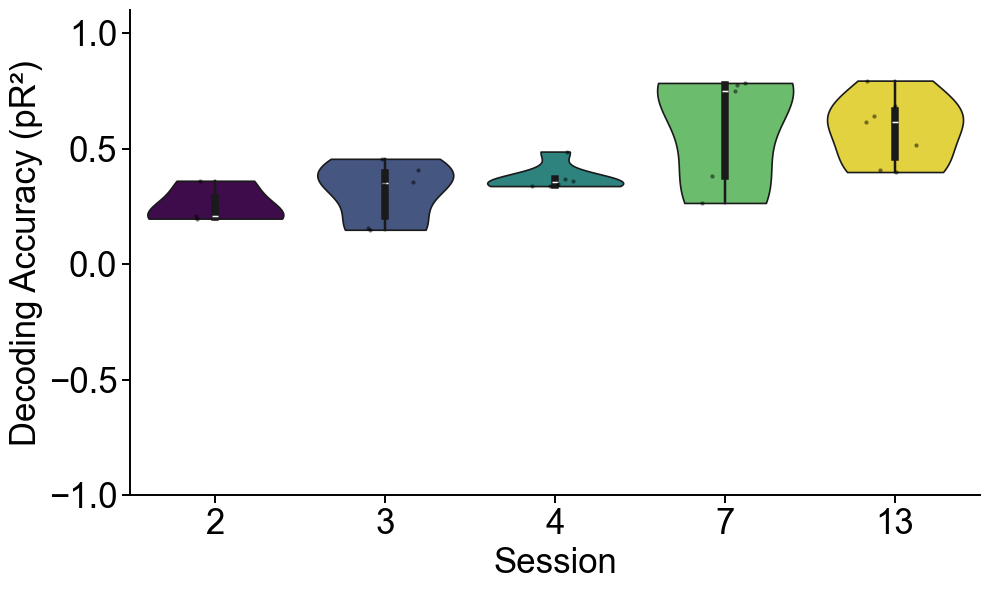

In [109]:
# === PLOT MATCHED pR² VALUES ===
plt.figure(figsize=(10, 6))
plt.rcParams.update({'font.family': 'Arial'})

all_pR2s = []
all_labels = []

for session, pR2_values in matched_results.items():
    session_number = re.findall(r'\d+', session)
    short_label = session_number[-1] if session_number else session  # get last number part
    all_pR2s.extend(pR2_values)
    all_labels.extend([short_label] * len(pR2_values))  # use simplified label

unique_labels = sorted(set(all_labels), key=lambda x: int(x))
N = len(unique_labels)

cmap = plt.get_cmap('viridis')
colors = [cmap(i / (N - 1)) for i in range(N)]

palette_dict = dict(zip(unique_labels, colors))

sns.violinplot(x=all_labels, y=all_pR2s, inner='box', linewidth=1.2,palette=palette_dict, cut=0)
sns.stripplot(x=all_labels, y=all_pR2s, color='k', size=3, jitter=0.2, alpha=0.5)

# Style adjustments
ax = plt.gca()
for spine in ax.spines.values():
    spine.set_linewidth(1.4)

plt.tick_params(width=1.4, length=6, labelsize=25)  # make ticks bigger
plt.xlabel("Session", fontsize=25, fontname="Arial")
plt.ylabel("Decoding Accuracy (pR²)", fontsize=25, fontname="Arial")
plt.xticks(rotation=0, fontsize=25)
plt.ylim([-1, 1.1])
sns.despine(top=True, right=True)
plt.tight_layout()

plt.savefig('/Users/nmt121/Desktop/Figures/GLM_SimulatedSpikes_S2.pdf', dpi=300, bbox_inches='tight')

plt.show()



### With force

0.8108201803806075
0.8006104157124851
0.7210647037848825
0.8390897765697913
0.7001665929156062
0.842963414454395
0.8556205458186771
0.7829691287484074
0.7853216697154303
0.6980492705225161


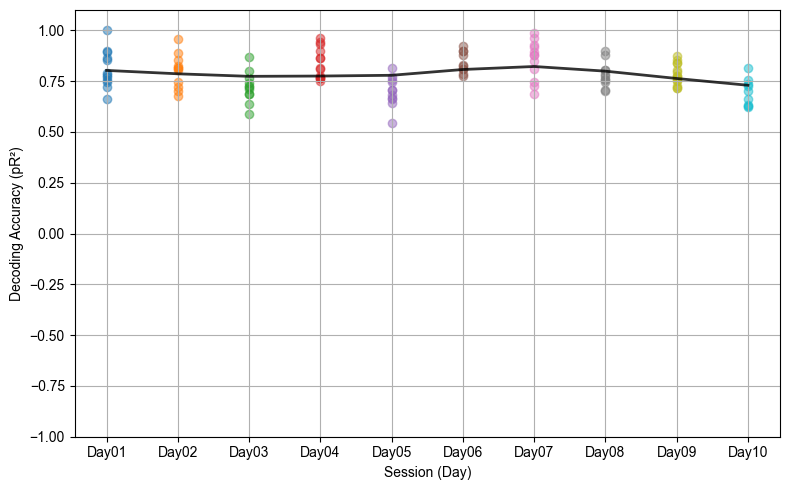

In [84]:
# === Input parameters ===
folder_path = '/Users/nmt121/Desktop/DATA/S7/'
bin_size_ms = 200  
session_files = session_files7

#regularization 
alpha_grid = {'poissonregressor__alpha': [0.1, 1, 10, 100, 1000]}  
session_results = {}

#init cross val
outer_kf = KFold(n_splits=10, shuffle=True, random_state=42)


def preprocess_trial_force(file, folder_path, bin_size_ms, fsamp=2048):
    file_path = os.path.join(folder_path, file)
    with open(file_path, 'rb') as f:
        data = pickle.load(f)

    force = np.array(data['Force'])
    if force.ndim == 2:
        force = force.squeeze()
        
    data_MU = np.array(data['MU'].tolist())

    # Convert bin size from ms to samples
    bin_size_samples = int(bin_size_ms * fsamp / 1000)

    # Determine number of bins
    num_timepoints = force.shape[0]
    num_bins = num_timepoints // bin_size_samples

    # Bin the spikes and force
    binned_spikes = np.add.reduceat(data_MU, np.arange(0, num_bins * bin_size_samples, bin_size_samples), axis=1)
    binned_force = np.add.reduceat(force[:num_bins * bin_size_samples], np.arange(0, num_bins * bin_size_samples, bin_size_samples)) / bin_size_samples

    mnpair = data['Idx_MU_Pair'].tolist()

    return binned_spikes, binned_force, mnpair


# === MAIN EXECUTION ===
session_results = {}

for session, pkl_files in session_files.items():
    session_pR2 = []
    force_trials = []
    spike_trials = []

    for file in pkl_files:
        spikes, force, mnpair = preprocess_trial_force(file,folder_path, bin_size_ms)
        if spikes is None or force is None:
            continue
        force_trials.append(force)
        spike_trials.append(spikes)

    if not force_trials or not spike_trials:
        continue

    concatenated_force = np.concatenate(force_trials)
    concatenated_spikes = np.hstack(spike_trials)
    num_neurons = concatenated_spikes.shape[0]

    for neuron_idx in range(num_neurons):
        
        if neuron_idx: #== mnpair[0] : #or target_idx == mnpair[1]:

            neuron_spikes = concatenated_spikes[neuron_idx, :]

            X, Y = create_force_glm_data(concatenated_force, neuron_spikes)
            if X is None or Y is None or np.sum(Y) < 20:
                continue

            # === Inner CV for alpha ===
            pipeline = make_pipeline(StandardScaler(), PoissonRegressor(max_iter=1000))
            inner_kf = KFold(n_splits=3, shuffle=True, random_state=42)
            poisson_cv = GridSearchCV(pipeline, alpha_grid, cv=inner_kf, scoring='neg_mean_poisson_deviance')
            poisson_cv.fit(X, Y)
            best_alpha = poisson_cv.best_params_['poissonregressor__alpha']

            # === Outer CV for model performance ===
            fold_pR2s = []
            for train_idx, test_idx in outer_kf.split(X):
                X_train, X_test = X[train_idx], X[test_idx]
                Y_train, Y_test = Y[train_idx], Y[test_idx]

                if np.sum(Y_test) < 5:
                    continue

                scaler = StandardScaler()
                X_train_scaled = scaler.fit_transform(X_train)
                X_test_scaled = scaler.transform(X_test)

                model = PoissonRegressor(alpha=best_alpha, max_iter=1000)
                model.fit(X_train_scaled, Y_train)

                pR2 = compute_pR2(model, X_test_scaled, Y_test)
                fold_pR2s.append(pR2)

            if fold_pR2s:
                mean_pR2 = np.nanmean(fold_pR2s)
                session_pR2.append(mean_pR2)

    if session_pR2:
        session_results[session] = session_pR2

# === PLOTTING RESULTS ===
plt.figure(figsize=(8, 5))
plt.rcParams.update({'font.family': 'Arial'})

session_means = []
session_stds = []
session_labels = []

for idx, (session, pR2_values) in enumerate(session_results.items()):
    mean_pR2 = np.nanmean(pR2_values)
    print(mean_pR2)
    std_pR2 = np.nanstd(pR2_values)

    session_means.append(mean_pR2)
    session_stds.append(std_pR2)
    session_labels.append(session)

    x_positions = np.full(len(pR2_values), idx)
    plt.scatter(x_positions, pR2_values, alpha=0.5)

x_values = np.arange(len(session_means))
smoothed_means = gaussian_filter1d(session_means, sigma=1)
plt.plot(x_values, smoothed_means, linestyle='-', color='black', linewidth=2, alpha=0.8)

plt.xticks(range(len(session_labels)), session_labels)
plt.xlabel("Session (Day)", fontname="Arial")
plt.ylabel("Decoding Accuracy (pR²)", fontname="Arial")
plt.ylim([-1, 1.1])
plt.grid(True)
plt.tight_layout()
plt.show()


/var/folders/xt/z8_l6n9d1wv6vpcb5vdsp1dr0000gq/T/ipykernel_41909/3140717862.py:21: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(x=all_labels, y=all_pR2s, inner='box', linewidth=1.2, palette=colors, cut=0)
/var/folders/xt/z8_l6n9d1wv6vpcb5vdsp1dr0000gq/T/ipykernel_41909/3140717862.py:40: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  plt.gca().set_xticklabels(desired_x_labels, fontsize=18)


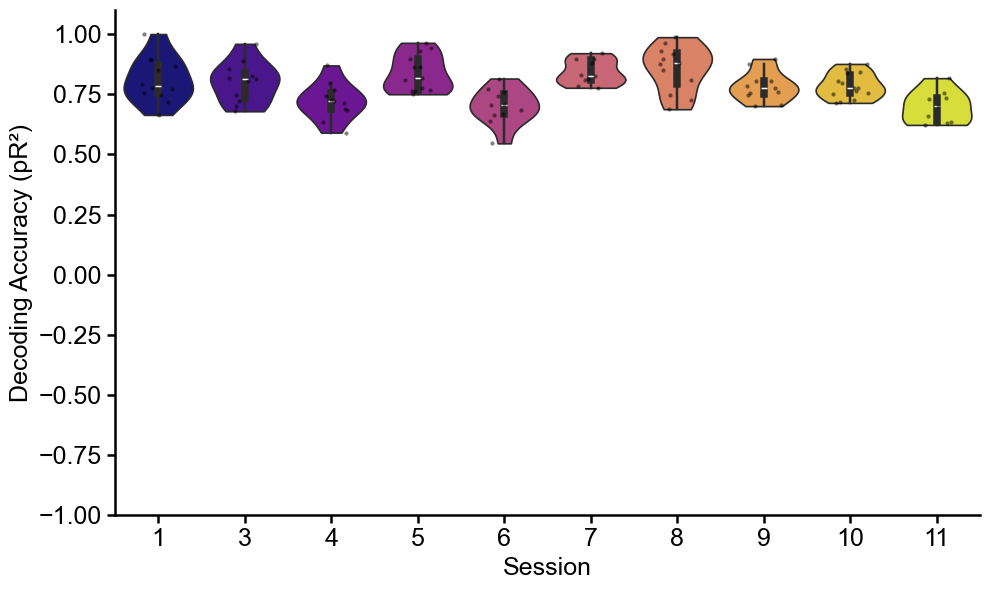

In [85]:
plt.figure(figsize=(10, 6))
plt.rcParams.update({'font.family': 'Arial'})

# Prepare data for seaborn
all_pR2s = []
all_labels = []

for session, pR2_values in session_results.items():
    all_pR2s.extend(pR2_values)
    all_labels.extend([session] * len(pR2_values))

# Number of unique sessions
unique_sessions = sorted(session_results.keys(), key=lambda x: desired_x_labels.index(int(x)) if str(x).isdigit() else int(x)) if all(isinstance(x, str) and x.isdigit() for x in session_results.keys()) else list(session_results.keys())
N = len(unique_sessions)

# Create plasma colour map
cmap = plt.get_cmap('plasma')
colors = [cmap(i / (N - 1)) for i in range(N)]

# Create violin plot with plasma gradient
sns.violinplot(x=all_labels, y=all_pR2s, inner='box', linewidth=1.2, palette=colors, cut=0)

# Overlay individual data points
sns.stripplot(x=all_labels, y=all_pR2s, color='k', size=3, jitter=0.2, alpha=0.5)

# Thicker spines
ax = plt.gca()
for spine in ax.spines.values():
    spine.set_linewidth(1.8)

# Thicker ticks and font
plt.tick_params(width=1.8, length=6, labelsize=18)

# X and Y labels
plt.xlabel("Session", fontsize=18, fontname="Arial")
plt.ylabel("Decoding Accuracy (pR²)", fontsize=18, fontname="Arial")

# Custom X-axis labels
desired_x_labels = [1, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14]
plt.gca().set_xticklabels(desired_x_labels, fontsize=18)

# Y limits and layout
plt.ylim([-1, 1.1])
sns.despine(top=True, right=True)

plt.tight_layout()

# Save
plt.savefig('/Users/nmt121/Desktop/s7_forcepr.pdf', dpi=300, bbox_inches='tight')
plt.show()


### with simulated data

In [154]:

# # === Parameters ===
# fsamp_spikes = 20000  # Hz
# fsamp_force = 2048    # Hz
# bin_size_ms = 200
# bin_size_samples = int(bin_size_ms * fsamp_spikes / 1000)

# # === Paths ===
# spike_folder = 'Data_MN_Model/Data_final/Spikes/Force_analysis/S2'
# force_folder = 'Data_MN_Model/Data_final/Force_exp/S2'

# # === Files for each day ===
# days = [2,3,4,7,13]
# session_files = [f'DR_subject2_force{d}.jld2' for d in days]

# alpha_grid = {'poissonregressor__alpha': [0.1, 1, 10, 100, 1000]}
# outer_kf = KFold(n_splits=10, shuffle=True, random_state=42)

# # === Utility functions ===
# def preprocess_force_pickle(file_path, fsamp_force, fsamp_target, target_samples, bin_size_samples):
#     with open(file_path, 'rb') as f_force:
#         force_dict = pickle.load(f_force)
#         force = force_dict['mean_force']
    
#     n_force = len(force)
#     t_force = np.arange(n_force) / fsamp_force
#     t_target = np.arange(target_samples) / fsamp_target
#     force_interp = interp1d(t_force, force, kind='linear', fill_value='extrapolate')
#     force_resampled = force_interp(t_target)
    
#     n_bins = target_samples // bin_size_samples
#     force_resampled = force_resampled[:n_bins * bin_size_samples]
#     force_reshaped = force_resampled.reshape(n_bins, bin_size_samples)
#     binned_force = force_reshaped.mean(axis=1)
    
#     return binned_force


# # === MAIN EXECUTION ===
# session_results = {}

# for idx, day in enumerate(days):
#     spike_file = session_files[idx]
#     force_file = f"avg_force_Day{day:02d}.pkl"
#     print(f"Processing Day {day} with {spike_file} and {force_file}")

#     # Load spikes
#     with h5py.File(os.path.join(spike_folder, spike_file), 'r') as f:
#         spike_data = f['spike_array'][:]
#         spikes = spike_data.T  # shape: (neurons, samples)

#     # Preprocess force
#     binned_force = preprocess_force_pickle(
#         os.path.join(force_folder, force_file),
#         fsamp_force,
#         fsamp_spikes,
#         spikes.shape[1],
#         bin_size_samples
#     )

#     # Bin spikes
#     n_bins = spikes.shape[1] // bin_size_samples
#     spikes = spikes[:, :n_bins * bin_size_samples]
#     spikes_reshaped = spikes.reshape(spikes.shape[0], n_bins, bin_size_samples)
#     binned_spikes = spikes_reshaped.sum(axis=2)

#     # Predict each neuron
#     session_pR2 = []
#     for neuron_idx in range(spikes.shape[0]):
#         neuron_spikes = binned_spikes[neuron_idx, :]

#         X, Y = create_force_glm_data(binned_force, neuron_spikes)
#         if X is None or Y is None or np.sum(Y) < 20:
#             continue

#         # Inner CV for alpha
#         pipeline = make_pipeline(StandardScaler(), PoissonRegressor(max_iter=1000))
#         inner_kf = KFold(n_splits=3, shuffle=True, random_state=42)
#         poisson_cv = GridSearchCV(pipeline, alpha_grid, cv=inner_kf, scoring='neg_mean_poisson_deviance')
#         poisson_cv.fit(X, Y)
#         best_alpha = poisson_cv.best_params_['poissonregressor__alpha']

#         # Outer CV for pR²
#         fold_pR2s = []
#         for train_idx, test_idx in outer_kf.split(X):
#             X_train, X_test = X[train_idx], X[test_idx]
#             Y_train, Y_test = Y[train_idx], Y[test_idx]

#             if np.sum(Y_test) < 5:
#                 continue

#             scaler = StandardScaler()
#             X_train_scaled = scaler.fit_transform(X_train)
#             X_test_scaled = scaler.transform(X_test)

#             model = PoissonRegressor(alpha=best_alpha, max_iter=1000)
#             model.fit(X_train_scaled, Y_train)

#             pR2 = compute_pR2(model, X_test_scaled, Y_test)
#             fold_pR2s.append(pR2)

#         if fold_pR2s:
#             mean_pR2 = np.nanmean(fold_pR2s)
#             session_pR2.append(mean_pR2)

#     if session_pR2:
#         session_results[f"Day{day:02d}"] = session_pR2

# # === Plotting results ===
# plt.figure(figsize=(8, 5))
# plt.rcParams.update({'font.family': 'Arial'})

# session_means = []
# session_stds = []
# session_labels = []

# for idx, (session, pR2_values) in enumerate(session_results.items()):
#     mean_pR2 = np.nanmean(pR2_values)
#     std_pR2 = np.nanstd(pR2_values)

#     session_means.append(mean_pR2)
#     session_stds.append(std_pR2)
#     session_labels.append(session)

#     x_positions = np.full(len(pR2_values), idx)
#     plt.scatter(x_positions, pR2_values, alpha=0.5)

# x_values = np.arange(len(session_means))
# smoothed_means = gaussian_filter1d(session_means, sigma=1)
# plt.plot(x_values, smoothed_means, linestyle='-', color='black', linewidth=2, alpha=0.8)

# plt.xticks(range(len(session_labels)), session_labels, rotation=45, ha='right')
# plt.xlabel("Session (Day)", fontname="Arial")
# plt.ylabel("Decoding Accuracy (pR²)", fontname="Arial")
# plt.ylim([-1, 1.1])
# plt.grid(True)
# plt.tight_layout()
# plt.show()



Processing DR_subject7_force01.jld2 and avg_forceS7_Day01.npy
Processing DR_subject7_force02.jld2 and avg_forceS7_Day02.npy
Processing DR_subject7_force03.jld2 and avg_forceS7_Day03.npy
Processing DR_subject7_force04.jld2 and avg_forceS7_Day04.npy


/var/folders/xt/z8_l6n9d1wv6vpcb5vdsp1dr0000gq/T/ipykernel_2393/1184541522.py:114: RuntimeWarning: Mean of empty slice
  mean_pR2 = np.nanmean(fold_pR2s)
/var/folders/xt/z8_l6n9d1wv6vpcb5vdsp1dr0000gq/T/ipykernel_2393/1184541522.py:114: RuntimeWarning: Mean of empty slice
  mean_pR2 = np.nanmean(fold_pR2s)
/var/folders/xt/z8_l6n9d1wv6vpcb5vdsp1dr0000gq/T/ipykernel_2393/1184541522.py:114: RuntimeWarning: Mean of empty slice
  mean_pR2 = np.nanmean(fold_pR2s)
/var/folders/xt/z8_l6n9d1wv6vpcb5vdsp1dr0000gq/T/ipykernel_2393/1184541522.py:114: RuntimeWarning: Mean of empty slice
  mean_pR2 = np.nanmean(fold_pR2s)
/var/folders/xt/z8_l6n9d1wv6vpcb5vdsp1dr0000gq/T/ipykernel_2393/1184541522.py:114: RuntimeWarning: Mean of empty slice
  mean_pR2 = np.nanmean(fold_pR2s)
/var/folders/xt/z8_l6n9d1wv6vpcb5vdsp1dr0000gq/T/ipykernel_2393/1184541522.py:114: RuntimeWarning: Mean of empty slice
  mean_pR2 = np.nanmean(fold_pR2s)
/var/folders/xt/z8_l6n9d1wv6vpcb5vdsp1dr0000gq/T/ipykernel_2393/1184541522.p

Processing DR_subject7_force05.jld2 and avg_forceS7_Day05.npy


/var/folders/xt/z8_l6n9d1wv6vpcb5vdsp1dr0000gq/T/ipykernel_2393/1184541522.py:114: RuntimeWarning: Mean of empty slice
  mean_pR2 = np.nanmean(fold_pR2s)


Processing DR_subject7_force06.jld2 and avg_forceS7_Day06.npy
Processing DR_subject7_force07.jld2 and avg_forceS7_Day07.npy
Processing DR_subject7_force08.jld2 and avg_forceS7_Day08.npy
Processing DR_subject7_force09.jld2 and avg_forceS7_Day09.npy
Processing DR_subject7_force10.jld2 and avg_forceS7_Day10.npy


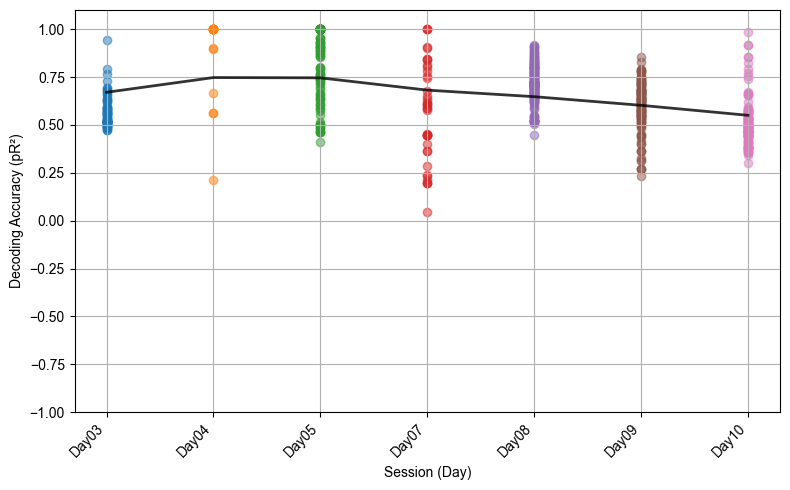

In [98]:
# === Input parameters ===
fsamp_spikes = 20000  # Hz
fsamp_force = 2048    # Hz
bin_size_ms = 200
bin_size_samples = int(bin_size_ms * fsamp_spikes / 1000)

# === Paths ===
spike_folder = 'Data_MN_Model/Data_final/Spikes/Force_analysis/'
force_folder = 'Data_MN_Model/Data_final/Force_exp/S7'

# === Files for each day ===
session_files = [
    'DR_subject7_force01.jld2',
    'DR_subject7_force02.jld2',
    'DR_subject7_force03.jld2',
    'DR_subject7_force04.jld2',
    'DR_subject7_force05.jld2',
    'DR_subject7_force06.jld2',
    'DR_subject7_force07.jld2',    
    'DR_subject7_force08.jld2',
    'DR_subject7_force09.jld2',
    'DR_subject7_force10.jld2',      

]
# Map days based on session_files order
day_mapping = ['01', '02','03', '04', '05', '06','07','08','09','10']  # days for the corresponding session_files

alpha_grid = {'poissonregressor__alpha': [0.1, 1, 10, 100, 1000]}
outer_kf = KFold(n_splits=10, shuffle=True, random_state=42)

# === Utility functions ===
def preprocess_force_npy(file_path, fsamp_force, fsamp_target, target_samples, bin_size_samples):
    # Load force data from .npy file
    force = np.load(file_path)
    
    n_force = len(force)
    t_force = np.arange(n_force) / fsamp_force
    t_target = np.arange(target_samples) / fsamp_target
    force_interp = interp1d(t_force, force, kind='linear', fill_value='extrapolate')
    force_resampled = force_interp(t_target)
    
    n_bins = target_samples // bin_size_samples
    force_resampled = force_resampled[:n_bins * bin_size_samples]
    force_reshaped = force_resampled.reshape(n_bins, bin_size_samples)
    binned_force = force_reshaped.mean(axis=1)
    
    return binned_force

# === MAIN EXECUTION ===
session_results = {}

for idx, spike_file in enumerate(session_files):  # Iterate directly over the session_files
    day = day_mapping[idx]  # Get the corresponding day from day_mapping
    force_file = f"avg_forceS7_Day{day}.npy"  # Construct correct file name based on the day
    print(f"Processing {spike_file} and {force_file}")

    # Load spikes (using jld2 format for spike data)
    with h5py.File(os.path.join(spike_folder, spike_file), 'r') as f:
        spike_data = f['spike_array'][:]  # shape: (neurons, samples)
        spikes = spike_data.T  # Transpose to shape: (samples, neurons)

    # Bin spikes (same as second script)
    num_neurons, num_samples = spikes.shape
    num_bins = num_samples // bin_size_samples
    spikes = spikes[:, :num_bins * bin_size_samples]
    spikes_reshaped = spikes.reshape(num_neurons, num_bins, bin_size_samples)
    binned_spikes = spikes_reshaped.sum(axis=2)  # shape: (neurons, time_bins)

    # Preprocess force
    binned_force = preprocess_force_npy(
        os.path.join(force_folder, force_file),
        fsamp_force,
        fsamp_spikes,
        spikes.shape[1],
        bin_size_samples
    )

    # Predict each neuron
    session_pR2 = []
    for neuron_idx in range(spikes.shape[0]):
        neuron_spikes = binned_spikes[neuron_idx, :]

        X, Y = create_force_glm_data(binned_force, neuron_spikes)
        if X is None or Y is None or np.sum(Y) < 20:
            continue

        # Inner CV for alpha
        pipeline = make_pipeline(StandardScaler(), PoissonRegressor(max_iter=1000))
        inner_kf = KFold(n_splits=3, shuffle=True, random_state=42)
        poisson_cv = GridSearchCV(pipeline, alpha_grid, cv=inner_kf, scoring='neg_mean_poisson_deviance')
        poisson_cv.fit(X, Y)
        best_alpha = poisson_cv.best_params_['poissonregressor__alpha']

        # Outer CV for pR²
        fold_pR2s = []
        for train_idx, test_idx in outer_kf.split(X):
            X_train, X_test = X[train_idx], X[test_idx]
            Y_train, Y_test = Y[train_idx], Y[test_idx]

            if np.sum(Y_test) < 5:
                continue

            scaler = StandardScaler()
            X_train_scaled = scaler.fit_transform(X_train)
            X_test_scaled = scaler.transform(X_test)

            model = PoissonRegressor(alpha=best_alpha, max_iter=1000)
            model.fit(X_train_scaled, Y_train)

            pR2 = compute_pR2(model, X_test_scaled, Y_test)
            fold_pR2s.append(pR2)

        if fold_pR2s:
            mean_pR2 = np.nanmean(fold_pR2s)
            session_pR2.append(mean_pR2)

    if session_pR2:
        session_results[f"Day{day}"] = session_pR2

# === Plotting results ===
plt.figure(figsize=(8, 5))
plt.rcParams.update({'font.family': 'Arial'})

session_means = []
session_stds = []
session_labels = []

for idx, (session, pR2_values) in enumerate(session_results.items()):
    mean_pR2 = np.nanmean(pR2_values)
    std_pR2 = np.nanstd(pR2_values)
    
    session_means.append(mean_pR2)
    session_stds.append(std_pR2)
    session_labels.append(session)

    # Scatter plot neurons' mean pR2 values
    x_positions = np.full(len(pR2_values), idx)
    plt.scatter(x_positions, pR2_values, alpha=0.5)


# Gaussian smoothing of session means
x_values = np.arange(len(session_means))
smoothed_means = gaussian_filter1d(session_means, sigma=1)
plt.plot(x_values, smoothed_means, linestyle='-', color='black', linewidth=2, alpha=0.8)

plt.xticks(range(len(session_labels)), session_labels, rotation=45, ha='right')
plt.xlabel("Session (Day)", fontname="Arial")
plt.ylabel("Decoding Accuracy (pR²)", fontname="Arial")
plt.ylim([-1, 1.1])
plt.grid(True)
plt.tight_layout()
plt.show()


/var/folders/xt/z8_l6n9d1wv6vpcb5vdsp1dr0000gq/T/ipykernel_2393/1732834490.py:21: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(x=all_labels, y=all_pR2s, inner='box', linewidth=1.2, palette=colors, cut=0)
/var/folders/xt/z8_l6n9d1wv6vpcb5vdsp1dr0000gq/T/ipykernel_2393/1732834490.py:40: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  plt.gca().set_xticklabels(desired_x_labels, fontsize=18)


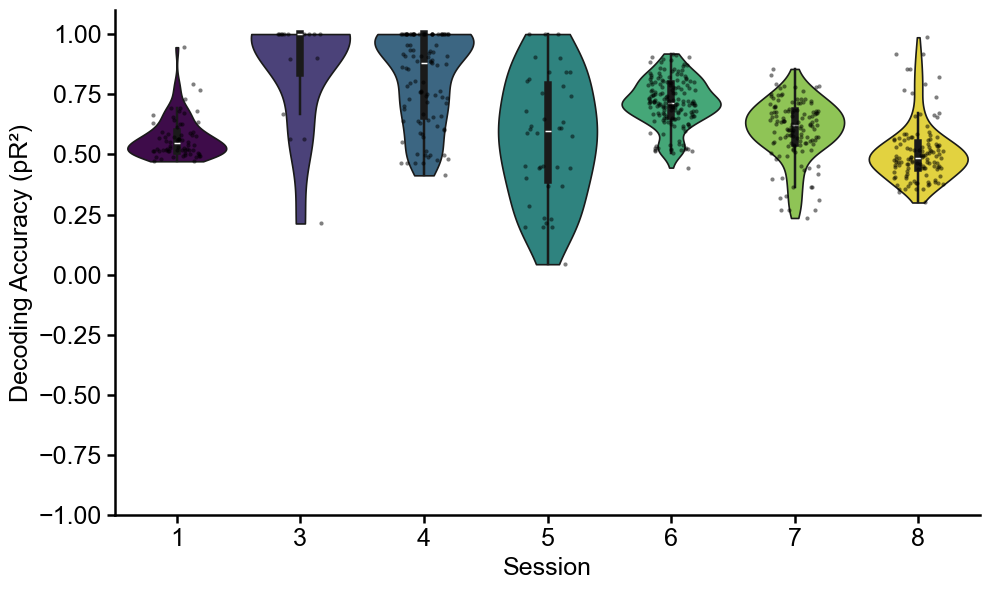

In [99]:


plt.figure(figsize=(10, 6))
plt.rcParams.update({'font.family': 'Arial'})

# Prepare data for seaborn
all_pR2s = []
all_labels = []

for session, pR2_values in session_results.items():
    all_pR2s.extend(pR2_values)
    all_labels.extend([session] * len(pR2_values))

# Number of unique sessions
unique_sessions = sorted(session_results.keys(), key=lambda x: desired_x_labels.index(int(x)) if str(x).isdigit() else int(x)) if all(isinstance(x, str) and x.isdigit() for x in session_results.keys()) else list(session_results.keys())
N = len(unique_sessions)

# Create plasma colour map
cmap = plt.get_cmap('viridis')
colors = [cmap(i / (N - 1)) for i in range(N)]

# Create violin plot with plasma gradient
sns.violinplot(x=all_labels, y=all_pR2s, inner='box', linewidth=1.2, palette=colors, cut=0)

# Overlay individual data points
sns.stripplot(x=all_labels, y=all_pR2s, color='k', size=3, jitter=0.2, alpha=0.5)

# Thicker spines
ax = plt.gca()
for spine in ax.spines.values():
    spine.set_linewidth(1.8)

# Thicker ticks and font
plt.tick_params(width=1.8, length=6, labelsize=18)

# X and Y labels
plt.xlabel("Session", fontsize=18, fontname="Arial")
plt.ylabel("Decoding Accuracy (pR²)", fontsize=18, fontname="Arial")

# Custom X-axis labels
desired_x_labels = [1, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14,15]
plt.gca().set_xticklabels(desired_x_labels, fontsize=18)

# Y limits and layout
plt.ylim([-1, 1.1])
sns.despine(top=True, right=True)

plt.tight_layout()

# Save
plt.savefig('/Users/nmt121/Desktop/s7_forcespr_sim.pdf', dpi=300, bbox_inches='tight')
plt.show()

## Get rasters for each of the trials

In [340]:
# fig = create_raster('/Users/nmt121/Desktop/DATA/S1/', Fsamp=1000, extract_day=extract_day, extract_trial=extract_trial)
# plt.show(fig)
# fig.savefig('/Users/nmt121/Desktop/trial_plot.pdf', dpi=300, bbox_inches='tight')

# Behavioral analysis

## Plot force trajectories for every day and every trial

In [ ]:
# from functions_experimental_data_Bräckleinexp.force_trajectories import *
# fsamp = 2048  
# highlight_samples = int(3 * fsamp)  #in case one wants to highlight part of the trajectory
# fig = create_force_plots_by_day(directory_path='/Users/nmt121/Desktop/DATA/S6/',fsamp=1000,highlight_samples=1000,extract_day=extract_day,extract_trial=extract_trial)
# # plt.show(fig)
# # plt.savefig('/Users/nmt121/Desktop/RESULTS_ DATA EXP/S7force.pdf', dpi=300, bbox_inches='tight')

### Plot force trajectories from 2 first and 2 last days 

In [4]:
# plot_force_trials(directory_path="/Users/nmt121/Desktop/DATA/S1",output_path="/Users/nmt121/Desktop/Figures/S1force.pdf")

## Variance of the second derivative (Jerk smoothness)

In [6]:
# from functions_experimental_data_Bräckleinexp.variance_second_derivative import *
# fig = variance_second_derivative('/Users/nmt121/Desktop/DATA/S1/', fsamp=2048)
# fig.savefig("/Users/nmt121/Desktop/Figures/jerksmoothness.pdf", dpi=300, bbox_inches='tight')

In [5]:
## Run this to get stats
# stat, pval, df = compute_statistical_difference(directory_path='/Users/nmt121/Desktop/DATA/S1/',fsamp=2048,extract_day=extract_day,extract_trial=extract_trial)

## Plot firing rate state space (in this case for two first and last 2 sessions)

In [9]:
# from functions_experimental_data_Bräckleinexp.plot_fr_trajectories import *
# plot_fr_trajectories(directory_path="/Users/nmt121/Desktop/DATA/S1",output_path="/Users/nmt121/Desktop/Figures/S1_FR_trajectory.pdf",clip_thresh=35)

## Plot peak count for each day

In [11]:
# from functions_experimental_data_Bräckleinexp.count_peaks_smoothnes import *

# directory_paths = {"S1": "/Users/nmt121/Desktop/DATA/S1", "S2": "/Users/nmt121/Desktop/DATA/S2","S3": "/Users/nmt121/Desktop/DATA/S3", "S4": "/Users/nmt121/Desktop/DATA/S4", "S6": "/Users/nmt121/Desktop/DATA/S6", "S7": "/Users/nmt121/Desktop/DATA/S7"}

# fig = create_peak_count_summary(directory_paths=directory_paths,fsamp=2048,extract_day=extract_day,extract_trial=extract_trial,lowpass_filter=lowpass_filter)

# # Save when ready
# # fig.savefig("/Users/nmt121/Desktop/Figures/peaks_summary.pdf", dpi=300, bbox_inches='tight')

# # Or display when ready
# plt.show(fig)


## Plot trial duration for all trials

In [14]:
# from functions_experimental_data_Bräckleinexp.trial_duration import *

# directory_paths = {"S1": "/Users/nmt121/Desktop/DATA/S1", "S2": "/Users/nmt121/Desktop/DATA/S2","S3": "/Users/nmt121/Desktop/DATA/S3", "S4": "/Users/nmt121/Desktop/DATA/S4", "S6": "/Users/nmt121/Desktop/DATA/S6", "S7": "/Users/nmt121/Desktop/DATA/S7"}

# plot_avg_trial_durations(directory_paths, fsamp=2048,save_path="/Users/nmt121/Desktop/Figures/avg_trial_durations.pdf")


### Plot trial durations from 2 first and 2 last days 

In [ ]:
# from functions_experimental_data_Bräckleinexp.trial_duration import *
# fig = plot_first_last_two_days_duration_box('/Users/nmt121/Desktop/DATA/S1/', 2048)
# # fig.savefig("/Users/nmt121/Desktop/trial_duration_sessions_box.pdf", dpi=300, bbox_inches='tight')


In [19]:
# from functions_experimental_data_Bräckleinexp.trial_duration import *
# run_duration_stats('/Users/nmt121/Desktop/DATA/S1/', 2048)


## Plot decorrelation time (for how long the higher threshold motoneuron fires alone)

In [ ]:
# from functions_experimental_data_Bräckleinexp.decorrelation_time import *
# plot_prolonged_firing_duration(directory_path="/Users/nmt121/Desktop/DATA/S1",fsamp=2048
#     # scatter_save_path="/Users/nmt121/Desktop/RESULTS_ DATA EXP/s1_scatter.pdf",
#     # trend_save_path="/Users/nmt121/Desktop/RESULTS_ DATA EXP/s1_trend.pdf"
# )


In [26]:
# from functions_experimental_data_Bräckleinexp.decorrelation_time import *


# plot_groupwise_prolonged_firing(session_files_dict={
#         'S1': session_files1,
#         'S2': session_files2,
#         'S3': session_files3,
#         'S4': session_files4,
#         'S6': session_files6,
#         'S7': session_files7
#     },
#     base_data_dir="/Users/nmt121/Desktop/DATA",
#     fsamp=2048,
#     # save_path="/Users/nmt121/Desktop/hysteresisdecorrtime.pdf"
# )

## FIRING RATES

In [288]:
import os
import pickle
import numpy as np
from scipy.signal import convolve, windows
from collections import defaultdict
import re

# Parameters
folder_path = "/Users/nmt121/Desktop/DATA/S1"  # Change to your folder path
fsamp = 2048  # Hz
window_duration = 0.3  # seconds

# Data structures: store max firing rates per neuron for each day
day_max_fr_0 = defaultdict(list)
day_max_fr_1 = defaultdict(list)

# List of pkl files
pkl_files = [f for f in os.listdir(folder_path) if f.endswith('.pkl')]

for file in pkl_files:
    file_path = os.path.join(folder_path, file)

    # Extract the "DayXX" part
    match = re.search(r'Day\d+', file)
    if match:
        day_id = match.group(0)
    else:
        continue

    # Load spike data
    with open(file_path, 'rb') as f:
        data = pickle.load(f)

    data_MU = np.array(data['MU'].tolist())
    idx_pair = data['Idx_MU_Pair'].tolist()

    # Create Hanning window
    window_samples = int(round(window_duration * fsamp))
    hanning_window = windows.hann(window_samples)
    hanning_window /= np.sum(hanning_window)

    # Smooth firing rates for the specific neurons
    smoothed_fr_0 = convolve(data_MU[idx_pair[0], :], hanning_window, mode='same') * fsamp
    smoothed_fr_1 = convolve(data_MU[idx_pair[1], :], hanning_window, mode='same') * fsamp

    # Compute max firing rates
    max_fr_0 = np.max(smoothed_fr_0)
    max_fr_1 = np.max(smoothed_fr_1)

    # Discard trials where either neuron’s firing rate exceeds 80 Hz
    if max_fr_0 > 80 or max_fr_1 > 80:
        continue

    # Store results
    day_max_fr_0[day_id].append(max_fr_0)
    day_max_fr_1[day_id].append(max_fr_1)


print('---')

# Compute and print average of the maximum firing rates for each day
for day_id in sorted(day_max_fr_0.keys()):
    if len(day_max_fr_0[day_id]) == 0:
        print(f'{day_id}: No valid trials below 80 Hz.')
        print('---')
        continue

    avg_max_fr_0 = np.mean(day_max_fr_0[day_id])
    avg_max_fr_1 = np.mean(day_max_fr_1[day_id])
    print(f'{day_id}:')
    print(f'  Average of max firing rates neuron 0: {avg_max_fr_0:.2f} Hz')
    print(f'  Average of max firing rates neuron 1: {avg_max_fr_1:.2f} Hz')
    print('---')


---
Day01:
  Average of max firing rates neuron 0: 24.91 Hz
  Average of max firing rates neuron 1: 18.90 Hz
---
Day03:
  Average of max firing rates neuron 0: 23.22 Hz
  Average of max firing rates neuron 1: 24.75 Hz
---
Day04:
  Average of max firing rates neuron 0: 23.90 Hz
  Average of max firing rates neuron 1: 24.76 Hz
---
Day05:
  Average of max firing rates neuron 0: 14.30 Hz
  Average of max firing rates neuron 1: 15.50 Hz
---
Day06:
  Average of max firing rates neuron 0: 18.86 Hz
  Average of max firing rates neuron 1: 13.66 Hz
---
Day07:
  Average of max firing rates neuron 0: 31.16 Hz
  Average of max firing rates neuron 1: 38.36 Hz
---
Day08:
  Average of max firing rates neuron 0: 24.51 Hz
  Average of max firing rates neuron 1: 16.98 Hz
---
Day09:
  Average of max firing rates neuron 0: 20.10 Hz
  Average of max firing rates neuron 1: 19.92 Hz
---
Day10:
  Average of max firing rates neuron 0: 26.26 Hz
  Average of max firing rates neuron 1: 19.98 Hz
---
Day11:
  Averag

In [342]:
# Output file path
output_csv = os.path.join("/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Data_final/firingrates_max", "average_max_firing_rates_per_day.csv")

# Write to CSV
with open(output_csv, mode='w', newline='') as csvfile:
    writer = csv.writer(csvfile)
    writer.writerow(['Day', 'Avg_Max_FR_Neuron_0', 'Avg_Max_FR_Neuron_1'])

    for day_id in sorted(day_max_fr_0.keys()):
        avg_max_fr_0 = np.mean(day_max_fr_0[day_id])
        avg_max_fr_1 = np.mean(day_max_fr_1[day_id])
        writer.writerow([day_id, f'{avg_max_fr_0:.4f}', f'{avg_max_fr_1:.4f}'])

print(f"Averages saved to {output_csv}")


FileNotFoundError: [Errno 2] No such file or directory: '/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Data_final/firingrates_max/average_max_firing_rates_per_day.csv'

Plotting Day01 with 10 trials...
7.196407796302213
4.651043839207184
4.158167816122543
4.423125806659273
5.800932590804603
3.570181508494075
5.6707417704149305
6.262770966458228
6.158899180006397
4.254335260115607


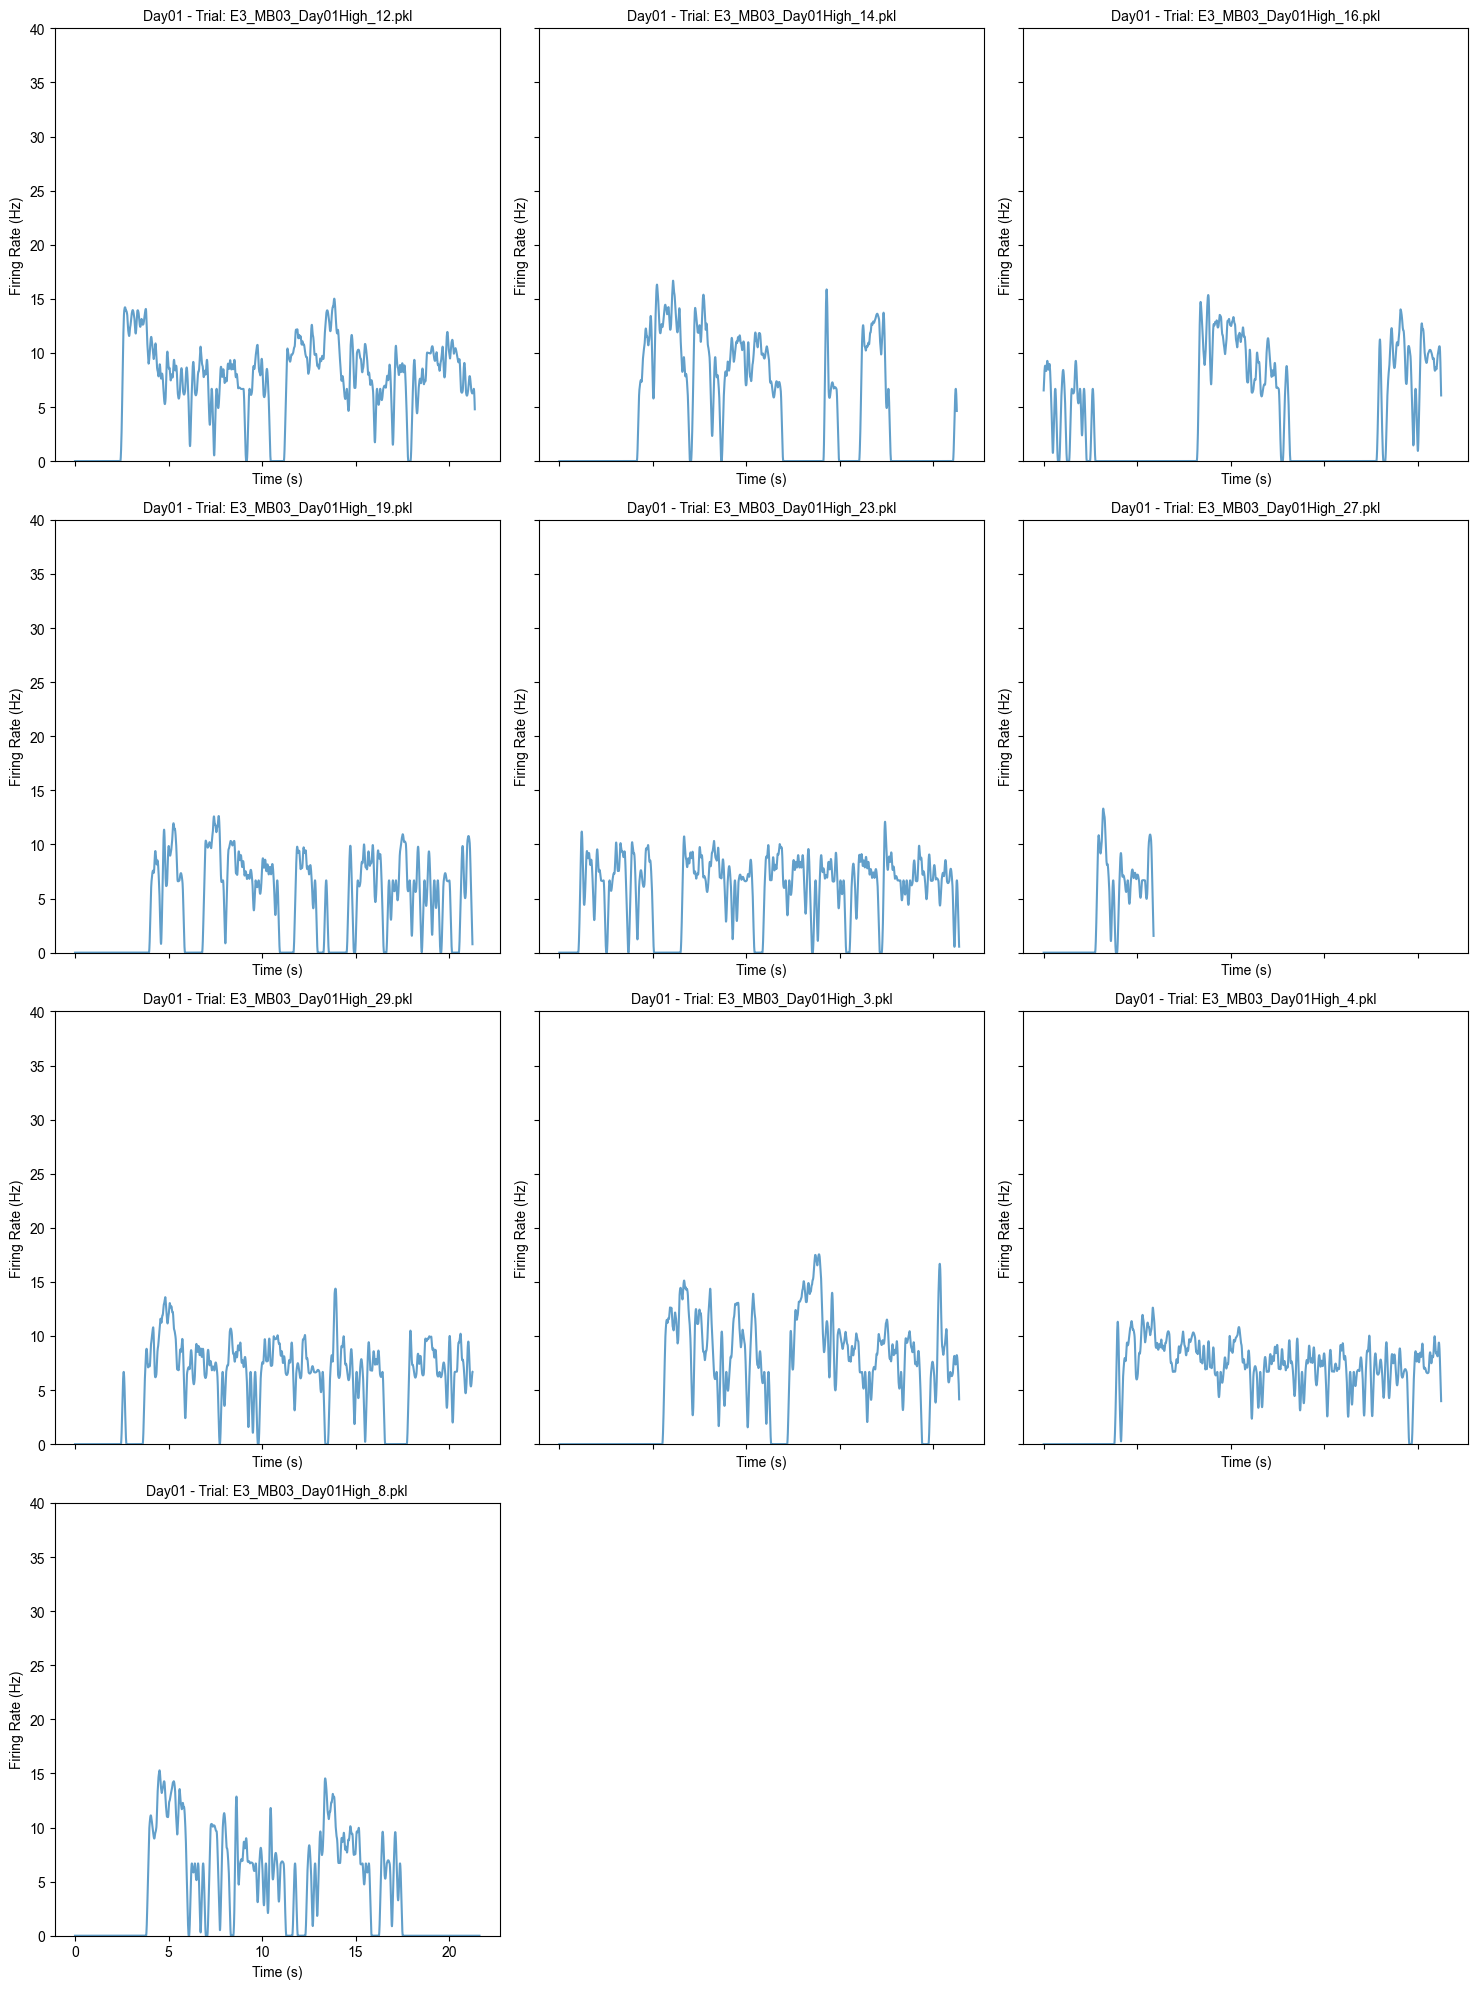

Plotting Day02 with 10 trials...
6.900012598465538
6.868588462198953
7.248623634251348
5.901334076447313
5.464048902758434
8.1467427106668
5.710820742635575
5.4918666709235975
6.936110311707314
6.677786225895885


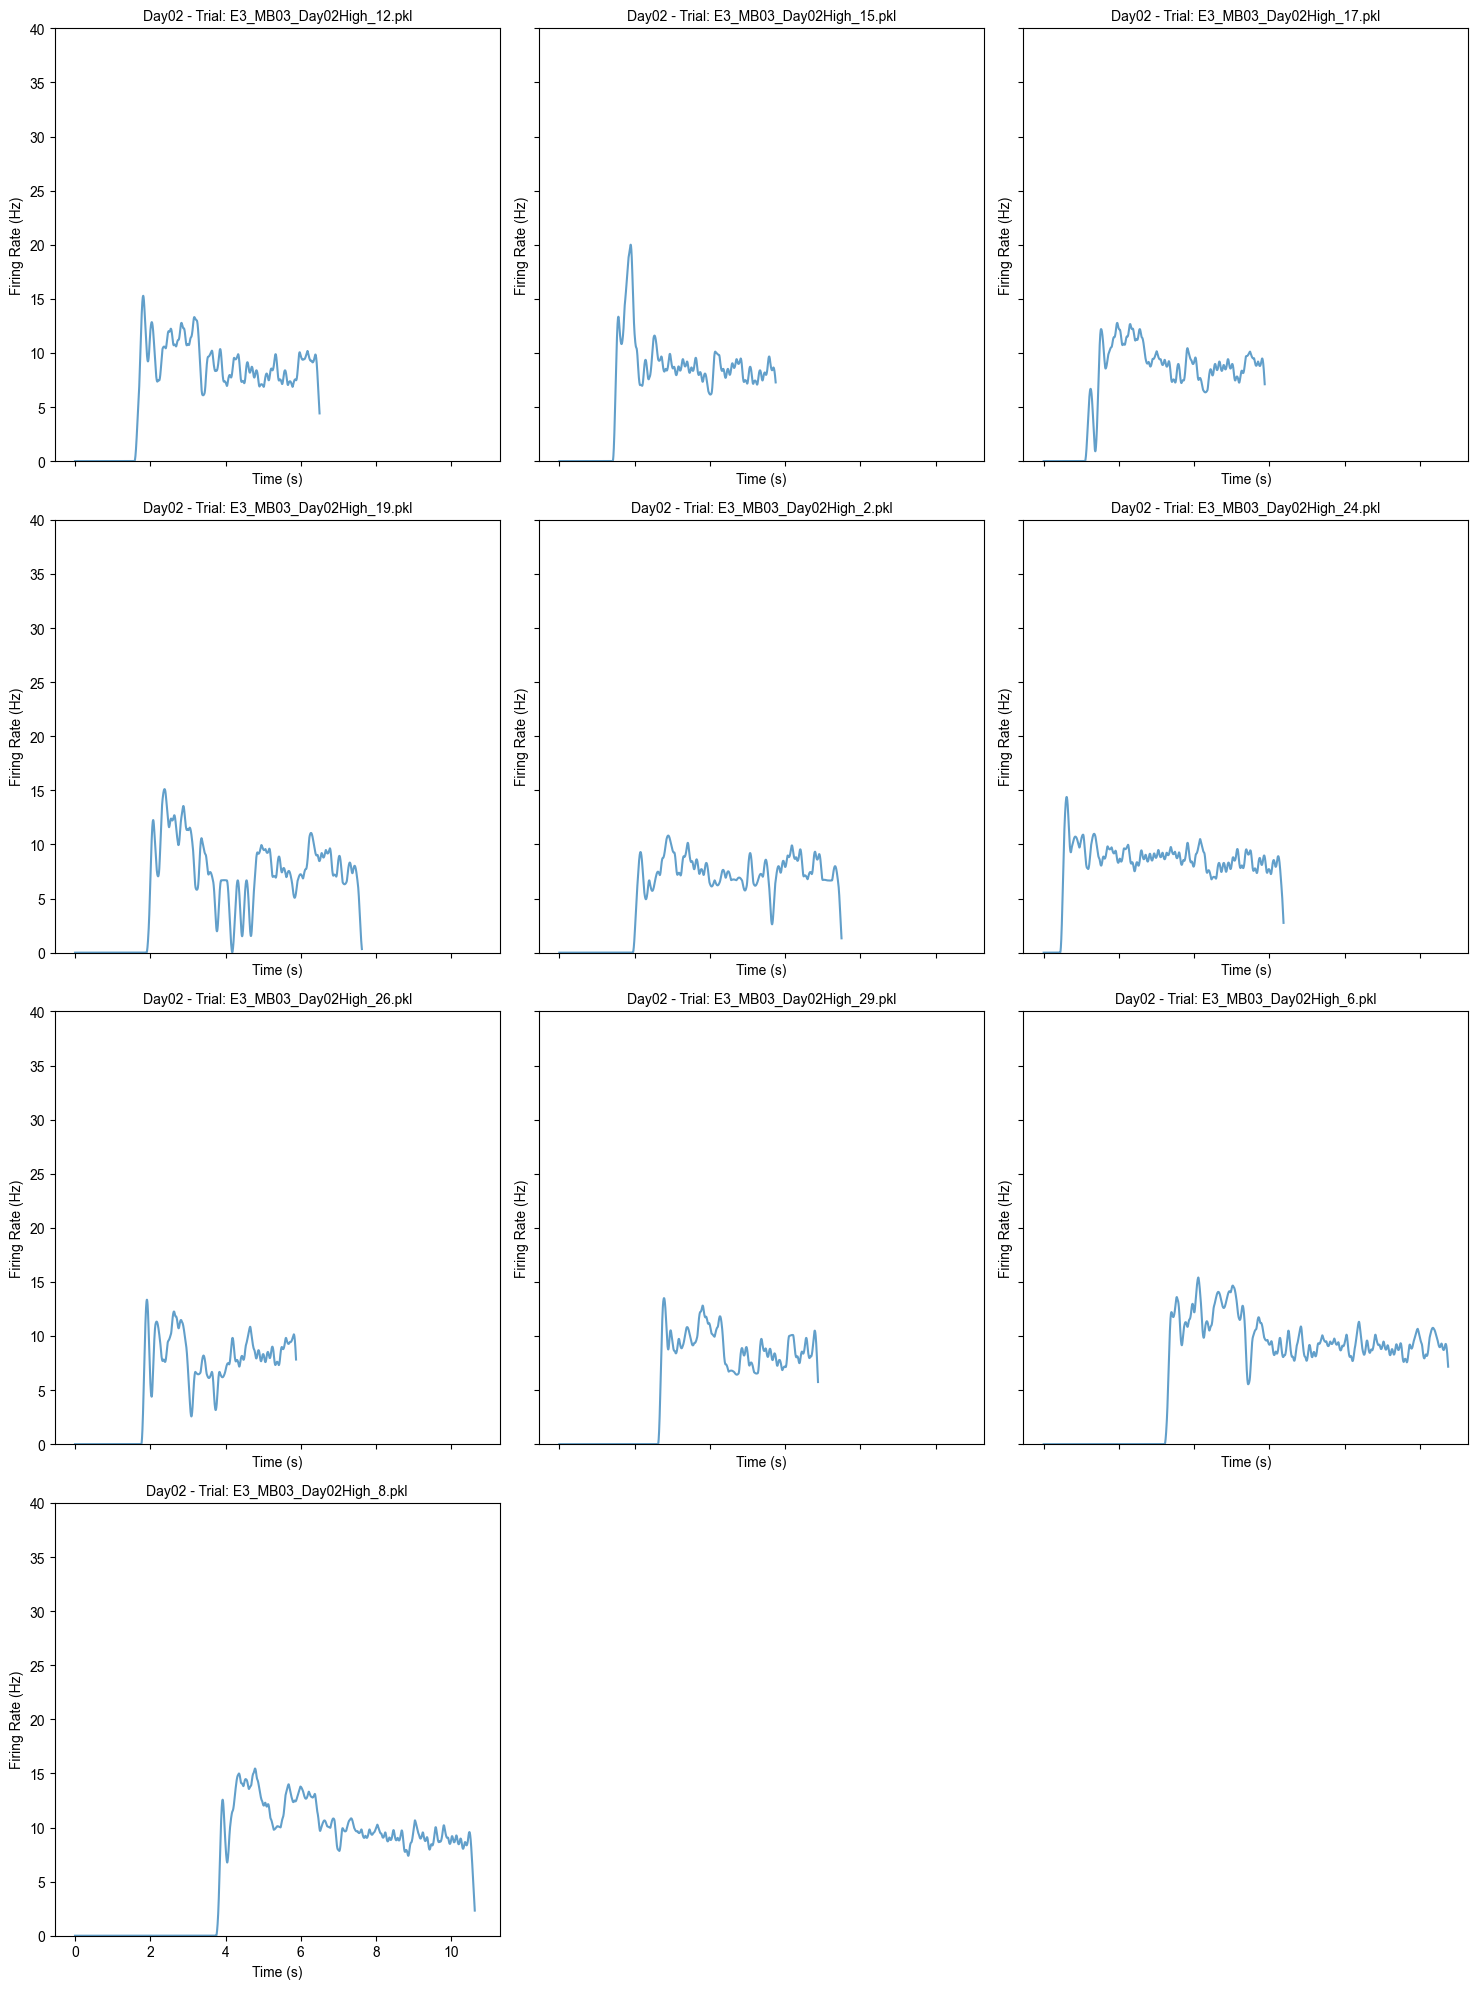

Plotting Day03 with 10 trials...
7.419240597072345
7.995763184166796
7.277924822069739
6.586759325276117
5.776922451273677
6.826496702300282
7.661856015273863
7.95577496511286
7.759425037102957
7.386527666382402


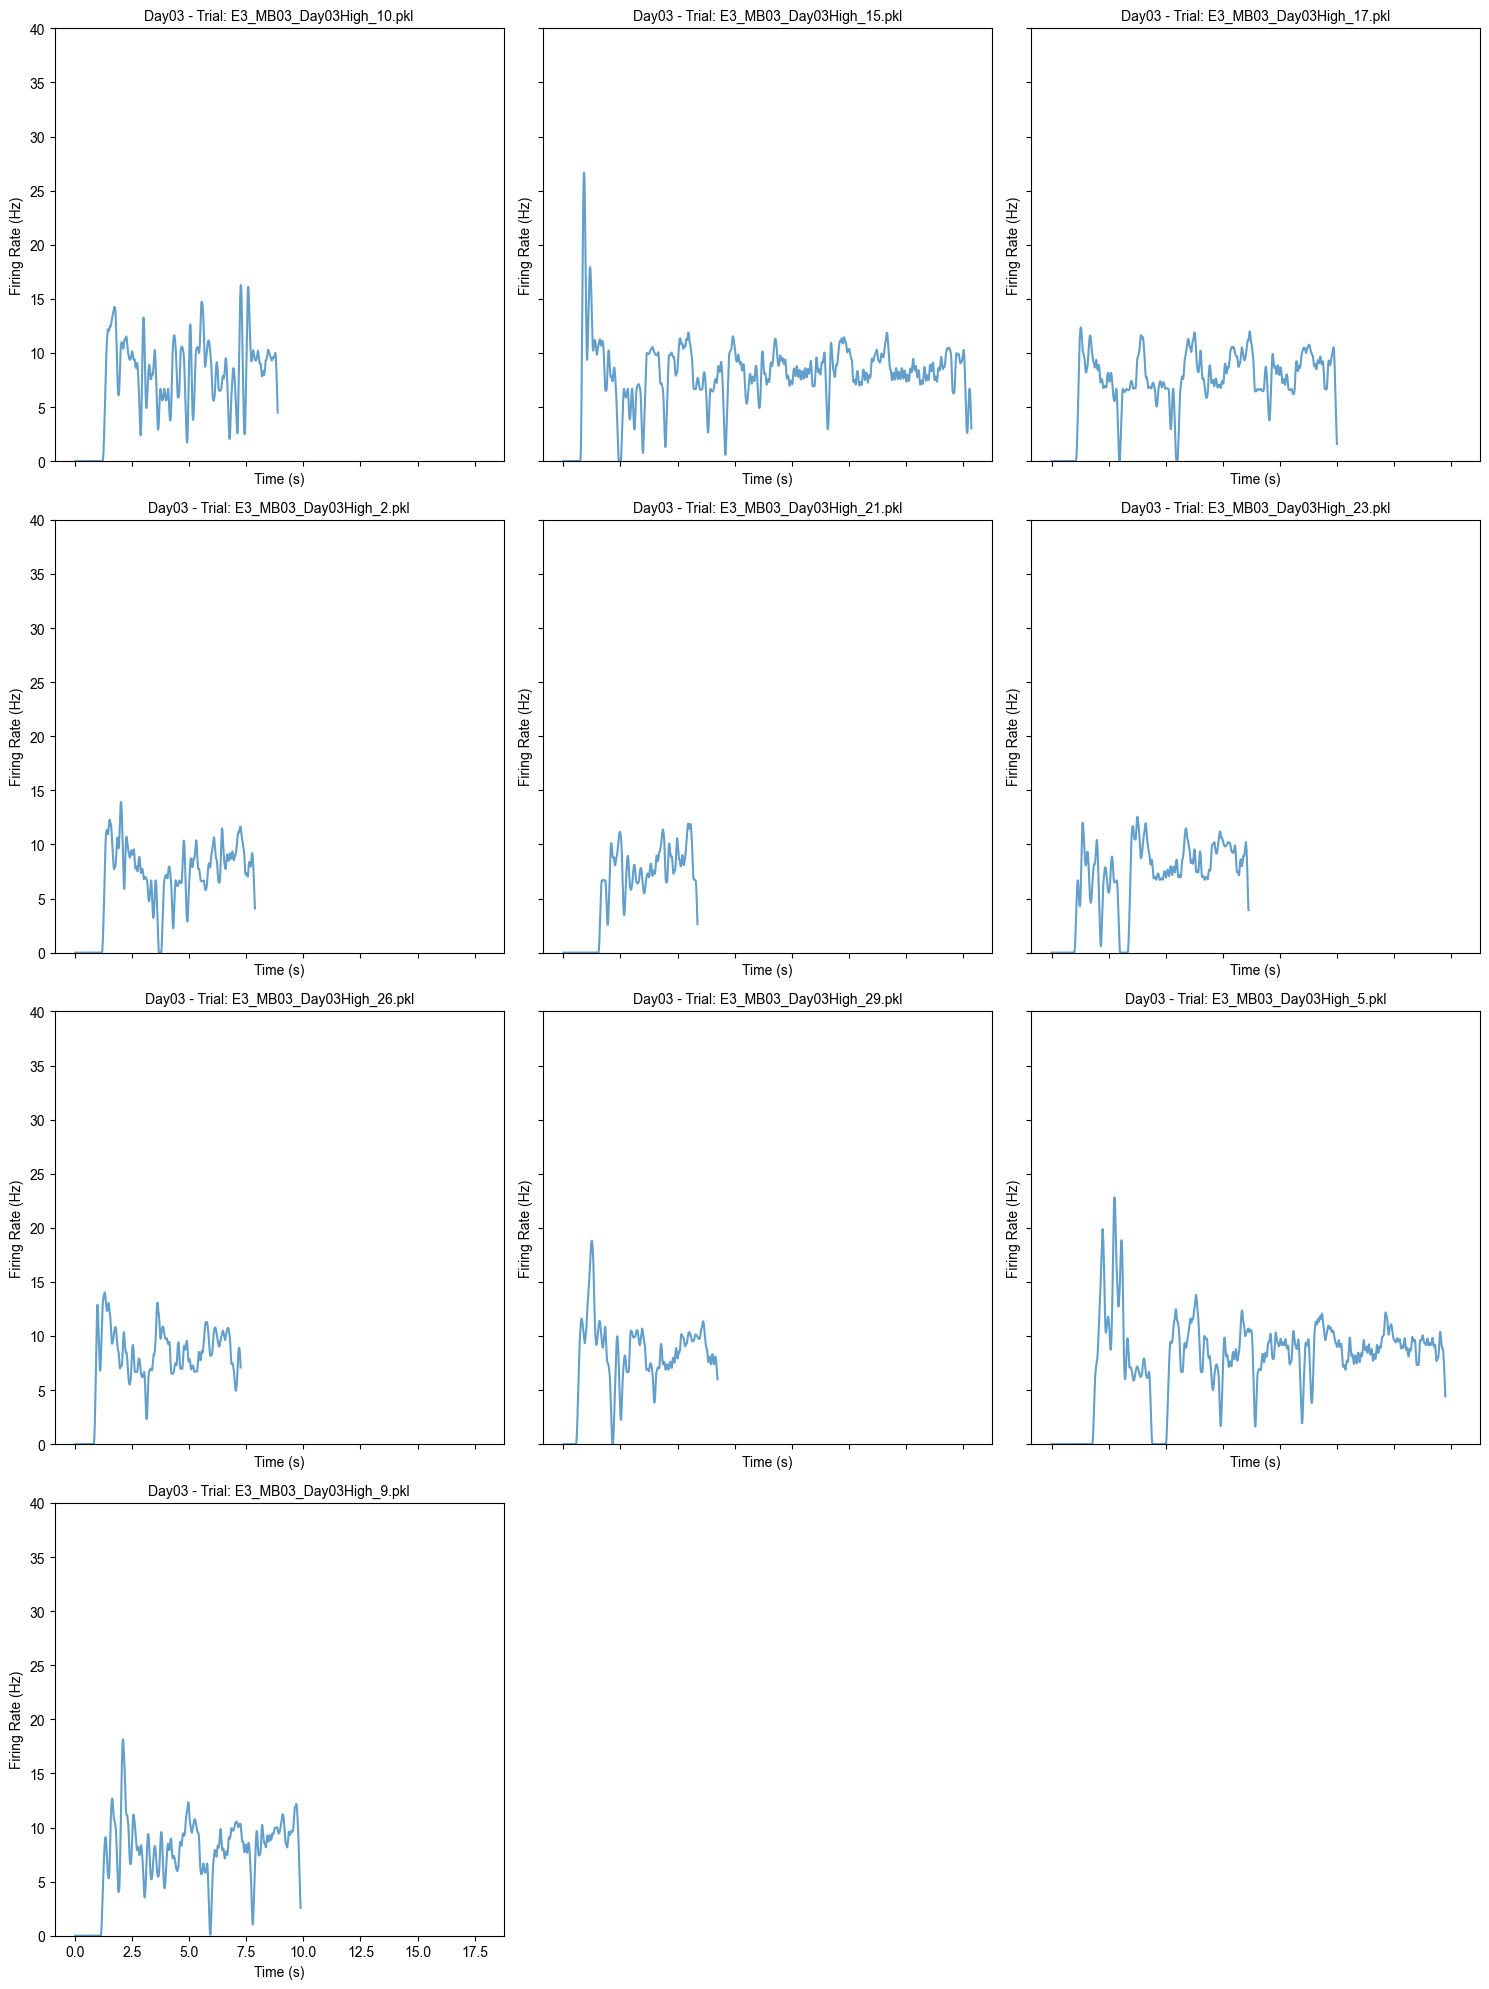

Plotting Day04 with 10 trials...
4.559398922375904
6.023393443915962
5.944006361973199
5.899978293293886
5.461868720342626
5.68096521646453
5.623762376237623
5.876106194690267
5.22667239151628
5.576529638919989


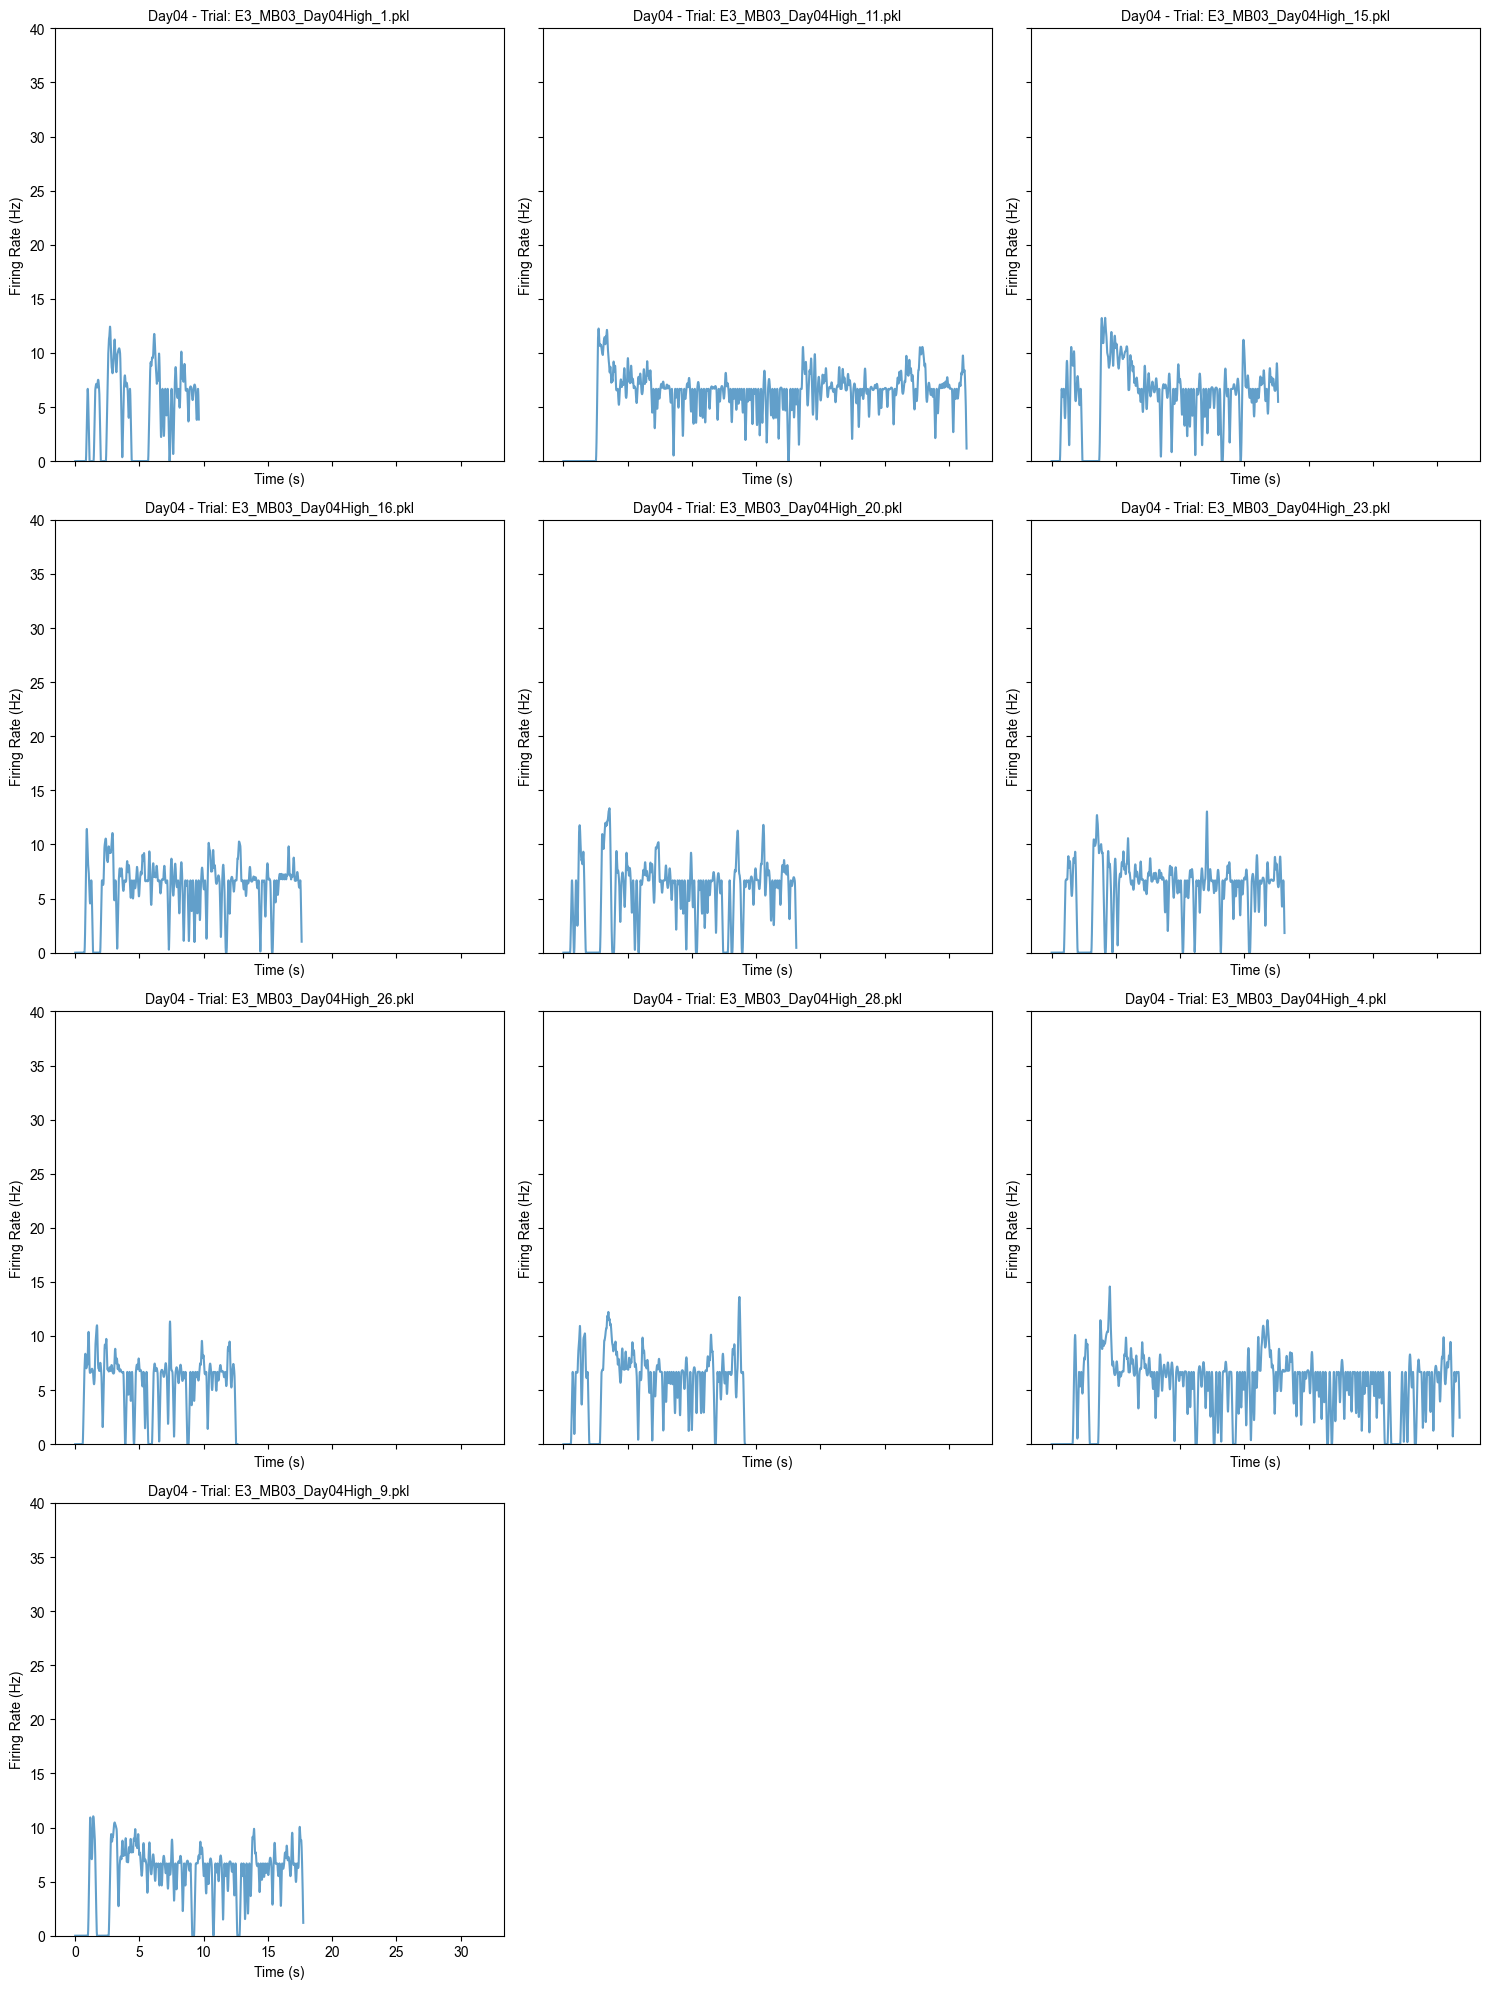

Plotting Day05 with 10 trials...
6.464851023619995
6.51253865315379
7.001988004230166
6.114903196188294
6.46714645232783
6.039174448219879
4.978641751663998
7.0091747210960955
5.392904893691529
6.499032481434141


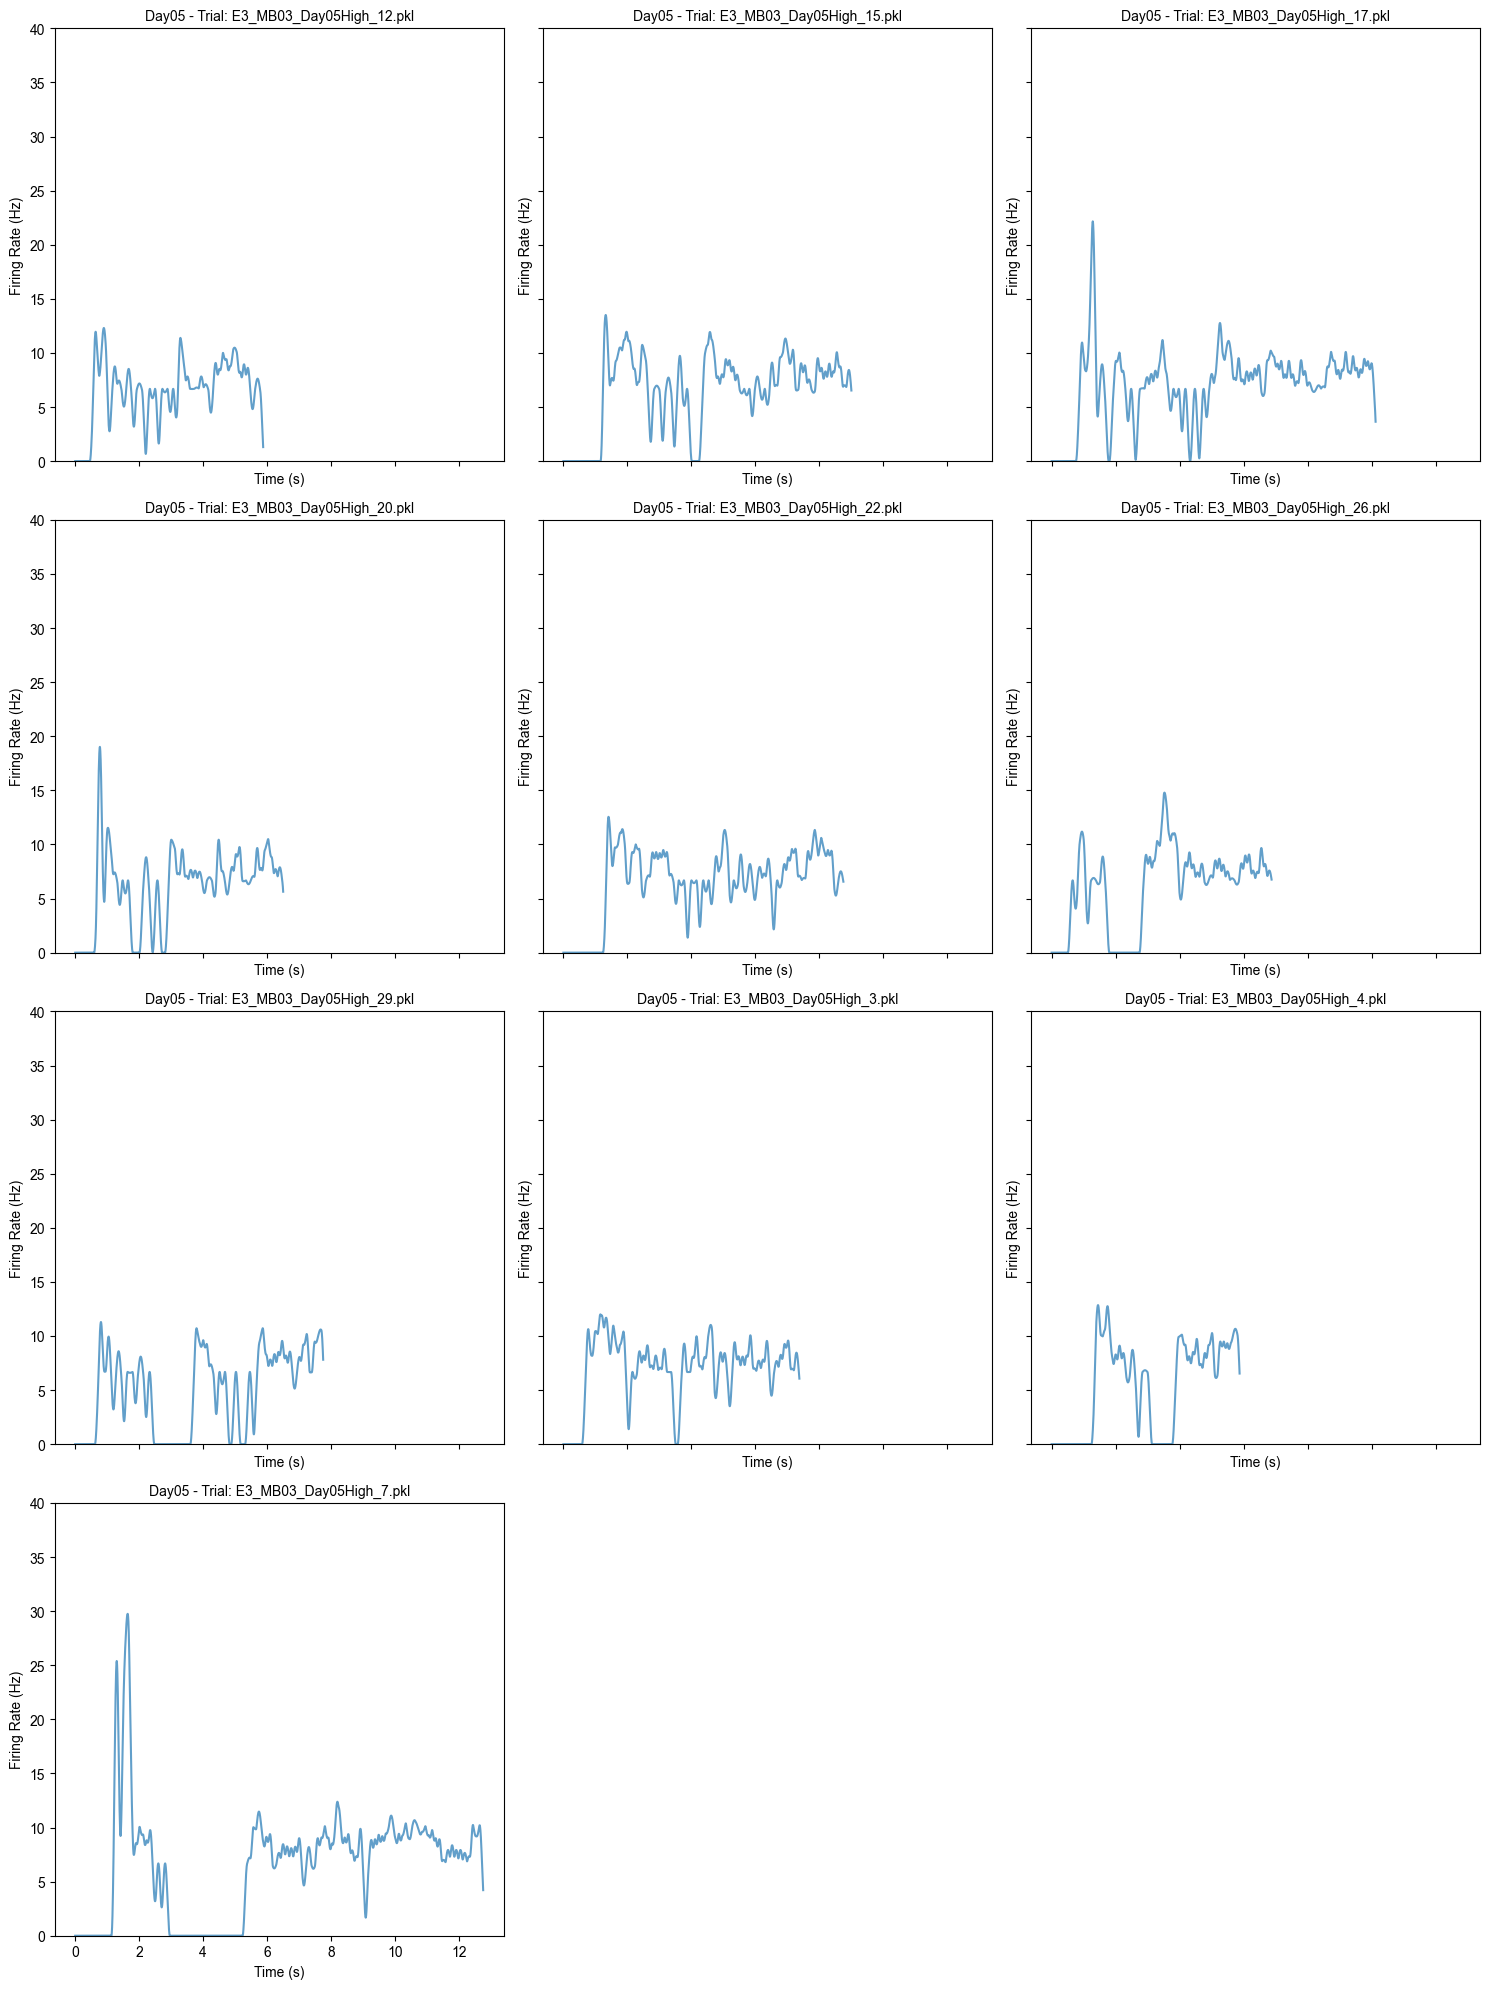

Plotting Day07 with 9 trials...
6.304661660041022
6.128217621802699
6.280252922013028
3.842599811404405
5.890816780843283
6.788015215547152
5.560132346154512
5.345347161084056
6.311406095810689


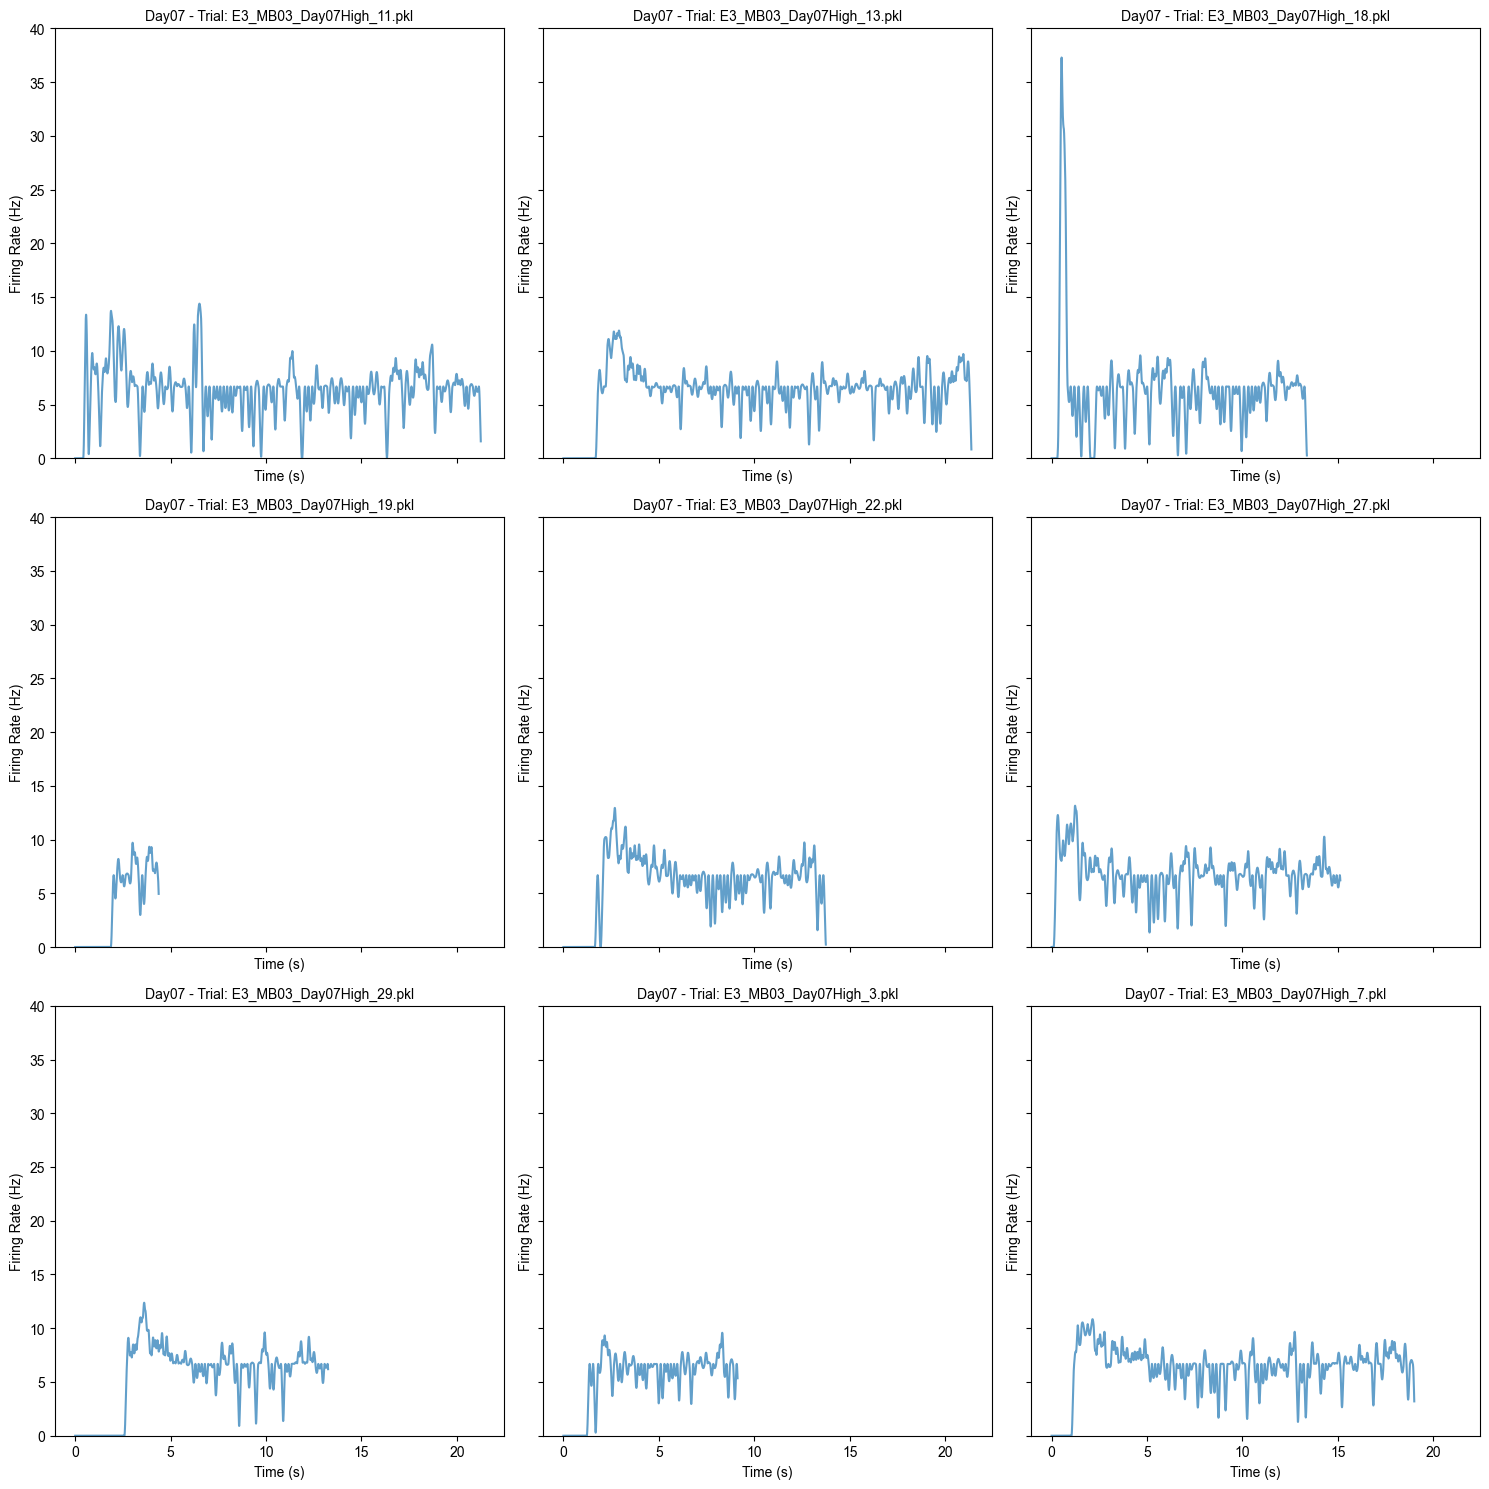

Plotting Day10 with 10 trials...
6.539065331502666
7.038627742641528
6.190799028508262
7.239807045225376
7.222051058889152
8.885060151806872
6.879161601740952
8.057552816091064
6.871434629162876
7.63034450429198


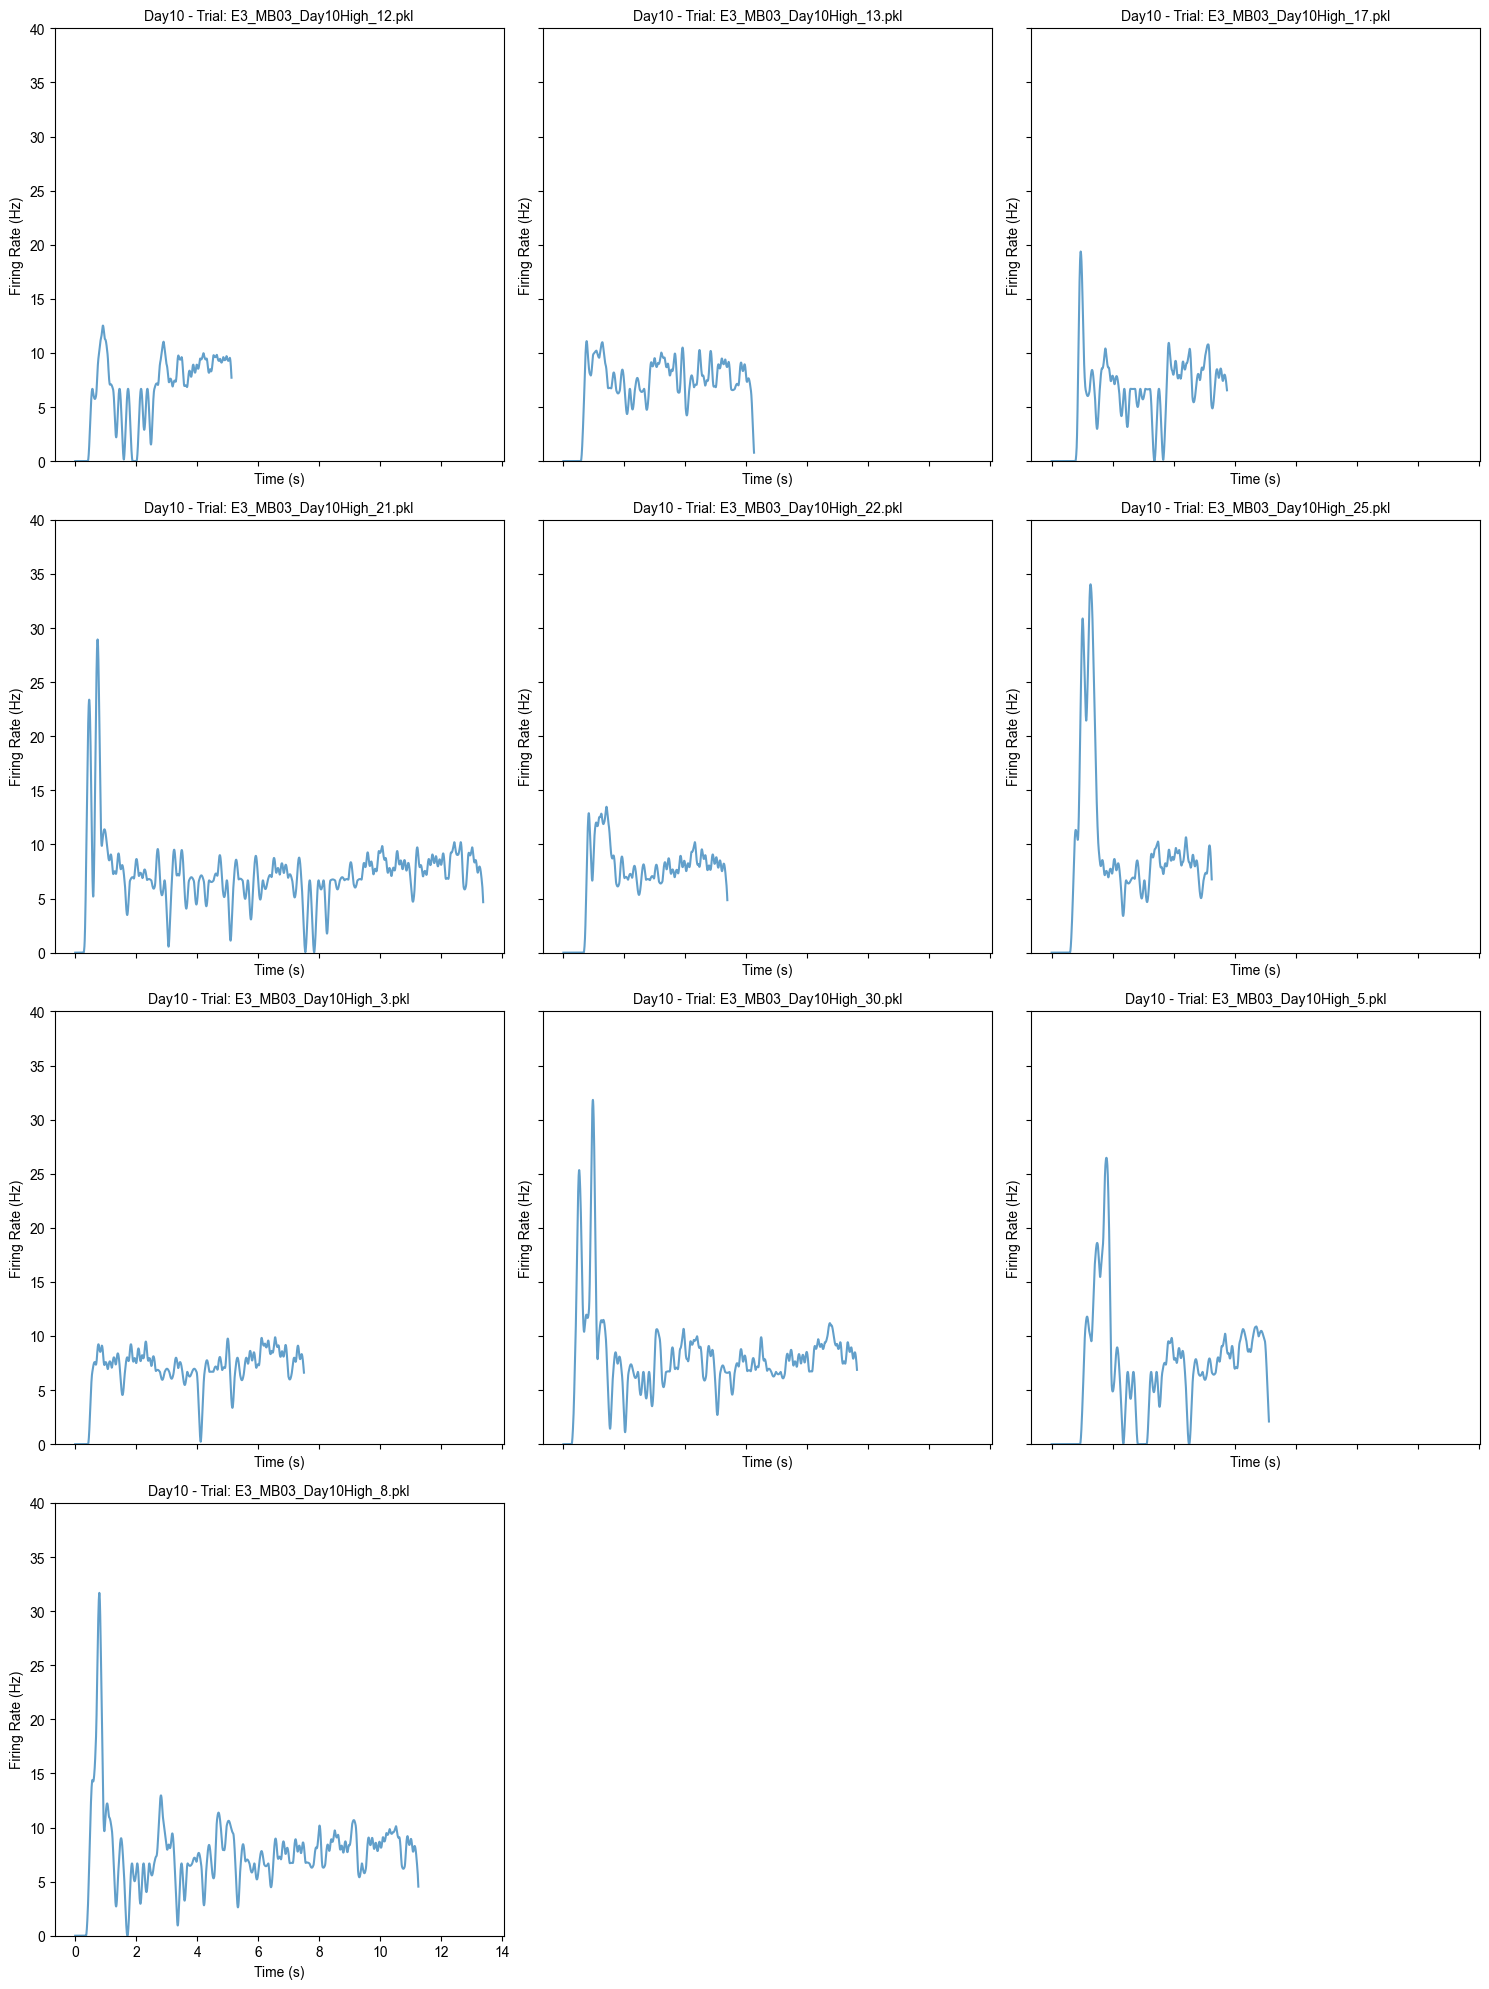

Plotting Day11 with 10 trials...
7.0743645873333545
7.208307957428116
7.496529255610339
6.680790776407973
7.427300552041024
6.312922947647693
4.948754203201637
7.976775856256125
6.199779624370597
7.250820702502466


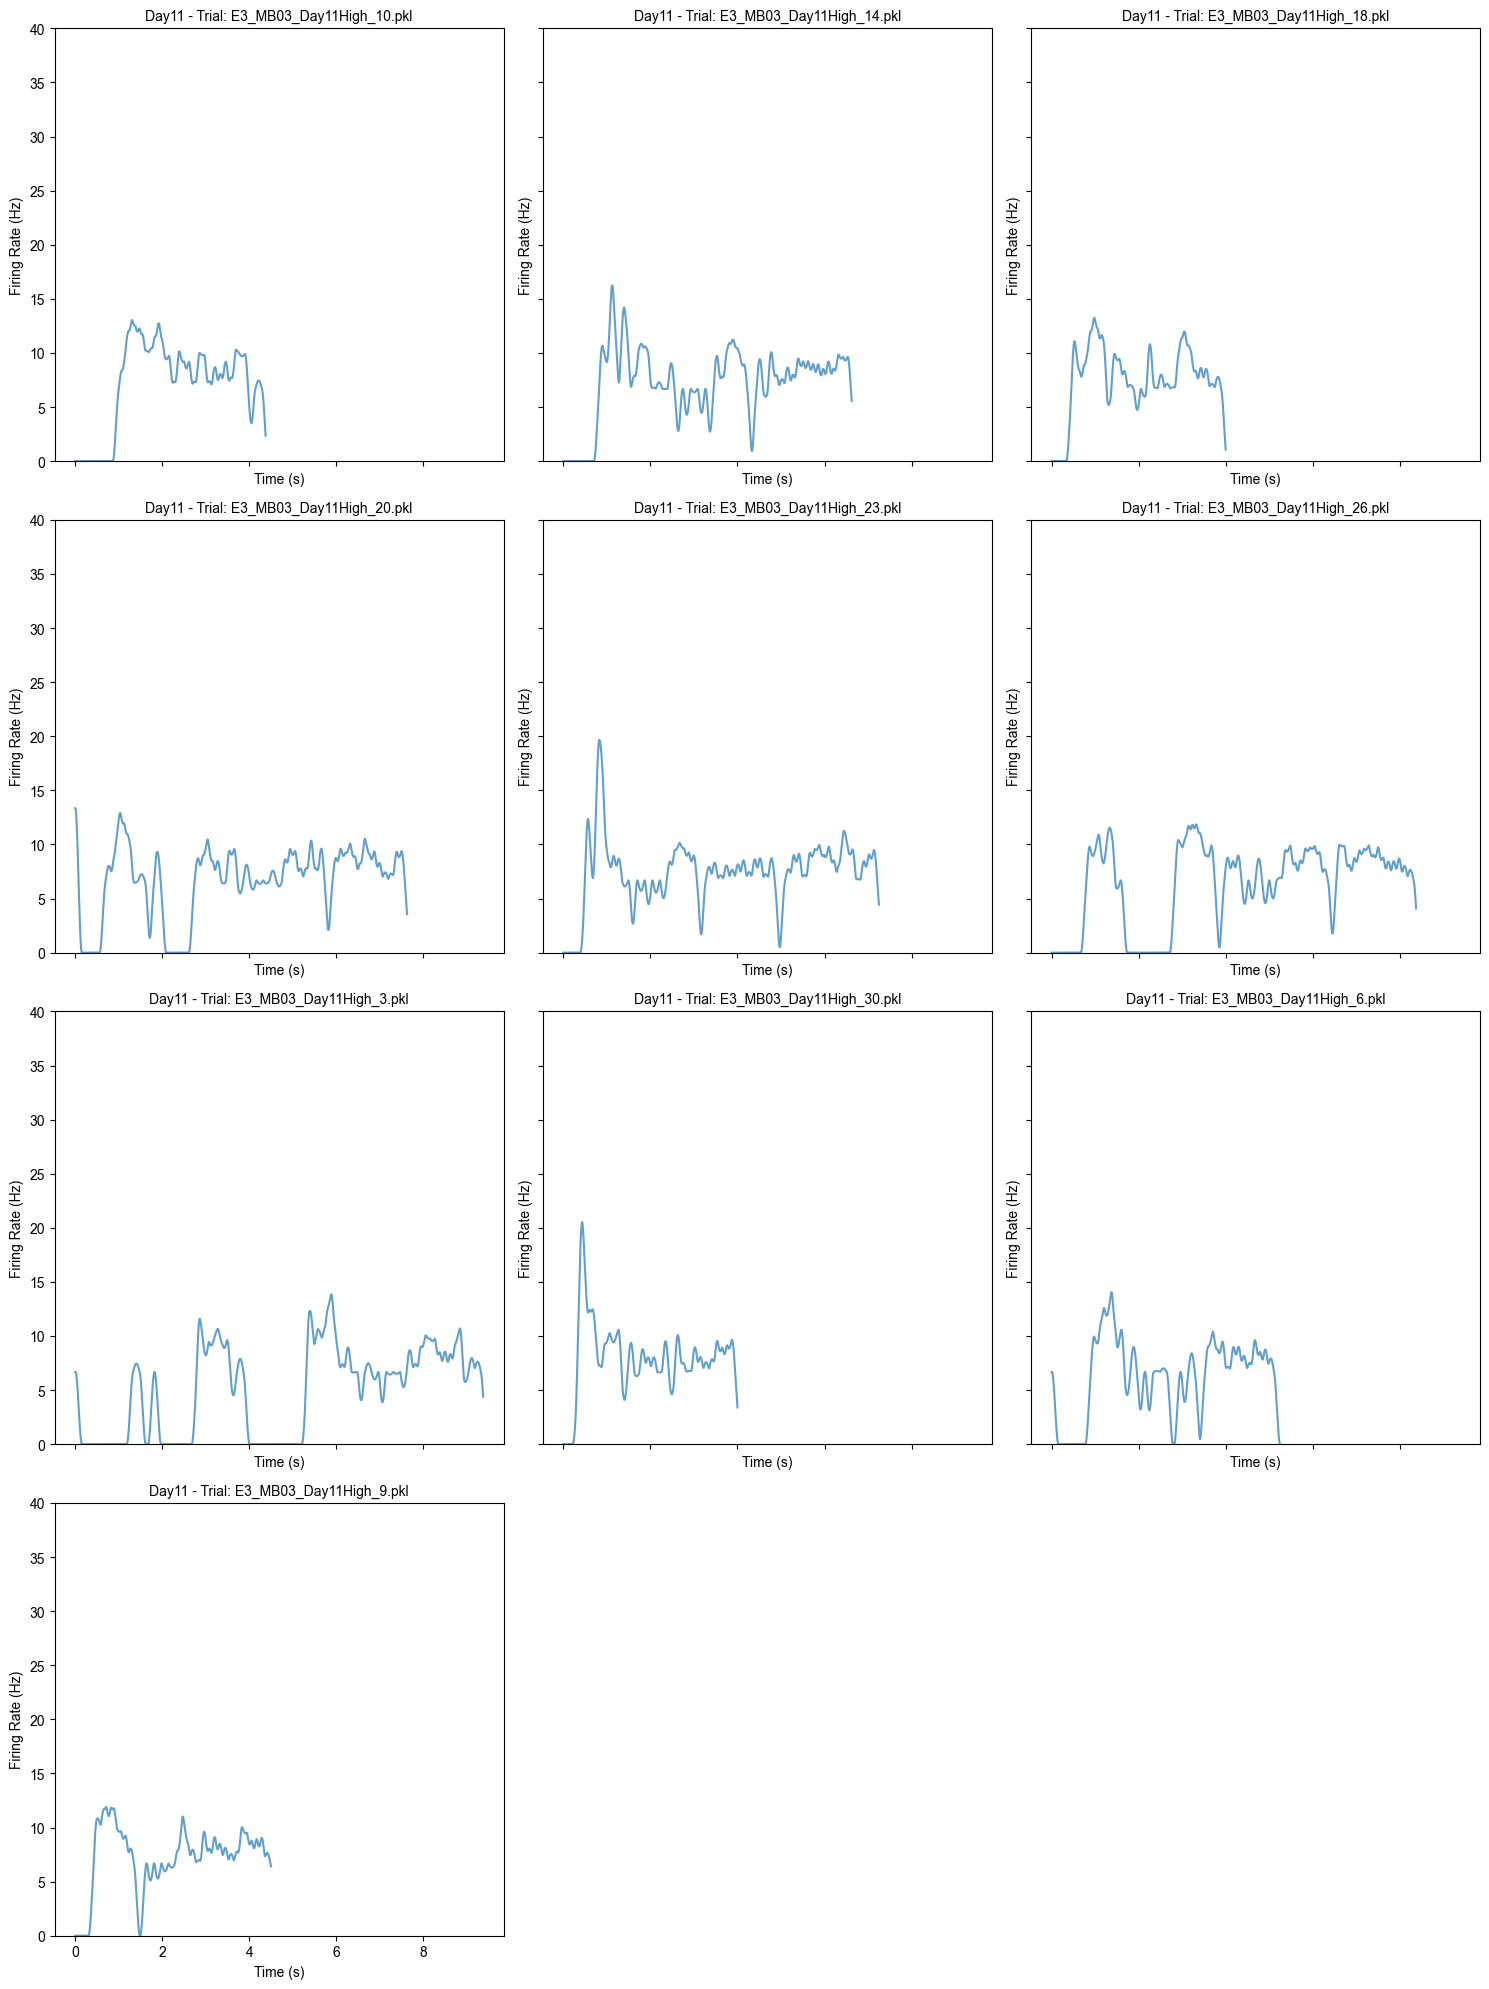

Plotting Day12 with 10 trials...
8.530247793493208
8.10241677246252
7.846962520987648
5.242156754357917
7.8121105319213635
8.083034701659946
7.744068407494133
8.126473620602729
7.610238672467403
6.396489177332678


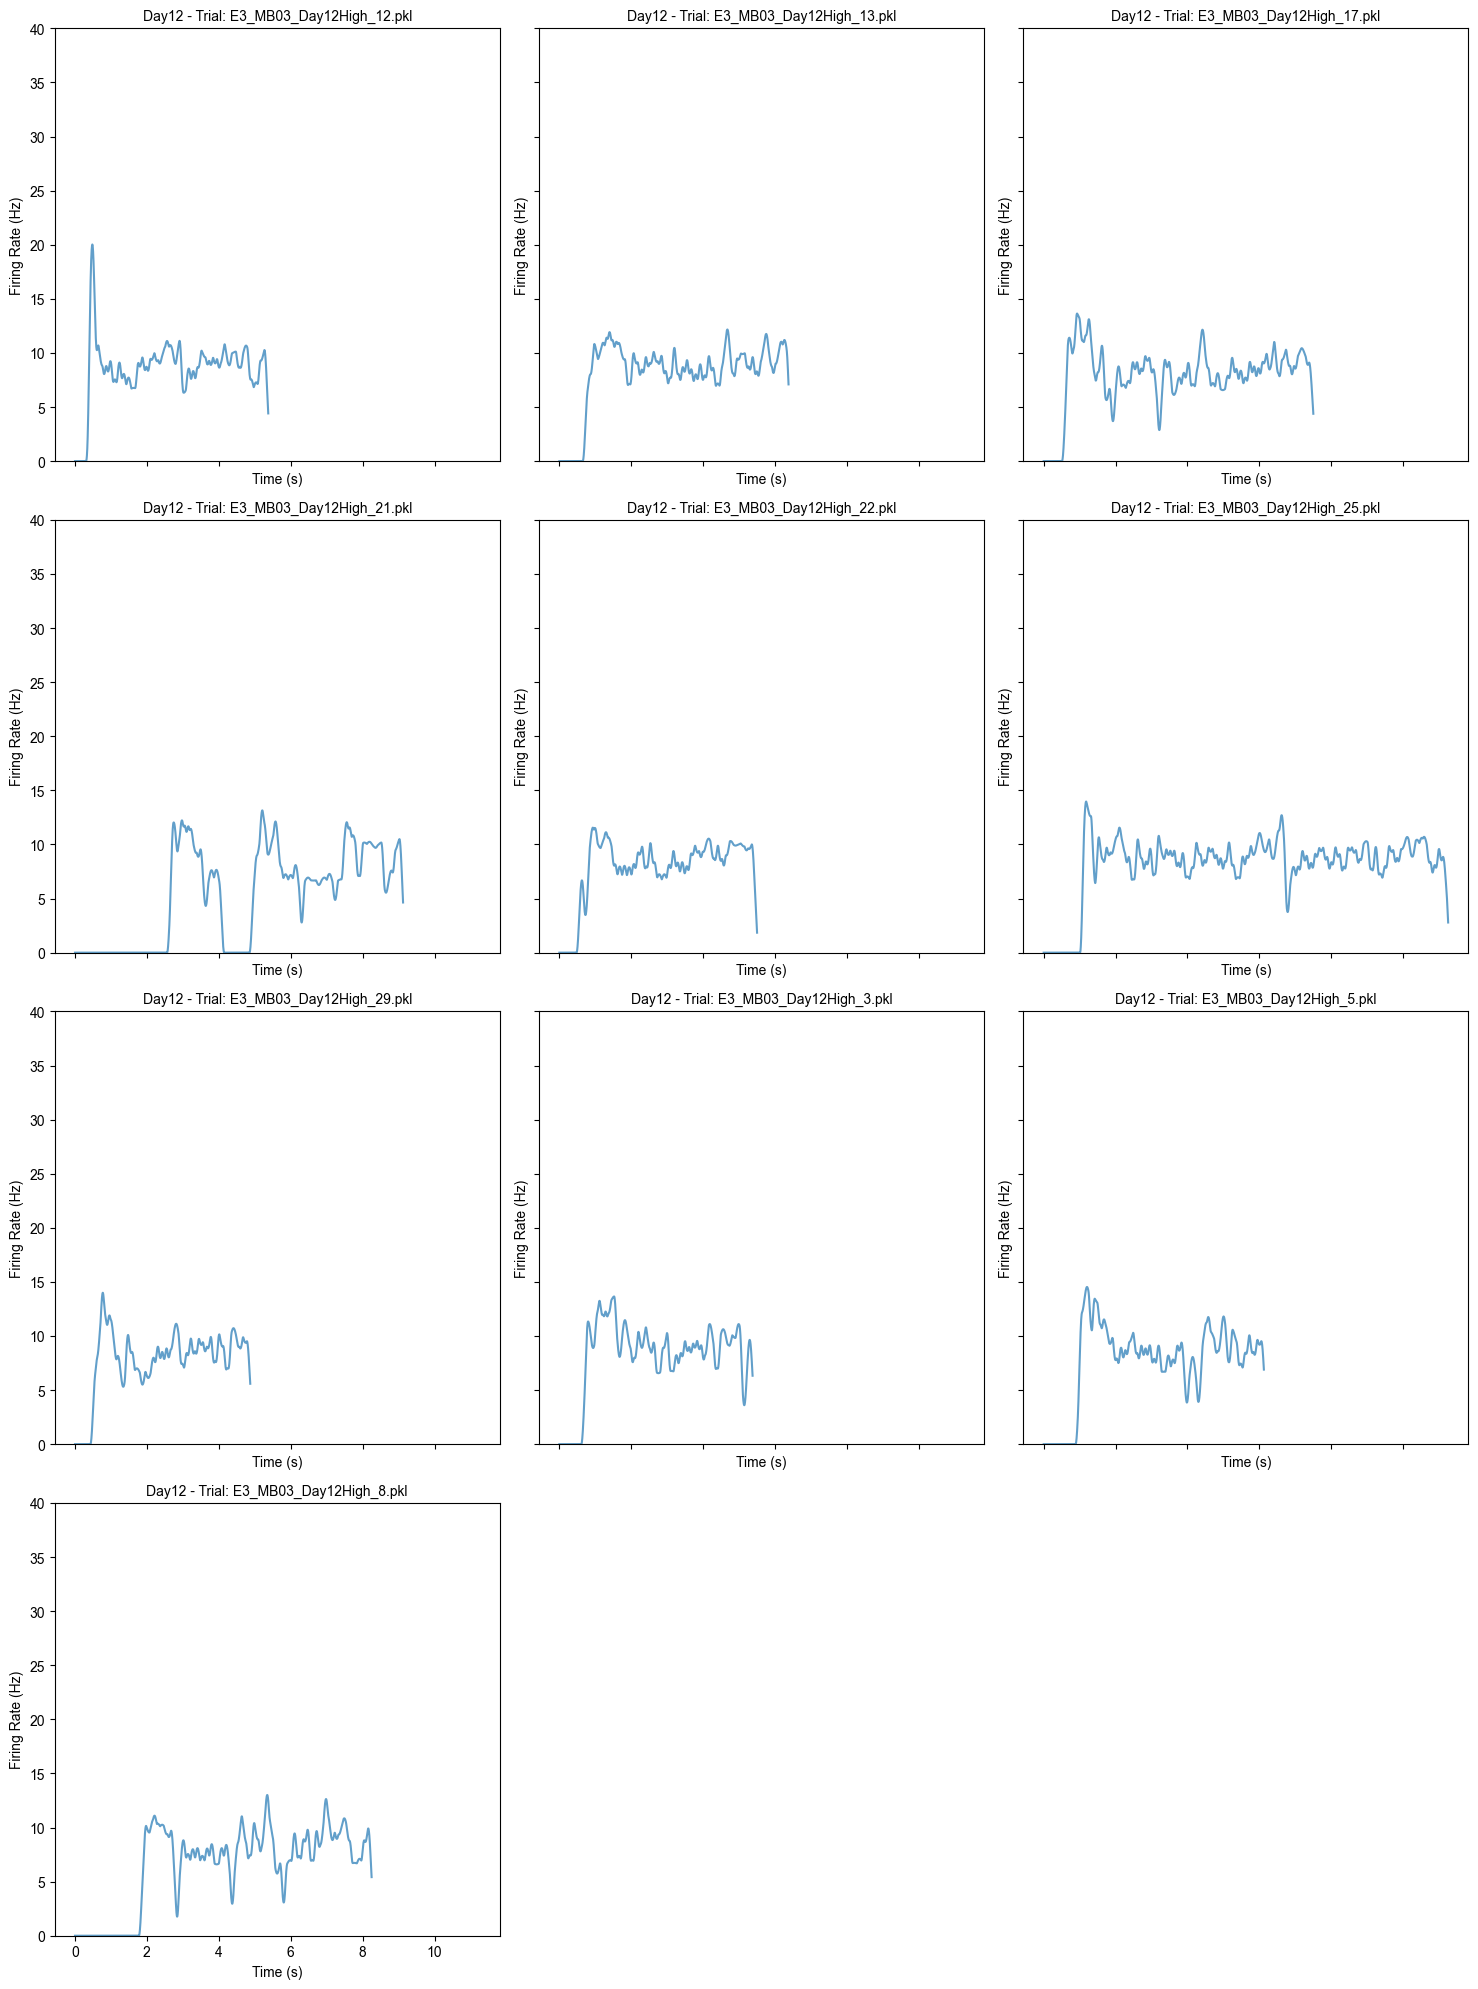

Plotting Day13 with 10 trials...
6.508171217622125
6.476189986563428
7.640355664219029
7.6398599781179515
7.4805040451757785
7.965573527155751
7.960970051671451
7.302427240719913
7.1925915918007695
8.166849432020951


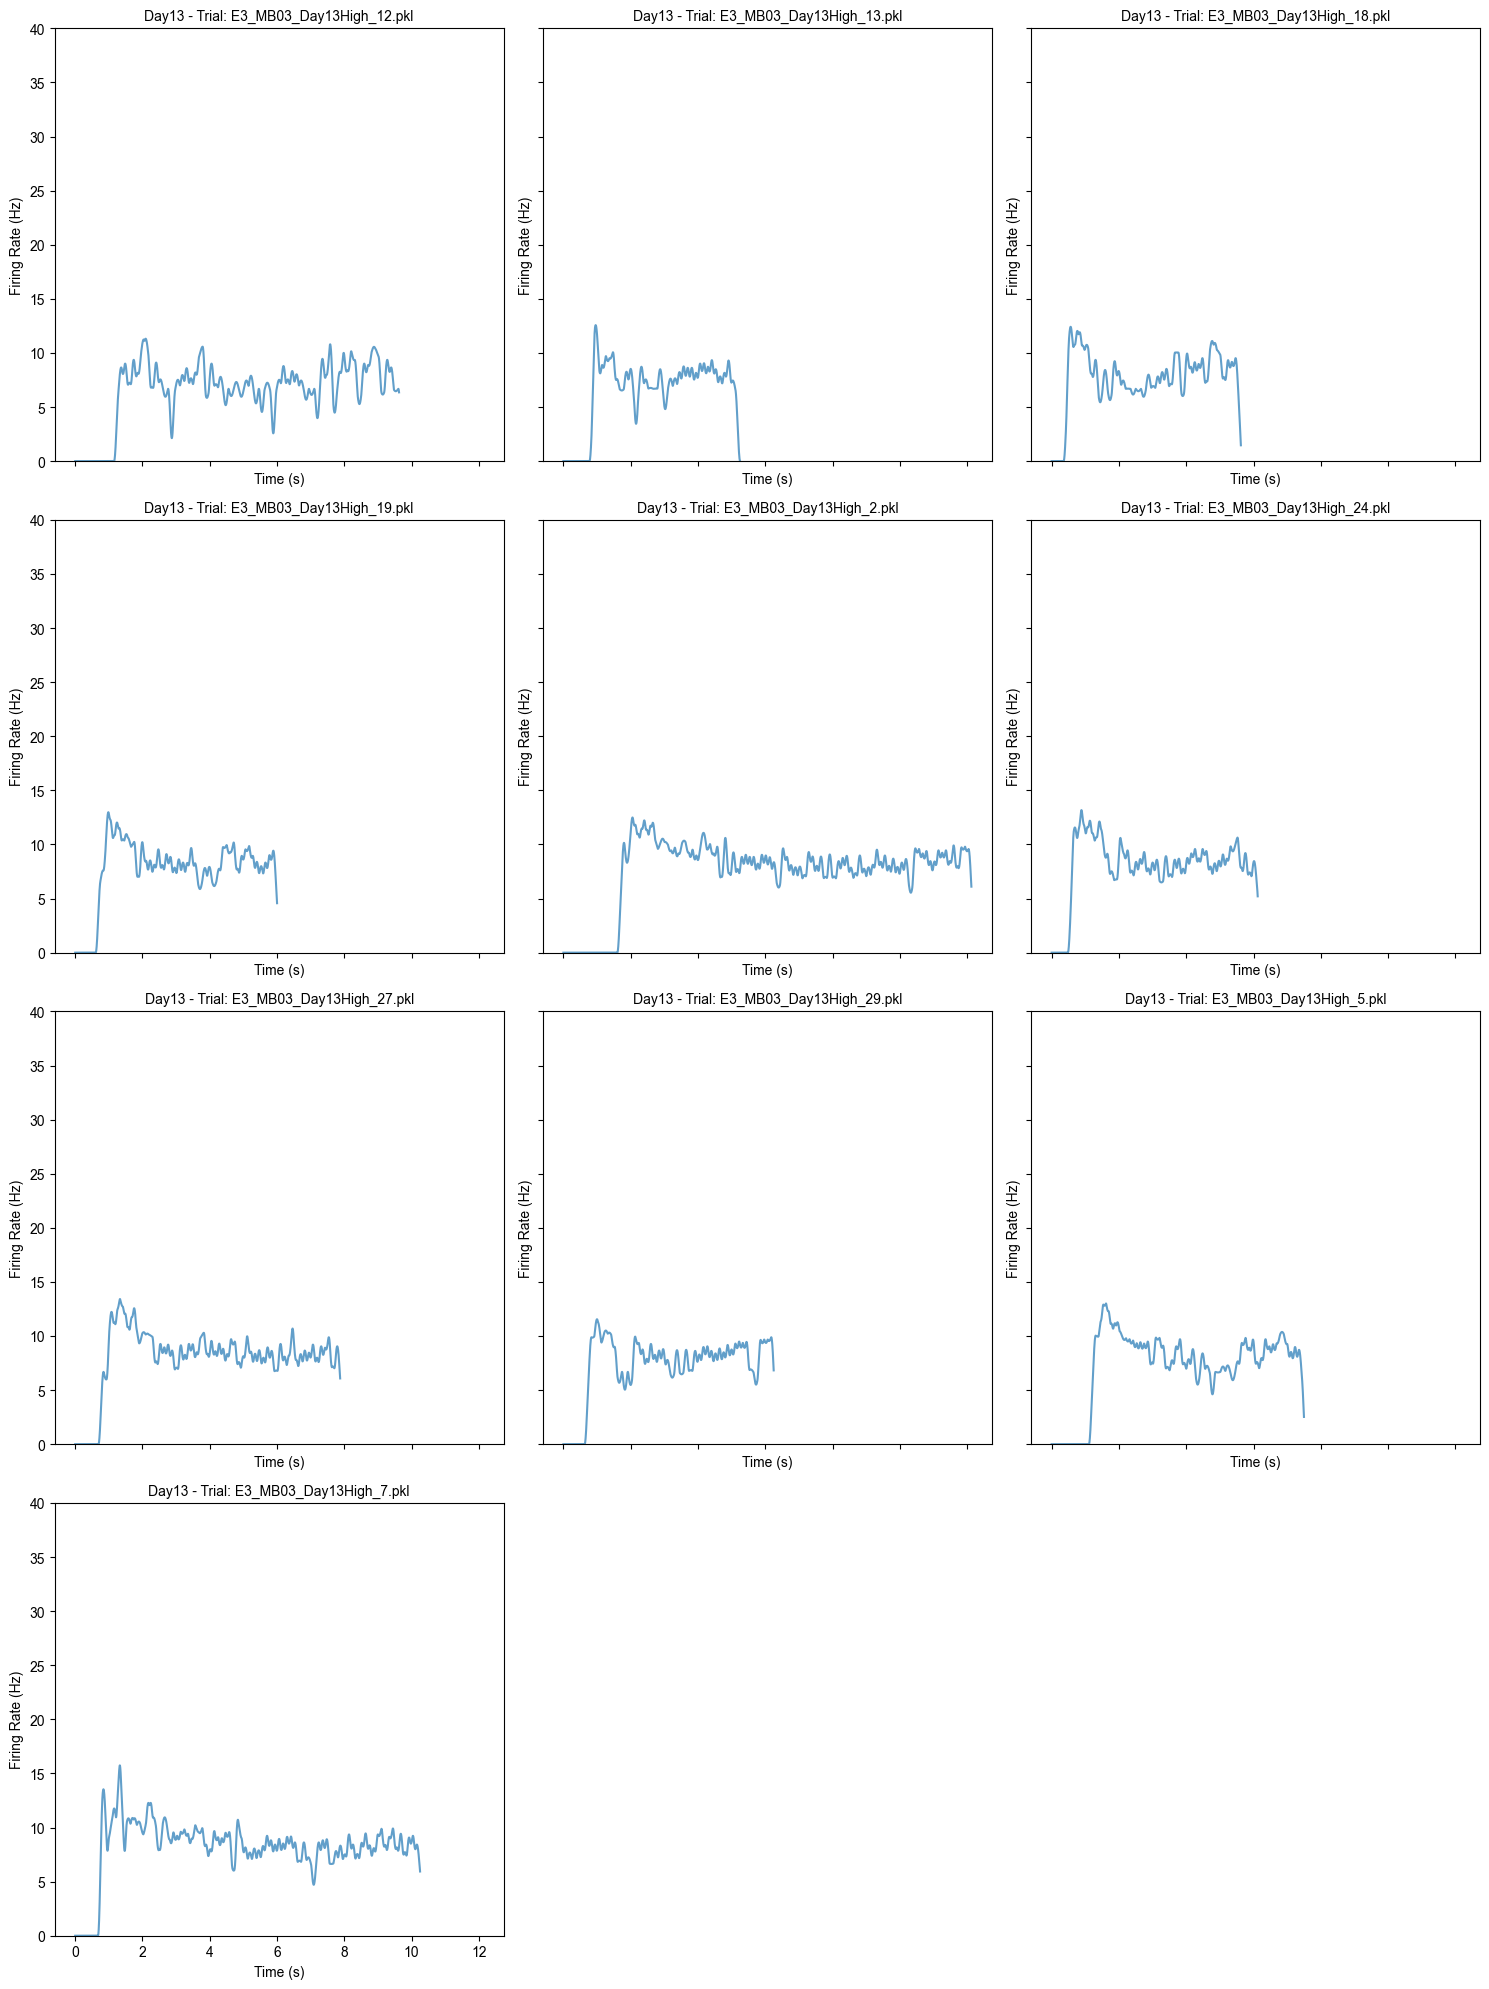

Plotting Day14 with 10 trials...
5.775546649979271
6.274736537546652
4.609063982388451
8.396631259128377
7.929979413589168
7.813638239111295
7.553435843770123
9.670604781093813
7.795544095136964
8.986941784997848


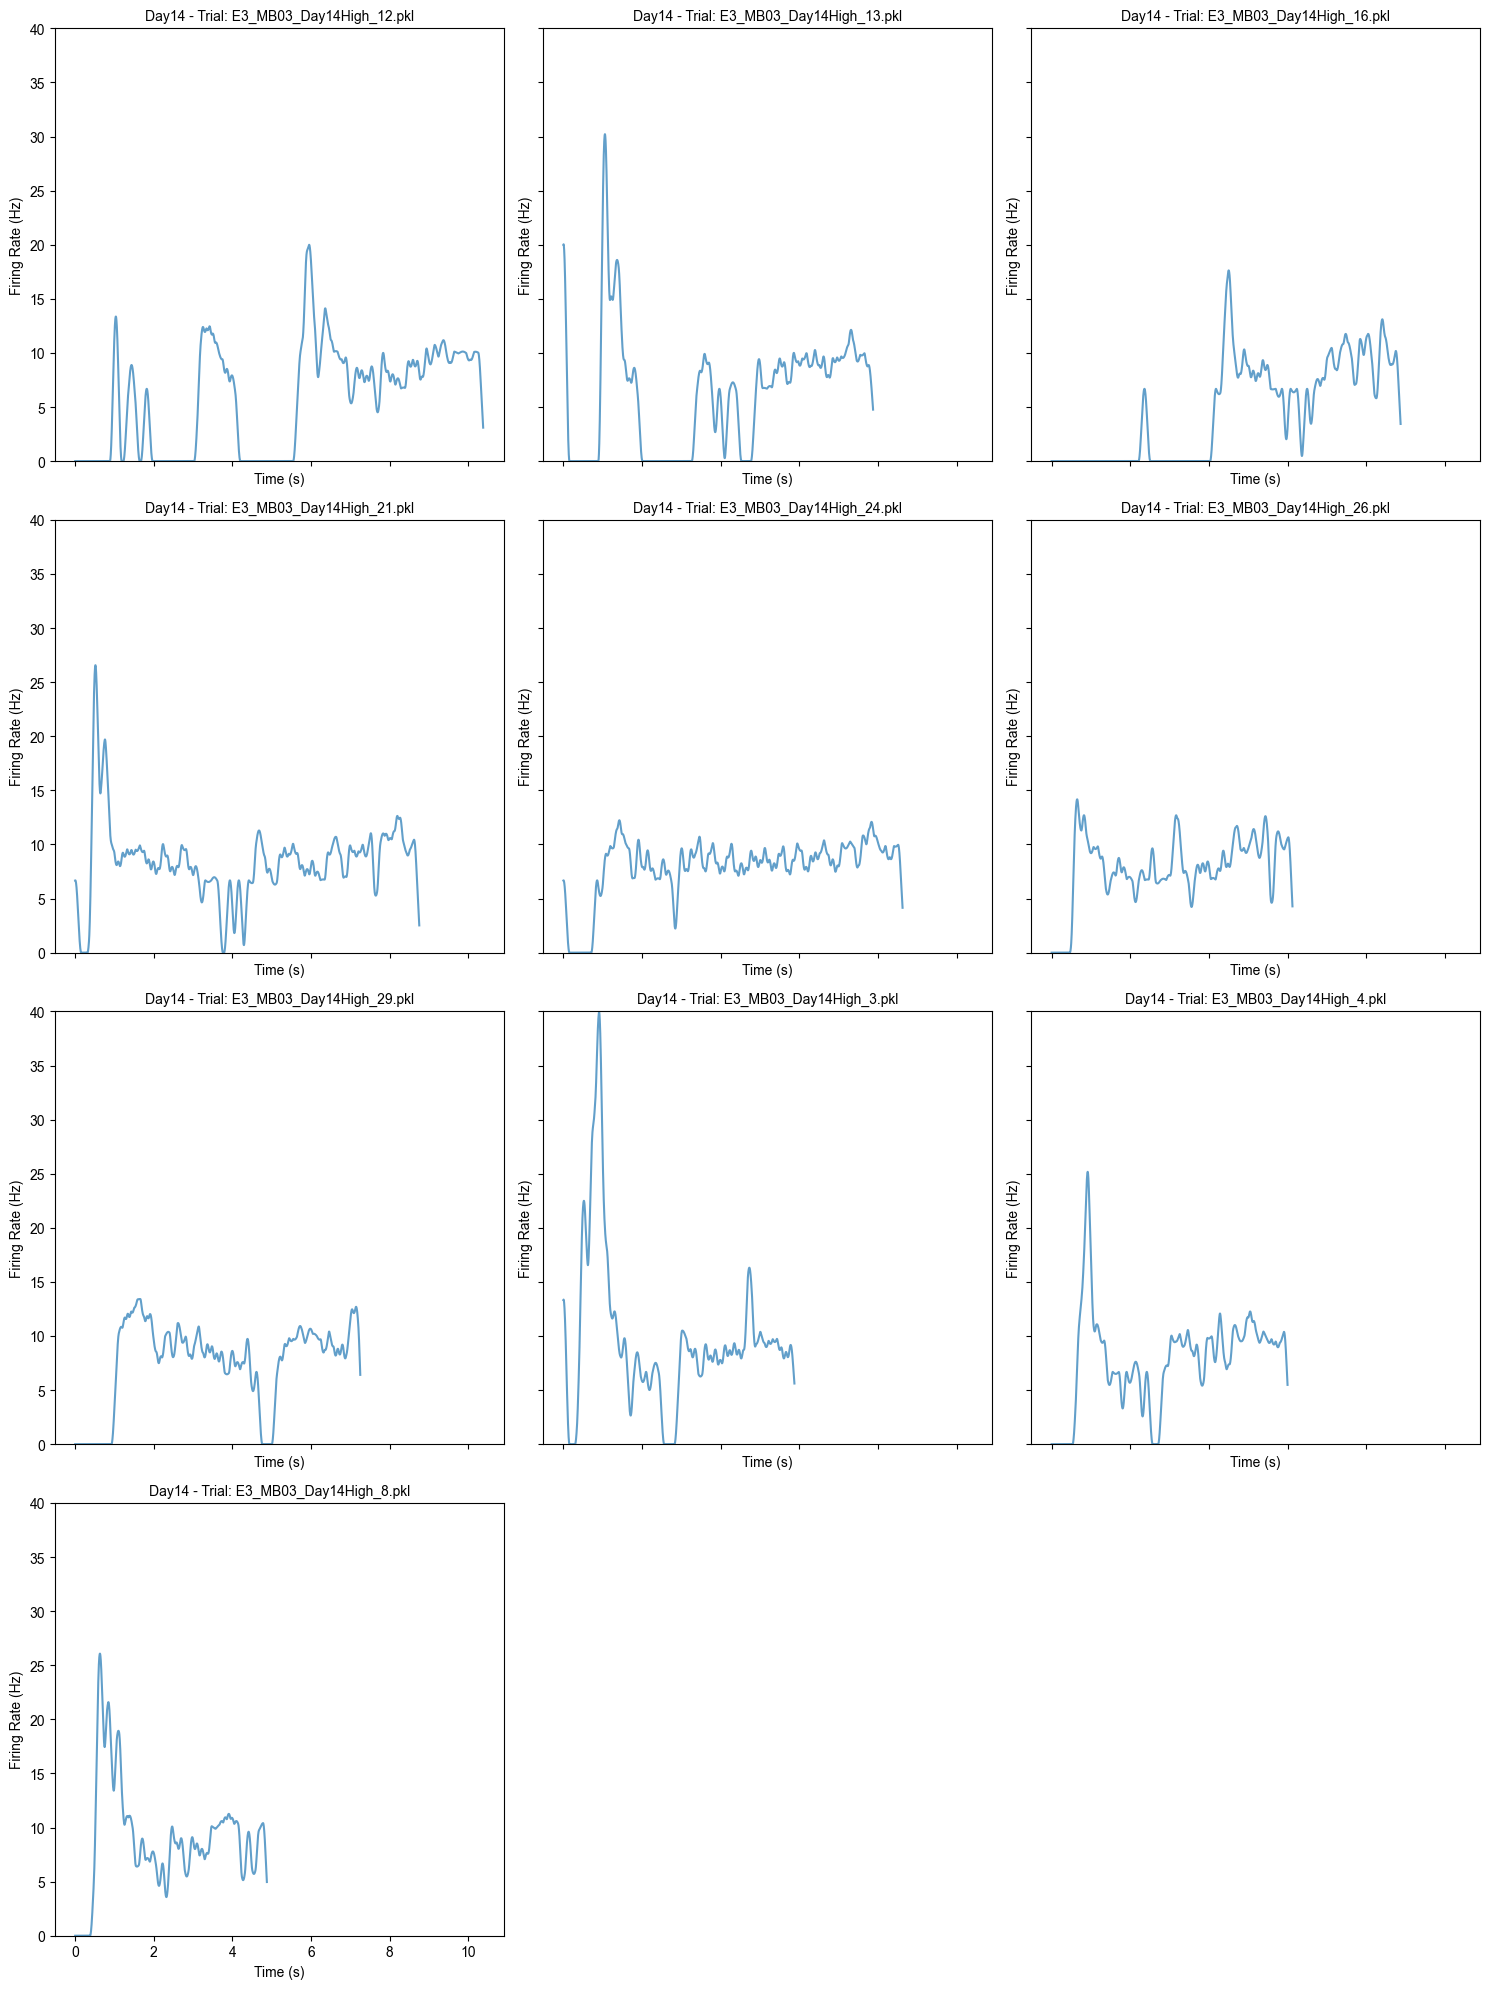

In [343]:
def plot_firing_rates(folder_path, pkl_files, fsamp=2048, window_duration=0.3, session_label=''):
    num_files = len(pkl_files)      
    cols = 3  # Number of columns for subplots
    rows = math.ceil(num_files / cols)  # Compute number of rows

    fig, axes = plt.subplots(rows, cols, figsize=(15, 5 * rows), sharex=True, sharey=True)
    axes = axes.flatten()

    for idx, file in enumerate(pkl_files):
        file_path = os.path.join(folder_path, file)

        with open(file_path, 'rb') as f:
            data = pickle.load(f)

        data_MU = np.array(data['MU'].tolist())  
        smoothed_firing_rates = compute_firing_rates(data_MU, fsamp, window_duration)
        idx_pair = data['Idx_MU_Pair'].tolist()

        ax = axes[idx]
        time_axis = np.arange(data_MU.shape[1]) / fsamp  # Convert sample index to time in seconds

        for neuron_idx in range(data_MU.shape[0]):
            if neuron_idx==idx_pair[1]:
                ax.plot(time_axis, smoothed_firing_rates[neuron_idx, :], label=f'Neuron {neuron_idx}', alpha=0.7)
                print(np.mean(smoothed_firing_rates[neuron_idx, :]))
                
        num_neurons = data_MU.shape[0]  # Count the number of motoneurons
        ax.set_title(f'{session_label} - Trial: {file}', fontsize=10)

        ax.set_xlabel('Time (s)')
        ax.set_ylabel('Firing Rate (Hz)')

    # Remove unused subplots
    for j in range(idx + 1, len(axes)):
        fig.delaxes(axes[j])  

    plt.tight_layout()
    plt.ylim([0, 40])
    plt.show()

for session_name, file_list in session_files3.items():
    folder_path = "/Users/nmt121/Desktop/DATA/S3"   # Adjust if needed
    print(f"Plotting {session_name} with {len(file_list)} trials...")
    
    plot_firing_rates(folder_path=folder_path,pkl_files=file_list,fsamp=2048,window_duration=0.3,session_label=session_name)
